# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Titanic  

**Выполнил:** Толмачев Виталий Владимирович 
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Dittalik/ml-course-tolmachev.git
**Путь к модулю:** `module-4-features/notebook.ipynb`  
**Дата сдачи:** 2026-29-10

## Введение

**Какую задачу решаем.** Интернет-магазин фиксирует поведение посетителей: сколько страниц каждого типа открыто, сколько времени на них проведено, какие показатели отказов и выходов у страниц, в каком месяце и с какого устройства пришёл посетитель. Задача — **бинарная классификация сессии**: завершится ли она покупкой (`Revenue = True`, класс 1) или нет (класс 0). Модель получает на вход данные о сессии и выдаёт вероятность покупки.

**Что такое инженерия признаков.** Это создание новых информативных признаков из исходных данных и подготовка существующих: суммы, средние, отношения, бинарные флаги, извлечение месяца или дня недели, кодирование категорий. Модель может обучиться только на том, что ей показали, поэтому хорошо подобранные признаки часто дают больший прирост качества, чем смена алгоритма или тонкая настройка параметров.

**Почему для IT-компании важно прогнозировать покупку.** Пока посетитель ещё на сайте, у компании есть шанс повлиять на исход: показать персональную скидку, предложить онлайн-чат, напомнить о товарах в корзине. Предсказание помогает тратить бюджет там, где он окупается: не давать скидку тем, кто и так купит, и не тратить усилия на тех, кто точно уйдёт. Кроме того, вероятности покупки помогают оценивать эффективность каналов трафика и качество страниц сайта, а значимые признаки показывают, что именно в поведении отличает покупателей от остальных.

**Какая метрика важнее.** Классы несбалансированы: покупок около 15.5%. *Accuracy* здесь обманчива: модель, всегда отвечающая «покупки не будет», получит около 84.5% точности и бесполезна для бизнеса. *Precision* показывает, какая доля предсказанных покупок реальна (важно, если каждое «ложное» предсказание стоит денег, например скидка), *Recall* — какую долю реальных покупок мы нашли, а *F1* уравновешивает их при выбранном пороге. **ROC-AUC** оценивает качество ранжирования сессий по вероятности покупки независимо от порога и не зависит от пропорции классов, поэтому берём её **главной метрикой** (в том числе для подбора гиперпараметров), а F1, Precision и Recall используем как дополнительные.

**Цели работы:**
1. Создать 5+ новых признаков на основе поведения пользователя, обосновать каждый и измерить их вклад в качество.
2. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost), сравнить их и оптимизировать лучшую через Optuna.
3. Интерпретировать лучшую модель через Feature Importance и SHAP и сформулировать выводы для e-commerce.

## Теоретическая часть

### Feature Engineering
Feature Engineering — это процесс превращения «сырых» данных в признаки, на которых модель учится лучше. Он включает создание новых признаков (суммы, отношения, флаги), преобразование существующих (логарифм, масштабирование), кодирование категорий и извлечение компонентов даты и времени. В IT-продуктах он особенно важен: логи и события обычно хранятся в виде отдельных записей, а модели нужны агрегаты по сессии, пользователю или периоду. Деревья решений плохо «додумывают» арифметику между столбцами (например, отношение или сумму двух признаков), поэтому такие признаки полезно задавать явно. Хорошие признаки опираются на знание предметной области: сначала формулируют гипотезу («длинная сессия на товарных страницах говорит о намерении купить»), затем превращают её в признак и проверяют эффект на валидации.

### Категориальные признаки: Label Encoding vs One-Hot Encoding
Модели работают с числами, поэтому категории нужно закодировать. **Label Encoding** заменяет категорию целым числом (`Feb → 0`, `Mar → 1`, ...): компактно, но вводит искусственный порядок, который вредит линейным моделям и расстояниям. Деревья справляются лучше, так как делят значения по порогам. **One-Hot Encoding** создаёт бинарный столбец на каждую категорию: порядка нет, но при большом числе категорий признаков становится слишком много. Для категорий с большим числом значений применяют **Target Encoding** (замена категории средним значением целевой переменной внутри неё): он компактен, но требует кросс-валидационной схемы, иначе происходит утечка таргета. В нашем датасете `OperatingSystems`, `Browser`, `Region`, `TrafficType` — идентификаторы без порядка; `VisitorType` кодируем One-Hot, а Target Encoding проверим как бонус.

### Временные признаки
Дата и время несут сезонность и ритм поведения: в пятницу вечером и в канун праздников люди покупают иначе, чем во вторник утром. Из временной отметки извлекают месяц, день недели, час, признак выходного дня, близость к праздникам. Месяц можно передавать числом (1–12), а для цикличных величин (месяц, час) бывает полезно представление через синус и косинус, чтобы декабрь и январь оказались «рядом». В нашем датасете время представлено строкой `Month`, флагом `Weekend` и числом `SpecialDay` (близость к особому дню), из которых мы получаем `MonthNum` и `IsWeekend`.

### Признаки на основе поведения пользователя
Исходные метрики сессии (число страниц и время по типам) можно агрегировать: **суммы** (`TotalPages`, `TotalDuration`) дают общую вовлечённость, **средние** (время на страницу) показывают интенсивность просмотра, а **отношения** (доля товарных страниц, `BounceRates / ExitRates`) выражают структуру поведения независимо от масштаба сессии. Отношения полезны, потому что сравнивают пользователей с разной длительностью сессий на равных. Чтобы не делить на ноль, к знаменателю добавляют малую константу (+1 или +0.001). Бинарные флаги («новый посетитель», «выходной») упрощают модели правило «если ... то ...» и облегчают интерпретацию.

### Дисбаланс классов
Если одного класса заметно больше (у нас 84.5% против 15.5%), модель, минимизирующая общую ошибку, склонна игнорировать редкий класс: высокая Accuracy достигается ценой почти нулевого Recall. Поэтому метрики выбирают с учётом дисбаланса (ROC-AUC, F1, Precision/Recall) и применяют специальные приёмы. **Взвешивание классов** (`class_weight='balanced'`, `scale_pos_weight`) увеличивает штраф за ошибки на редком классе. **Ресемплинг** меняет сами данные: случайное дублирование редкого класса (oversampling), удаление части частого (undersampling) или синтетическое создание новых примеров (SMOTE). Дополнительно можно сдвигать порог классификации и калибровать вероятности. Все такие приёмы применяют только к обучающей выборке, иначе тестовая оценка станет нечестной.

### SHAP
SHAP основан на значениях Шепли из теории кооперативных игр: вклад признака определяется как его средний предельный вклад в предсказание по всем порядкам добавления признаков. Для объекта сумма SHAP-значений всех признаков плюс базовое значение (среднее предсказание модели) равна предсказанию модели, поэтому разбор получается аддитивным и согласованным. Для ансамблей деревьев есть быстрый точный алгоритм `TreeExplainer`. Основные графики: **summary plot** (глобальная важность и направление влияния признаков), **bar plot** (средний модуль SHAP), **waterfall plot** (разбор одного предсказания по шагам), **dependence plot** (как значение одного признака влияет на предсказание и с чем взаимодействует). Для LightGBM значения измеряются в лог-шансах, а не напрямую в вероятностях.

### Ансамбли: Bagging и Boosting (кратко)
**Bagging** обучает модели независимо на бутстрэп-выборках и усредняет ответы, снижая дисперсию; **Boosting** строит модели последовательно, каждая исправляет ошибки предыдущих, снижая смещение.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

Здесь $h_i(x)$ — базовая модель, $M$ — их число, $\alpha_i$ — вес модели в композиции.

| Свойство | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
| Построение деревьев | независимо, параллельно | последовательно, по уровням | последовательно, по листьям | последовательно, симметричные деревья |
| Скорость обучения | средняя | средняя | **высокая** | ниже (на CPU) |
| Категориальные признаки | нужно кодировать | нужно кодировать | ограниченная поддержка | **нативная поддержка** |
| Борьба с дисбалансом | `class_weight` | `scale_pos_weight` | `class_weight` | `auto_class_weights` |
| Настройка | почти не нужна | нужна | нужна | часто хорош «из коробки» |

### Другие виды инженерии признаков (в этом датасете не применяются)
В датасете нет текста, координат и временных рядов, поэтому следующие приёмы здесь не нужны, но входят в общий арсенал:
- **TF-IDF** превращает текст в числа: вес слова $t$ в документе $d$ равен $\text{tf}(t,d) \cdot \log \frac{N}{\text{df}(t)}$, то есть частота слова в документе, умноженная на редкость слова во всём корпусе.
- **Формула гаверсинуса (Haversine)** считает расстояние между двумя точками на сфере по широте $\varphi$ и долготе $\lambda$: $d = 2R \arcsin \sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\frac{\Delta\lambda}{2}}$.
- **DBSCAN** — кластеризация по плотности: точки с не менее чем `min_samples` соседями в радиусе `eps` образуют ядро кластера; редкие точки помечаются шумом. Метки кластеров используют как новый категориальный признак.
- **Лаги и скользящие окна** для временных рядов: лаг $x_{t-k}$ — значение $k$ шагов назад, скользящее среднее $\frac{1}{w}\sum_{i=0}^{w-1} x_{t-i}$ сглаживает шум; признаки считают только по прошлому, чтобы не допустить утечки из будущего.

### Схема подходов
```
Сырые данные сессии ─► очистка ─► новые признаки ─► кодирование ─► модели ─► метрики ─► SHAP
 (17 столбцов)          (-1 в       (суммы, отношения,  (One-Hot,       (RF, XGB,   (ROC-AUC,   (что именно
                         длит.)      флаги, месяц)       месяц→число)    LGBM, Cat)  F1, ...)    влияет)
```

## Описание данных

**Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention (оригинал: UCI Machine Learning Repository, Online Shoppers Purchasing Intention Dataset, ID 468; авторы Sakar C. O., Polat S., Katircioglu M., Kastro Y., 2018).

Файл `online_shoppers_intention.csv` сохранён как `data/online_shoppers_intention.csv`. Ниже подключаем библиотеки и загружаем данные.

In [1]:
# Базовые библиотеки
import os                                      # работа с файлами и папками
import json                                    # чтение/запись JSON-файлов
import time                                    # замер времени обучения
import warnings                                # управление предупреждениями

import numpy as np                             # числовые массивы
import pandas as pd                            # таблицы данных (DataFrame)
import matplotlib.pyplot as plt                # графики
import seaborn as sns                          # статистические графики
import joblib                                  # сохранение и загрузка моделей
from IPython.display import Markdown, display  # красивый вывод Markdown-таблиц в ноутбуке

warnings.filterwarnings('ignore')              # убираем лишние предупреждения в выводе
sns.set_theme(style='whitegrid')               # единый стиль графиков
plt.rcParams['figure.dpi'] = 100               # разрешение графиков в ноутбуке
RANDOM_STATE = 42                              # единый seed для воспроизводимости

# Порядок месяцев; в датасете июнь записан как 'June', остальные — трёхбуквенно
MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
    # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
    cols = list(frame.columns)                                     # заголовки столбцов
    rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
            '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
    for _, r in frame.iterrows():                                  # по строкам таблицы
        rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
            f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
    return '\n'.join(rows)                                         # собираем таблицу в одну строку

# Папки модуля (ноутбук лежит в module-4-features/, поэтому пути относительные)
for folder in ['data', 'models', 'examples']:                      # создаём рабочие папки модуля
    os.makedirs(folder, exist_ok=True)                             # exist_ok — без ошибки, если папка уже есть

In [2]:
# Загрузка датасета
csv_path = 'data/online_shoppers_intention.csv'    # относительный путь внутри module-4-features/
if not os.path.exists(csv_path):                   # если файла нет — останавливаемся с понятной ошибкой
    raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
        'Положите файл в data/online_shoppers_intention.csv '  # инструкция пользователю
        '(https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention)')  # ссылка на датасет

df = pd.read_csv(csv_path)                         # читаем CSV в DataFrame

print(df.shape)                                    # (строки, столбцы)
print(df.head())                                   # первые 5 строк

(12330, 18)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10         0.0         

In [3]:
# Статистика датасета: типы признаков и распределение классов
target_counts = df['Revenue'].value_counts()                      # абсолютные частоты классов (False/True)
target_share = df['Revenue'].value_counts(normalize=True) * 100   # доли в процентах

# 10 числовых признаков (счётчики, длительности, метрики Google Analytics)
num_features = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',  # числовые признаки
                'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
# Остальные признаки (кроме целевой) считаем категориальными: Month, OperatingSystems, Browser, Region,
# TrafficType, VisitorType, Weekend
cat_features = [c for c in df.columns if c not in num_features + ['Revenue']]  # остальные признаки считаем категориальными

print(f'Примеров: {len(df)}')                                                  # число строк
print(f'Признаков (без Revenue): {len(num_features) + len(cat_features)}')      # число входных признаков
print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')    # разбивка по типам
print('Категориальные:', cat_features)                                          # какие именно
print()  # пустая строка
print('Распределение классов:')                                                 # заголовок блока
for cls in target_counts.index:                                                 # по каждому классу
    print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')          # число и доля класса

# Описание датасета сохраняем в data/dataset_info.md (требование задания)
info_md = f"""# Online Shoppers Purchasing Intention — описание датасета

**Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention
(оригинал: UCI Machine Learning Repository, ID 468)

- Примеров (сессий): {len(df)}
- Признаков: {len(num_features) + len(cat_features)} (+ целевая Revenue)
- Числовых: {len(num_features)} ({', '.join(num_features)})
- Категориальных: {len(cat_features)} ({', '.join(cat_features)})

## Распределение классов
- False (нет покупки): {target_counts.get(False, 0)} ({target_share.get(False, 0):.1f}%)
- True (покупка): {target_counts.get(True, 0)} ({target_share.get(True, 0):.1f}%)

Дисбаланс сильный, поэтому используются взвешивание классов и метрика ROC-AUC.
"""
with open('data/dataset_info.md', 'w', encoding='utf-8') as f:    # открываем файл для записи
    f.write(info_md)                                              # записываем описание датасета
print('\n✅ data/dataset_info.md сохранён')                         # подтверждение сохранения

Примеров: 12330
Признаков (без Revenue): 17
Числовых: 10, категориальных: 7
Категориальные: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Распределение классов:
  False: 10422 (84.5%)
  True: 1908 (15.5%)

✅ data/dataset_info.md сохранён


**Структура:**
- Всего примеров (сессий): 12 330
- Признаков: 17 (+ целевая `Revenue`)
- Числовых признаков: 10
- Категориальных признаков: 7 (`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `Weekend`)

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Administrative | int | Число посещённых административных страниц | 0% |
| Administrative_Duration | float | Время на административных страницах (сек) | 0% (но возможны значения -1, см. EDA) |
| Informational | int | Число информационных страниц | 0% |
| ProductRelated | int | Число товарных страниц | 0% |
| BounceRates | float | Показатель отказов | 0% |
| ExitRates | float | Показатель выходов | 0% |
| PageValues | float | Средняя ценность страницы перед транзакцией | 0% |
| SpecialDay | float | Близость к особому дню (0–1) | 0% |
| Month | object | Месяц сессии (`Feb`, `Mar`, ..., `June`, ...) | 0% |
| VisitorType | object | Тип посетителя (New, Returning, Other) | 0% |
| Weekend | bool | Выходной ли день | 0% |
| Revenue | bool | **Целевая** (True = покупка) | 0% |

**Распределение классов:** False (нет покупки) — 10 422 (84.5%), True (покупка) — 1 908 (15.5%). Дисбаланс сильный (≈5.4 : 1), поэтому далее используем взвешивание классов, а главной метрикой выбираем ROC-AUC. Точные значения по вашему файлу выводит ячейка выше.

**Файл с описанием в репозитории:** `module-4-features/data/dataset_info.md` (создаётся ячейкой выше).

## Подготовка данных и EDA

План: первичный осмотр → анализ пропусков и аномальных значений → анализ целевой переменной → визуализации → создание новых признаков → кодирование → разделение на train/test.

In [4]:
# Первичный осмотр данных
df.info()                                                  # типы столбцов и количество непустых значений
print()  # пустая строка
print(df.describe().T)                                     # статистика по числовым столбцам (транспонирована для читаемости)
print()  # пустая строка
print('Полных дубликатов строк:', df.duplicated().sum())    # одинаковые сессии (в этом датасете они встречаются)

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

Всего явных пропусков: 0


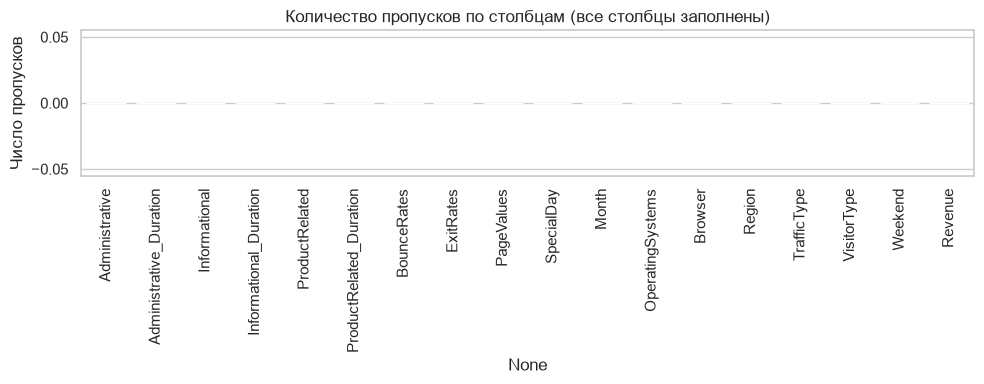


Отрицательные значения по столбцам (только ненулевые):
не найдены


In [5]:
# Анализ пропусков: явные пропуски (NaN)
missing = df.isna().sum()                                  # число пропусков по столбцам
print('Всего явных пропусков:', int(missing.sum()))        # по описанию датасета их нет

plt.figure(figsize=(10, 4))                                # размер графика
sns.barplot(x=missing.index, y=missing.values, color='steelblue')   # столбец на каждый признак
plt.xticks(rotation=90)                                    # поворачиваем подписи оси X
plt.title('Количество пропусков по столбцам (все столбцы заполнены)')   # заголовок
plt.ylabel('Число пропусков')                              # подпись оси Y
plt.tight_layout()                                         # подгоняем отступы
plt.show()                                                 # показываем график

# Скрытые пропуски: отрицательные значения там, где их быть не может (время и счётчики >= 0)
neg = (df[num_features] < 0).sum()                         # число отрицательных значений по числовым столбцам
print('\nОтрицательные значения по столбцам (только ненулевые):')   # заголовок вывода
print(neg[neg > 0] if (neg > 0).any() else 'не найдены')   # показываем найденные или сообщаем, что их нет

In [6]:
# Обработка скрытых пропусков: длительность -1 означает «нет данных», а не отрицательное время
pairs = [('Administrative_Duration', 'Administrative'),    # (столбец длительности, столбец счётчика страниц)
         ('Informational_Duration', 'Informational'),
         ('ProductRelated_Duration', 'ProductRelated')]
n_fixed = 0                                                # сколько значений исправлено
for dur, cnt in pairs:                                     # по каждой паре
    bad = df[dur] < 0                                      # маска некорректных длительностей
    ok_median = df.loc[~bad & (df[cnt] > 0), dur].median() # медиана по корректным сессиям, где страницы были
    df.loc[bad & (df[cnt] == 0), dur] = 0                  # страниц нет → времени на них 0
    df.loc[bad & (df[cnt] > 0), dur] = ok_median           # страницы были → заполняем медианой (устойчива к выбросам)
    n_fixed += int(bad.sum())                              # считаем исправленные значения
print('Исправлено некорректных длительностей:', n_fixed)    # 0 — значит, в вашем файле их нет
print('Осталось отрицательных значений:', int((df[num_features] < 0).sum().sum()))   # проверка результата

Исправлено некорректных длительностей: 0
Осталось отрицательных значений: 0


In [7]:
# Анализ целевой переменной
print(df['Revenue'].value_counts())                        # абсолютные значения по классам
print()  # пустая строка
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))   # доли в %

Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


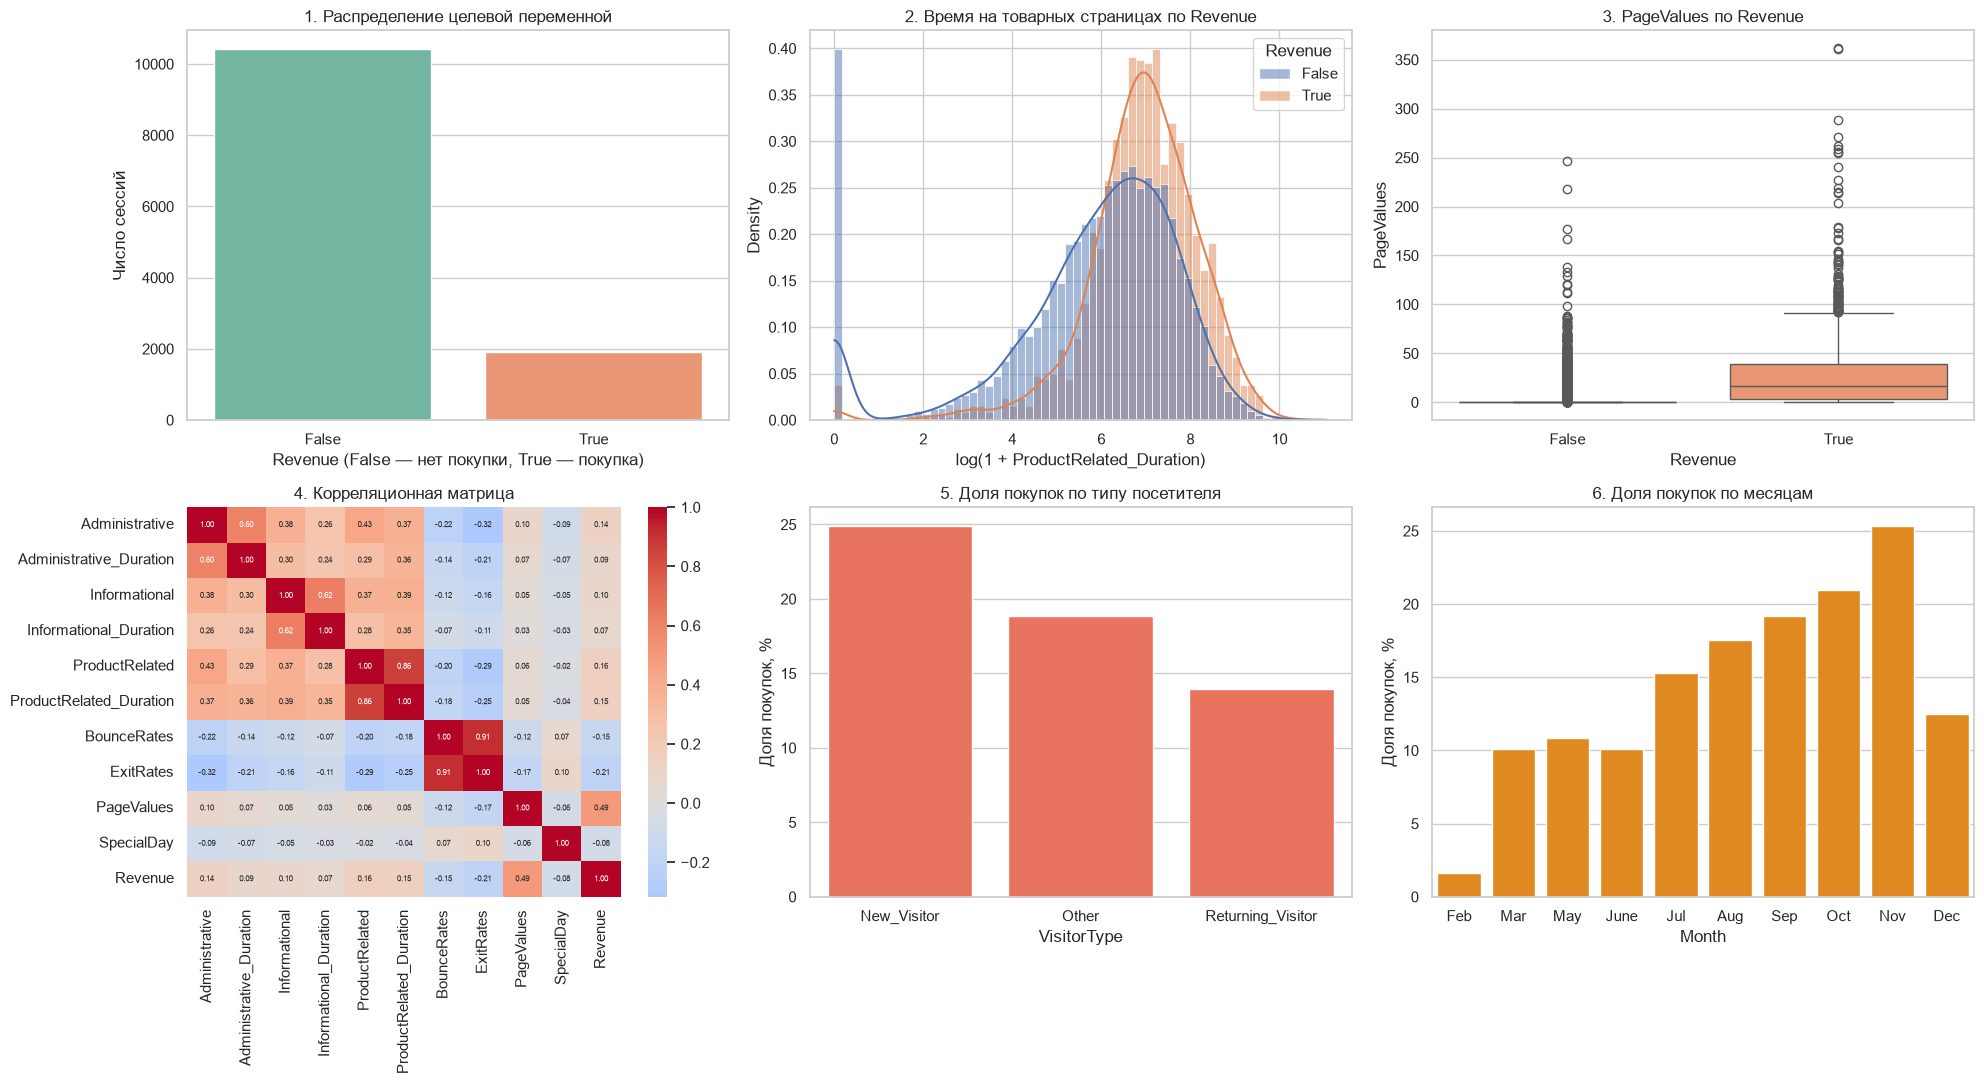

In [8]:
# EDA: сетка 2x3 — 6 графиков
fig, axes = plt.subplots(2, 3, figsize=(20, 11))           # сетка 2x3 для 6 графиков

# 1. Countplot — распределение целевой переменной
sns.countplot(data=df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 0])   # график 1
axes[0, 0].set_title('1. Распределение целевой переменной')       # заголовок
axes[0, 0].set_xlabel('Revenue (False — нет покупки, True — покупка)')   # подпись оси X
axes[0, 0].set_ylabel('Число сессий')                             # подпись оси Y

# 2. Гистограмма ProductRelated_Duration с разбивкой по Revenue (логарифм: распределение очень скошено)
plot_df = df.assign(LogProductDuration=np.log1p(df['ProductRelated_Duration']))   # log(1+x) сглаживает хвост
sns.histplot(data=plot_df, x='LogProductDuration', hue='Revenue', kde=True,  # график 2: гистограмма tenure с KDE по классам
             stat='density', common_norm=False, ax=axes[0, 1])    # график 2: формы распределений сравнимы
axes[0, 1].set_title('2. Время на товарных страницах по Revenue')  # заголовок
axes[0, 1].set_xlabel('log(1 + ProductRelated_Duration)')         # подпись оси X

# 3. Boxplot PageValues по Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 2])   # график 3
axes[0, 2].set_title('3. PageValues по Revenue')                  # заголовок
axes[0, 2].set_ylabel('PageValues')                               # подпись оси Y

# 4. Heatmap корреляций числовых признаков и целевой
corr_df = df[num_features].copy()                                 # числовые столбцы
corr_df['Revenue'] = df['Revenue'].astype(int)                    # целевая в виде 0/1
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,  # график 4: тепловая карта корреляций
            annot_kws={'size': 6}, ax=axes[1, 0])                 # график 4: тепловая карта корреляций
axes[1, 0].set_title('4. Корреляционная матрица')                 # заголовок

# 5. Доля покупок по типу посетителя
visitor_rate = df.groupby('VisitorType')['Revenue'].mean() * 100  # доля сессий с покупкой (%) по типам посетителей
sns.barplot(x=visitor_rate.index, y=visitor_rate.values, color='tomato', ax=axes[1, 1])   # график 5
axes[1, 1].set_title('5. Доля покупок по типу посетителя')        # заголовок
axes[1, 1].set_ylabel('Доля покупок, %')                          # подпись оси Y
axes[1, 1].set_xlabel('VisitorType')                              # подпись оси X

# 6. Доля покупок по месяцам (в календарном порядке)
month_rate = (df.groupby('Month')['Revenue'].mean() * 100).reindex(
    [m for m in MONTH_ORDER if m in df['Month'].unique()])        # доля покупок (%) по месяцам в порядке календаря
sns.barplot(x=month_rate.index, y=month_rate.values, color='darkorange', ax=axes[1, 2])   # график 6
axes[1, 2].set_title('6. Доля покупок по месяцам')                # заголовок
axes[1, 2].set_ylabel('Доля покупок, %')                          # подпись оси Y
axes[1, 2].set_xlabel('Month')                                    # подпись оси X

plt.tight_layout()                                                # подгоняем отступы
plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
plt.show()                                                        # показываем график

### Обоснование новых признаков

| Признак | Формула | Зачем нужен (гипотеза) |
|---------|---------|------------------------|
| `TotalPages` | Administrative + Informational + ProductRelated | Общая вовлечённость: чем больше страниц просмотрено, тем выше интерес к сайту |
| `TotalDuration` | сумма трёх длительностей | Общее время в сессии; дополняет число страниц (можно быстро листать или внимательно читать) |
| `AvgPageValue` | PageValues / (TotalPages + 1) | Ценность страниц в пересчёте на одну страницу; сглаживает влияние длины сессии |
| `BounceExitRatio` | BounceRates / (ExitRates + 0.001) | Структура ухода: отказ с первой страницы или выход после просмотра; +0.001 защищает от деления на 0 |
| `AvgTimePerPage` | TotalDuration / (TotalPages + 1) | Интенсивность просмотра: «быстрый пролистыватель» или «вдумчивый читатель» |
| `ProductShare` | ProductRelated / (TotalPages + 1) | Доля товарных страниц: показывает фокус сессии именно на товарах |
| `IsNewVisitor` | VisitorType == 'New_Visitor' | Бинарный флаг типа посетителя; поведение новых и вернувшихся различается |
| `IsWeekend` | Weekend → 0/1 | Числовое представление выходного дня для моделей |
| `MonthNum` | Month → 1–12 | Сезонность в числовом виде (распродажи, праздники); строку `Month` модели напрямую не используют |
| `IsHighTraffic` | TrafficType > 10 | Пример бинарного признака по порогу. `TrafficType` — номинальный идентификатор без порядка, поэтому порог условный; пользу признака проверяем экспериментом |

Знаменатели `+1` и `+0.001` нужны, чтобы не делить на ноль для сессий без просмотров. Вклад созданных признаков оценивается в разделе 8 (сравнение набора с признаками и без них).

In [9]:
# Feature Engineering: новые признаки на основе поведения пользователя
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']   # всего страниц за сессию
df['TotalDuration'] = (df['Administrative_Duration'] + df['Informational_Duration']
                       + df['ProductRelated_Duration'])                               # всего времени в сессии, сек
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)                         # ценность на страницу (+1 — защита от /0)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)                  # отношение отказов к выходам
df['AvgTimePerPage'] = df['TotalDuration'] / (df['TotalPages'] + 1)                    # среднее время на страницу
df['ProductShare'] = df['ProductRelated'] / (df['TotalPages'] + 1)                     # доля товарных страниц

df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)                  # флаг нового посетителя
df['IsWeekend'] = df['Weekend'].astype(int)                                            # выходной: bool → 0/1
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)                             # бинарный признак по порогу TrafficType

# Месяц → число 1-12 (to_datetime с форматом %b не подходит: в датасете июнь записан как 'June')
MONTH_MAP = {m: i + 1 for i, m in enumerate(MONTH_ORDER)}                              # словарь «месяц → номер»
df['MonthNum'] = df['Month'].map(MONTH_MAP)                                            # применяем словарь
unknown_months = df.loc[df['MonthNum'].isna(), 'Month'].unique()                       # месяцы, которых нет в словаре
assert len(unknown_months) == 0, f'Неизвестные названия месяцев: {unknown_months}'     # останавливаемся, если такие есть

# Списки новых признаков (понадобятся для сравнения «с признаками / без»)
engineered_numeric = ['TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio',
                      'AvgTimePerPage', 'ProductShare', 'IsHighTraffic']                # чисто сконструированные признаки
new_features = engineered_numeric + ['IsNewVisitor', 'IsWeekend', 'MonthNum']           # все 10 новых признаков
print('Создано новых признаков:', len(new_features))                                   # должно быть 10
print(df[new_features].head())                                                         # проверяем результат

# Копия с читаемыми значениями — понадобится для бизнес-анализа в разделе 8
df_eda = df.copy()                                                                     # копия до кодирования
df_eda['Revenue'] = df_eda['Revenue'].astype(int)                                      # целевая как 0/1 для расчёта долей

Создано новых признаков: 10
   TotalPages  TotalDuration  AvgPageValue  BounceExitRatio  AvgTimePerPage  \
0           1       0.000000           0.0         0.995025        0.000000   
1           2      64.000000           0.0         0.000000       21.333333   
2           1       0.000000           0.0         0.995025        0.000000   
3           2       2.666667           0.0         0.354610        0.888889   
4          10     627.500000           0.0         0.392157       57.045455   

   ProductShare  IsHighTraffic  IsNewVisitor  IsWeekend  MonthNum  
0      0.500000              0             0          0         2  
1      0.666667              0             0          0         2  
2      0.500000              0             0          0         2  
3      0.666667              0             0          0         2  
4      0.909091              0             0          1         2  


In [10]:
# Кодирование
df['Revenue'] = df['Revenue'].astype(int)                  # целевая: True → 1, False → 0

# One-Hot для VisitorType: 3 категории = 3 столбца; New_Visitor уже есть как IsNewVisitor,
# Returning_Visitor — базовая категория (все нули), поэтому добавляем только VisitorType_Other
visitor_ohe = pd.get_dummies(df['VisitorType'], prefix='VisitorType', dtype=int)       # One-Hot по типу посетителя
df = pd.concat([df, visitor_ohe[['VisitorType_Other']]], axis=1)                       # добавляем нужный столбец

# Исходные строковые/булевы столбцы заменены числовыми версиями — удаляем
df = df.drop(columns=['Month', 'VisitorType', 'Weekend'])                              # остаются только числа

# OperatingSystems, Browser, Region, TrafficType — идентификаторы без порядка; для деревьев оставляем
# целочисленные коды (Target Encoding проверим в бонусе)
non_numeric = df.select_dtypes(exclude='number').columns.tolist()                      # столбцы, которые не числа
assert not non_numeric, f'Остались нечисловые столбцы: {non_numeric}'                  # проверка: всё закодировано
print(df.head())                                                                       # результат кодирования

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay  ...  TotalDuration  \
0         0.20       0.20         0.0         0.0  ...       0.000000   
1         0.00       0.10         0.0         0.0  ...      64.000

In [11]:
# Разделение на train/test со стратификацией (сохраняем долю классов)
from sklearn.model_selection import train_test_split         # разбиение на train/test
from sklearn.preprocessing import StandardScaler             # масштабирование числовых признаков

feature_cols = [c for c in df.columns if c != 'Revenue']     # список признаков модели
X = df[feature_cols]                                         # матрица признаков
y = df['Revenue']                                            # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)   # 80% train / 20% test, stratify=y сохраняет доли классов

print('Признаков в модели:', len(feature_cols))              # итоговое число признаков
print('train:', X_train.shape, ' test:', X_test.shape)       # размеры выборок
print('Доля покупок — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))   # доля класса 1 одинакова

# Scaler для непрерывных признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# немасштабированных данных; scaler обучаем только на train и сохраняем для совместимости
scale_cols = num_features + ['TotalPages', 'TotalDuration', 'AvgPageValue',  # числовые признаки для масштабирования
                             'BounceExitRatio', 'AvgTimePerPage', 'ProductShare']      # непрерывные признаки
scaler = StandardScaler().fit(X_train[scale_cols])           # обучаем scaler только на train

Признаков в модели: 25
train: (9864, 25)  test: (2466, 25)
Доля покупок — train: 0.155, test: 0.155


**Выводы по EDA:**
- Явных пропусков в данных нет. Скрытые пропуски — длительности со значением -1 (маркер «нет данных»): ячейка выше показывает, сколько их в вашем файле, и заменяет их на 0 (если страниц этого типа не было) или на медиану (если были). Медиана выбрана как устойчивая к сильно скошенным распределениям; доля таких строк мала, поэтому выбор стратегии почти не влияет на результат.
- В датасете есть полные дубликаты строк (число выведено выше). Мы их не удаляем: это могут быть реальные одинаковые короткие сессии, а удаление изменило бы распределение классов. Но стоит помнить, что копии одной сессии могут попасть и в train, и в test, слегка завышая оценку качества.
- Классы сильно несбалансированы, поэтому используем `stratify=y` при разбиении и взвешивание классов в моделях.
- Распределения времени и страниц сильно скошены вправо, что видно на графике 2 (поэтому там логарифмическая шкала). Для деревьев это не проблема: они не чувствительны к монотонным преобразованиям.
- Графики 5 и 6 показывают, что доля покупок заметно различается по типам посетителей и месяцам; точные значения выводятся в разделе 8 и используются в бизнес-выводах.
- Столбец `Month` содержит значение `June`, а не `Jun`, поэтому месяц переводим в число через явный словарь. В данных нет января и апреля.
- Создано 10 новых признаков; вклад конструируемых признаков проверяется экспериментом в разделе 8.

## Построение и обучение моделей

Обучаем 4 ансамблевые модели на одних и тех же данных и фиксируем время обучения. Для борьбы с дисбалансом используем взвешивание классов (`class_weight='balanced'`, `scale_pos_weight=5`, `auto_class_weights='Balanced'`). Для XGBoost `scale_pos_weight = 5` — округлённое отношение числа сессий без покупки к сессиям с покупкой (84.5 / 15.5 ≈ 5.4).

In [12]:
# Импорт моделей
from sklearn.ensemble import RandomForestClassifier   # Random Forest (bagging)
from xgboost import XGBClassifier                     # XGBoost (boosting)
from lightgbm import LGBMClassifier                   # LightGBM (boosting)
from catboost import CatBoostClassifier               # CatBoost (boosting)

train_times = {}   # сюда складываем время обучения каждой модели

def fit_timed(model, name):  # обучение с замером времени
    # Обучаем модель и замеряем время
    start = time.time()                                       # старт таймера
    model.fit(X_train, y_train)                               # обучаем модель
    train_times[name] = time.time() - start                   # сохраняем время обучения
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')   # выводим время
    return model                                              # возвращаем обученную модель

# 1. Random Forest (bagging)
rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
    n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
    random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')   # воспроизводимость, все ядра

# 2. XGBoost (boosting)
xgb_model = fit_timed(XGBClassifier(  # XGBoost
    n_estimators=200, max_depth=6, learning_rate=0.1,         # число деревьев, глубина, скорость обучения
    subsample=0.9, colsample_bytree=0.9,                      # доли объектов и признаков на дерево
    scale_pos_weight=5,                                       # компенсация дисбаланса (84.5/15.5 ≈ 5.4)
    random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')   # воспроизводимость, метрика логирования

# 3. LightGBM (boosting); параметры вынесены в словарь — переиспользуем в сравнении «с признаками / без» и в Optuna
lgbm_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,   # листьев на дерево — главный параметр
                   class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)     # баланс классов, без логов
lgbm_model = fit_timed(LGBMClassifier(**lgbm_params), 'LightGBM')                      # обучаем LightGBM

# 4. CatBoost (boosting). Признаки уже закодированы числами, поэтому cat_features не задаём
cat_model = fit_timed(CatBoostClassifier(  # CatBoost
    iterations=200, depth=6, learning_rate=0.1,               # итерации, глубина, скорость обучения
    auto_class_weights='Balanced', random_state=RANDOM_STATE,  # баланс классов, без логов и без папки catboost_info
    verbose=0, allow_writing_files=False), 'CatBoost')        # без логов и без папки catboost_info

⏱️ Время обучения Random Forest: 0.718 сек
⏱️ Время обучения XGBoost: 0.646 сек
⏱️ Время обучения LightGBM: 0.419 сек
⏱️ Время обучения CatBoost: 1.437 сек


In [13]:
# Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
models_info = pd.DataFrame([  # строки таблицы моделей
    ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
    ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=5', train_times['XGBoost']],  # XGBoost
    ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05, class_weight=balanced', train_times['LightGBM']],  # LightGBM
    ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])   # названия столбцов
display(Markdown(md_table(models_info, 3)))                          # таблица с реальными значениями времени

| Модель | Тип | Параметры | Время обучения, сек |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight=balanced | 0.718 |
| XGBoost | Boosting | n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=5 | 0.646 |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, max_depth=7, lr=0.05, class_weight=balanced | 0.419 |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced | 1.437 |

### Модели

Таблица с параметрами и временем обучения выведена ячейкой выше.

**Почему эти модели:**
- RF — устойчив к переобучению, хорошо работает «из коробки», служит надёжным baseline;
- XGBoost — универсальный и точный, есть регуляризация;
- LightGBM — быстрый, подходит для больших данных;
- CatBoost — хорош на категориальных признаках и обычно стабилен без тонкой настройки.

## Оценка качества

Считаем Accuracy, Precision, Recall, F1 и ROC-AUC на отложенной тестовой выборке. Порог классификации — стандартный 0.5; ROC-AUC от порога не зависит. Из-за дисбаланса (15.5% покупок) особое внимание уделяем Recall, Precision и F1.

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)   # метрики классификации

def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
    # Считаем набор метрик для одной модели
    y_pred = model.predict(X_test)                    # предсказанные классы (порог 0.5)
    y_proba = model.predict_proba(X_test)[:, 1]       # вероятность покупки
    return {  # словарь с метриками
        'Model': name,                                # название модели
        'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
        'Precision': precision_score(y_test, y_pred), # точность по классу «покупка»
        'Recall':    recall_score(y_test, y_pred),    # полнота по классу «покупка»
        'F1':        f1_score(y_test, y_pred),        # гармоническое среднее Precision и Recall
        'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
    }

models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
          'LightGBM': lgbm_model, 'CatBoost': cat_model}               # все модели в одном словаре

results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]   # метрики для каждой модели
results_df = pd.DataFrame(results)                                     # таблица результатов
results_df['Время, сек'] = results_df['Model'].map(train_times)        # добавляем время обучения
print(results_df.round(4).to_string(index=False))                      # таблица метрик текстом
display(Markdown(md_table(results_df)))                                # то же в виде Markdown-таблицы

        Model  Accuracy  Precision  Recall     F1  ROC-AUC  Время, сек
Random Forest    0.8706     0.5591  0.7801 0.6514   0.9237      0.7182
      XGBoost    0.8828     0.5996  0.7330 0.6596   0.9205      0.6461
     LightGBM    0.8755     0.5725  0.7749 0.6585   0.9248      0.4186
     CatBoost    0.8702     0.5581  0.7801 0.6507   0.9284      1.4372


| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Время, сек |
|---|---|---|---|---|---|---|
| Random Forest | 0.8706 | 0.5591 | 0.7801 | 0.6514 | 0.9237 | 0.7182 |
| XGBoost | 0.8828 | 0.5996 | 0.7330 | 0.6596 | 0.9205 | 0.6461 |
| LightGBM | 0.8755 | 0.5725 | 0.7749 | 0.6585 | 0.9248 | 0.4186 |
| CatBoost | 0.8702 | 0.5581 | 0.7801 | 0.6507 | 0.9284 | 1.4372 |

Лучшая модель по ROC-AUC: CatBoost


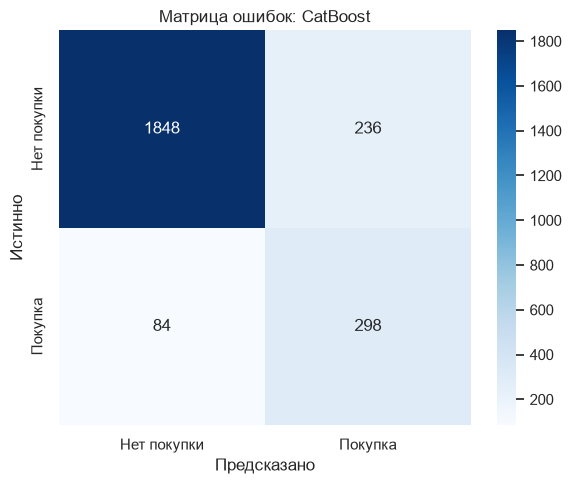

              precision    recall  f1-score   support

 Нет покупки       0.96      0.89      0.92      2084
     Покупка       0.56      0.78      0.65       382

    accuracy                           0.87      2466
   macro avg       0.76      0.83      0.79      2466
weighted avg       0.89      0.87      0.88      2466



In [15]:
# Лучшая модель по ROC-AUC и её матрица ошибок
best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']    # лучшая модель по ROC-AUC
best_baseline = models[best_name]                                      # объект лучшей модели
y_pred_best = best_baseline.predict(X_test)                            # её предсказания
print('Лучшая модель по ROC-AUC:', best_name)                          # название лучшей модели

cm = confusion_matrix(y_test, y_pred_best)                             # матрица ошибок
plt.figure(figsize=(6, 5))                                             # создаём фигуру
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
            xticklabels=['Нет покупки', 'Покупка'],
            yticklabels=['Нет покупки', 'Покупка'])                    # рисуем матрицу ошибок, подписи классов
plt.xlabel('Предсказано')                                              # подпись оси X
plt.ylabel('Истинно')                                                  # подпись оси Y
plt.title(f'Матрица ошибок: {best_name}')                              # заголовок графика
plt.tight_layout()                                                     # подгоняем отступы
plt.show()                                                             # показываем график

print(classification_report(y_test, y_pred_best, target_names=['Нет покупки', 'Покупка']))   # подробный отчёт по классам

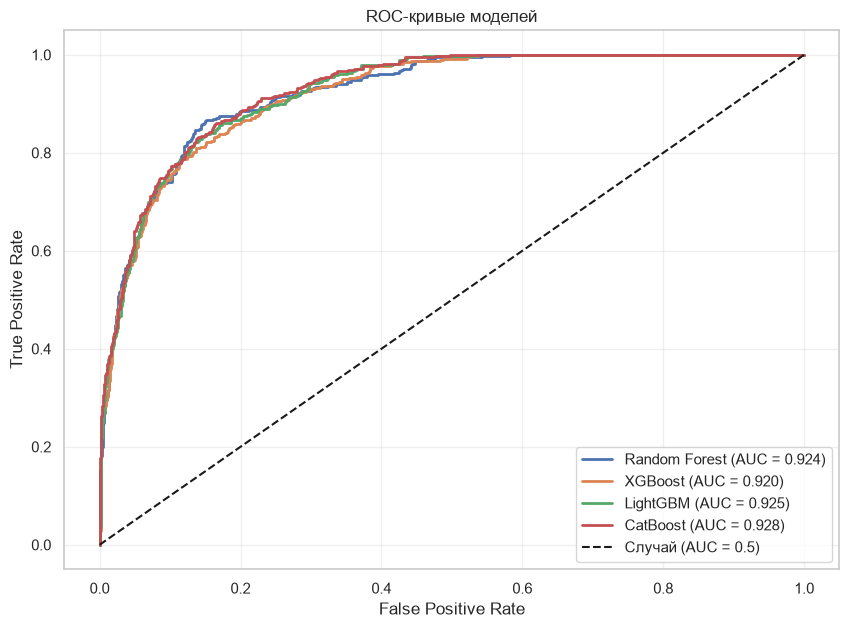

In [16]:
# ROC-кривые всех 4 моделей на одном графике
plt.figure(figsize=(10, 7))                                            # создаём фигуру
for name, model in models.items():                                     # кривая для каждой модели
    y_proba = model.predict_proba(X_test)[:, 1]                        # вероятность покупки
    fpr, tpr, _ = roc_curve(y_test, y_proba)                           # точки ROC-кривой
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')   # кривая с AUC в легенде

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')            # диагональ — случайное угадывание
plt.xlabel('False Positive Rate')                                      # подпись оси X
plt.ylabel('True Positive Rate')                                       # подпись оси Y
plt.title('ROC-кривые моделей')                                        # заголовок графика
plt.legend()                                                           # легенда
plt.grid(alpha=0.3)                                                    # сетка
plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')   # сохраняем картинку в examples/
plt.show()                                                             # показываем график

In [17]:
# Автоматический анализ результатов (числа подставляются из таблицы)
fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']   # самая быстрая модель
best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']   # модель с лучшим Recall
spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()     # разброс ROC-AUC между моделями

print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")      # лучшая по ROC-AUC
print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")                                    # разброс качества
print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")    # самая быстрая
print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")             # лучший Recall
for _, r in results_df.iterrows():                                     # характер ошибок каждой модели
    tendency = 'Precision > Recall (модель осторожна в предсказании «покупка»)' if r['Precision'] > r['Recall'] \
        else 'Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)'   # Precision выше или ниже Recall
    print(f"• {r['Model']}: {tendency}")                               # вывод по модели

• Лучшая модель по ROC-AUC: CatBoost (0.9284)
• Разброс ROC-AUC между моделями: 0.0080
• Быстрее всех обучается: LightGBM (0.419 сек)
• Наибольший Recall: Random Forest (0.7801)
• Random Forest: Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)
• XGBoost: Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)
• LightGBM: Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)
• CatBoost: Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)


### Анализ результатов

Таблица метрик и времени обучения выведена выше. Как её читать:

- **ROC-AUC** — основная метрика сравнения. Различия между бустингами обычно небольшие, поэтому при выборе модели важны ещё скорость и устойчивость.
- Из-за взвешивания классов модели часто имеют **Recall выше Precision**: они чаще «подозревают» покупку, находя большую часть реальных покупателей ценой ложных срабатываний. Для бизнеса это допустимо, если стоимость действия мала (показать баннер), и менее приемлемо, если дорога (крупная скидка); баланс регулируется порогом.
- **Accuracy** при дисбалансе ниже, чем у «наивной» модели, всегда предсказывающей «нет покупки» (≈84.5%), но та имеет Recall = 0, поэтому Accuracy здесь не критерий.
- По времени обучения LightGBM, как правило, самый быстрый, а CatBoost самый медленный; точные значения — в таблице.
- Для оптимизации и интерпретации берём **LightGBM**, как требует задание (быстрая модель с качеством на уровне лучших; сравнение с лидером см. в выводе выше).

## Интерпретация и бизнес-инсайты

Смотрим, какие признаки модели считают важными, проверяем бизнес-гипотезы прямо по данным и оцениваем, насколько созданные признаки улучшили качество.

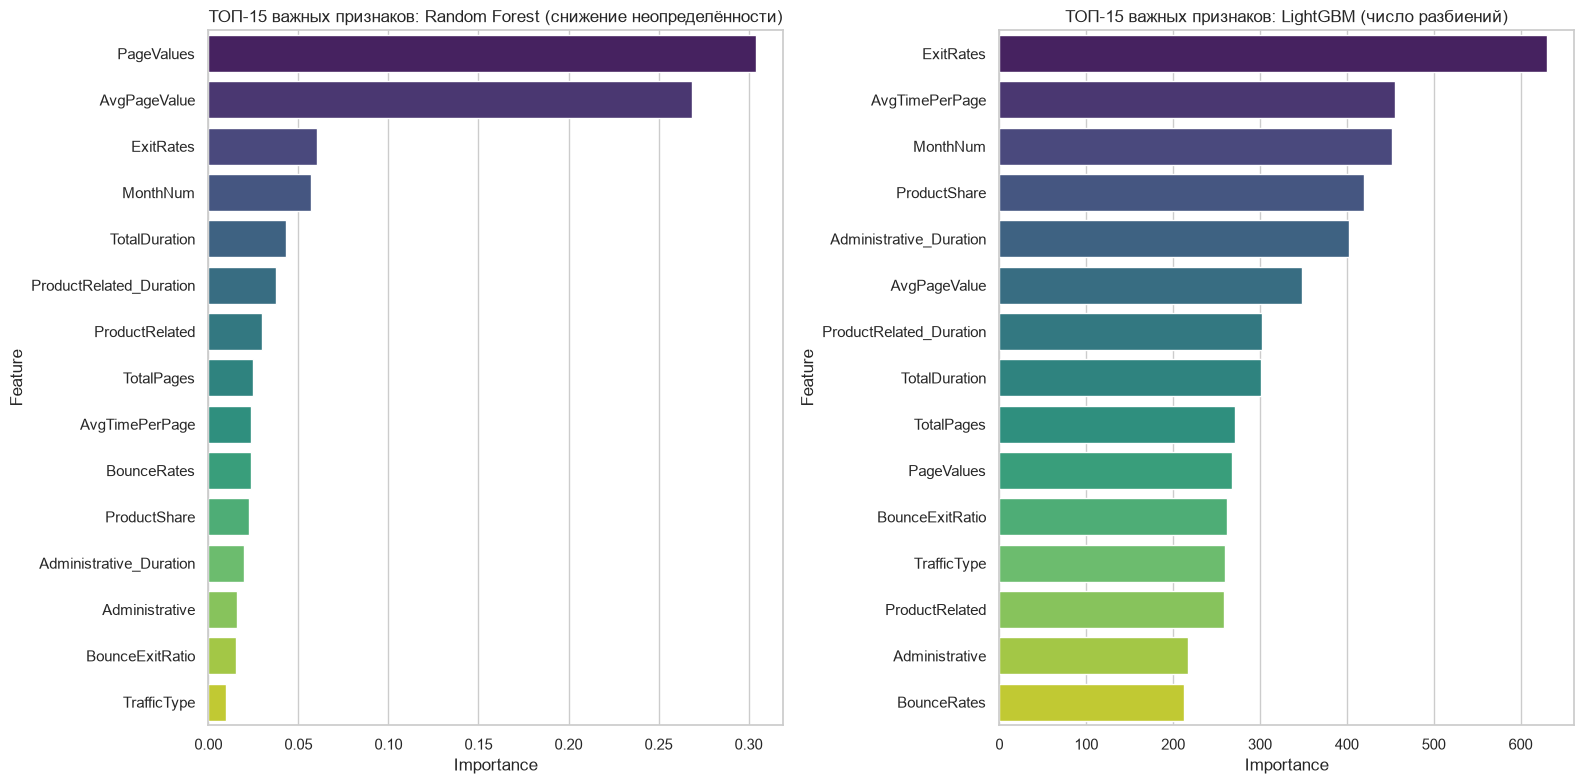

**Топ-5 признаков, влияющих на покупку** (★ — созданный нами признак):

| # | Random Forest | LightGBM |
|---|---|---|
| 1 | PageValues | ExitRates |
| 2 | AvgPageValue ★ | AvgTimePerPage ★ |
| 3 | ExitRates | MonthNum ★ |
| 4 | MonthNum ★ | ProductShare ★ |
| 5 | TotalDuration ★ | Administrative_Duration |

In [18]:
# Feature Importance для Random Forest и LightGBM
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)             # важность признаков Random Forest, по убыванию
imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)             # важность признаков LightGBM, по убыванию
importances = imp_lgbm                                      # используем как ориентир в разделе SHAP

fig, axes = plt.subplots(1, 2, figsize=(16, 8))             # два графика рядом
for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
                        (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:   # RF слева, LightGBM справа
    sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
                palette='viridis', legend=False, ax=ax)     # ТОП-15 признаков, цветовая палитра
    ax.set_title(f'ТОП-15 важных признаков: {title}')       # заголовок подграфика
plt.tight_layout()                                          # подгоняем отступы
plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')   # сохраняем картинку
plt.show()                                                  # показываем график

# Топ-5 признаков по обеим моделям (Markdown-таблица); звёздочка — созданный нами признак
mark = lambda f: f + (' ★' if f in new_features else '')    # помечаем новые признаки
top5 = pd.DataFrame({'#': range(1, 6),
                     'Random Forest': [mark(f) for f in imp_rf['Feature'].head(5)],
                     'LightGBM': [mark(f) for f in imp_lgbm['Feature'].head(5)]})   # топ-5 по каждой модели
display(Markdown('**Топ-5 признаков, влияющих на покупку** (★ — созданный нами признак):\n\n' + md_table(top5)))   # таблица топ-5

In [19]:
# Бизнес-гипотезы по исходным (некодированным) данным; формулировки подставляются автоматически
rate = lambda col: (df_eda.groupby(col)['Revenue'].mean() * 100)      # доля покупок (%) по группам признака

pv = rate(df_eda['PageValues'] > 0)                                   # PageValues > 0 против = 0
vt = rate('VisitorType')                                              # по типу посетителя
mr = rate('Month')                                                    # по месяцам
wk = rate('IsWeekend')                                                # будни / выходные
sd = rate(df_eda['SpecialDay'] > 0)                                   # рядом с особым днём или нет
corr_bounce = df_eda['BounceRates'].corr(df_eda['Revenue'])           # корреляция отказов с покупкой
med_dur = df_eda.groupby('Revenue')['ProductRelated_Duration'].median()   # медианное время на товарных страницах

lines = []                                                            # собираем строки вывода
lines.append(f"- Сессии с PageValues > 0 заканчиваются покупкой в {pv.get(True, float('nan')):.1f}% случаев, "
             f"с PageValues = 0 — в {pv.get(False, float('nan')):.1f}%.")           # эффект PageValues
lines.append(f"- Время на товарных страницах (медиана): покупатели — {med_dur.get(1, float('nan')):.0f} сек, "
             f"не купившие — {med_dur.get(0, float('nan')):.0f} сек.")              # эффект времени
lines.append(f"- Корреляция BounceRates с покупкой: {corr_bounce:+.2f} "
             f"({'отказы снижают вероятность покупки' if corr_bounce < 0 else 'отказы не снижают вероятность покупки'}).")   # эффект отказов
if 'New_Visitor' in vt.index and 'Returning_Visitor' in vt.index:     # сравниваем новых и вернувшихся
    word = 'чаще' if vt['New_Visitor'] > vt['Returning_Visitor'] else 'реже'   # чаще или реже покупают новые
    lines.append(f"- Новые посетители покупают {word} вернувшихся: {vt['New_Visitor']:.1f}% против "
                 f"{vt['Returning_Visitor']:.1f}%.")                  # эффект типа посетителя
lines.append(f"- Лучший месяц по доле покупок — {mr.idxmax()} ({mr.max():.1f}%), худший — {mr.idxmin()} ({mr.min():.1f}%).")   # сезонность
lines.append(f"- Выходные: {wk.get(1, float('nan')):.1f}% покупок, будни: {wk.get(0, float('nan')):.1f}%.")   # эффект выходных
lines.append(f"- Рядом с особым днём (SpecialDay > 0): {sd.get(True, float('nan')):.1f}% покупок, "
             f"в остальные дни: {sd.get(False, float('nan')):.1f}%.")                # эффект особого дня
display(Markdown('**Бизнес-гипотезы, проверенные по данным:**\n\n' + '\n'.join(lines)))   # выводим список

**Бизнес-гипотезы, проверенные по данным:**

- Сессии с PageValues > 0 заканчиваются покупкой в 56.3% случаев, с PageValues = 0 — в 3.9%.
- Время на товарных страницах (медиана): покупатели — 1110 сек, не купившие — 510 сек.
- Корреляция BounceRates с покупкой: -0.15 (отказы снижают вероятность покупки).
- Новые посетители покупают чаще вернувшихся: 24.9% против 13.9%.
- Лучший месяц по доле покупок — Nov (25.4%), худший — Feb (1.6%).
- Выходные: 17.4% покупок, будни: 14.9%.
- Рядом с особым днём (SpecialDay > 0): 6.2% покупок, в остальные дни: 16.5%.

In [20]:
# Влияние инженерии признаков: LightGBM на исходных признаках и на полном наборе
from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация

base_cols = [c for c in feature_cols if c not in engineered_numeric]   # набор без конструируемых признаков (только кодировка исходных)
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)      # одинаковые 5 фолдов для обоих наборов

rows = []                                                              # сюда складываем строки сравнения
for label, cols in [('Исходные + кодирование', base_cols), ('С созданными признаками', feature_cols)]:   # два набора
    cv_auc = cross_val_score(LGBMClassifier(**lgbm_params), X_train[cols], y_train,
                             cv=skf, scoring='roc_auc').mean()         # средний ROC-AUC по фолдам на train
    m = LGBMClassifier(**lgbm_params).fit(X_train[cols], y_train)      # обучаем на всём train
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])   # ROC-AUC на test
    rows.append([label, len(cols), cv_auc, test_auc])                  # запоминаем результат

ablation_df = pd.DataFrame(rows, columns=['Набор признаков', 'Число признаков', 'CV ROC-AUC', 'Test ROC-AUC'])   # итоговая таблица
display(Markdown(md_table(ablation_df)))                               # выводим таблицу
delta_cv = ablation_df.loc[1, 'CV ROC-AUC'] - ablation_df.loc[0, 'CV ROC-AUC']       # разница по CV
delta_test = ablation_df.loc[1, 'Test ROC-AUC'] - ablation_df.loc[0, 'Test ROC-AUC']  # разница по test
print(f'Изменение ROC-AUC от созданных признаков: CV {delta_cv:+.4f}, test {delta_test:+.4f}')   # итог сравнения

| Набор признаков | Число признаков | CV ROC-AUC | Test ROC-AUC |
|---|---|---|---|
| Исходные + кодирование | 18 | 0.9300 | 0.9269 |
| С созданными признаками | 25 | 0.9300 | 0.9248 |

Изменение ROC-AUC от созданных признаков: CV -0.0000, test -0.0021


### Интерпретация

**Топ признаков, влияющих на покупку** — см. графики и таблицу выше (★ отмечает созданные нами признаки). Как правило, в верхней части оказываются `PageValues`, показатели выходов и отказов, число и время на товарных страницах и месяц. Порядок для RF и LightGBM отличается: у LightGBM важность считается по числу разбиений, поэтому непрерывные признаки с множеством порогов выглядят важнее.

**Бизнес-инсайты** формулируются по выводу ячейки «Бизнес-гипотезы» выше: числа там посчитаны по вашим данным, и в итоговом тексте нужно опираться именно на них. Типичные выводы для e-commerce:
- **PageValues** — самый сильный сигнал: сессии, в которых посетитель заходил на страницы, исторически приводившие к покупкам, сильно чаще заканчиваются покупкой. Стоит направлять трафик на такие страницы.
- **Вовлечённость на товарных страницах** связана с покупкой; страницы с высокими показателями отказов и выходов требуют улучшения (скорость, контент, цена).
- **Сезонность**: доля покупок сильно различается по месяцам, поэтому кампании и бюджет стоит планировать по календарю.
- **Тип посетителя**: направление эффекта нужно брать из таблицы выше, а не из «ожиданий». В этом датасете новые и вернувшиеся посетители могут вести себя не так, как подсказывает интуиция, а значит стратегии для них должны быть разными.

**Эффект созданных признаков** показан в таблице сравнения. Прирост ROC-AUC может быть небольшим: деревья частично «находят» зависимости сами, а сильнейший признак (`PageValues`) уже есть в исходных данных. Если прирост близок к нулю или отрицателен, это тоже результат, который нужно описать честно; созданные признаки при этом полезны для интерпретации (например, доля товарных страниц).

*Важно:* это ассоциации, а не причинно-следственные связи. Кроме того, `PageValues` вычисляется системой аналитики с учётом исходов транзакций, поэтому он частично «знает» ответ; в реальной системе его нужно считать только по прошлым данным, иначе возникает утечка.

## Тюнинг гиперпараметров (Optuna)

Оптимизируем LightGBM байесовским поиском (TPE). Целевая функция — средний ROC-AUC на 5-fold стратифицированной кросс-валидации **по обучающей выборке**, чтобы тестовая выборка не участвовала в подборе. В `LGBMClassifier` параметр `subsample` действует только вместе с `subsample_freq > 0`, поэтому фиксируем `subsample_freq=1`.

In [21]:
# Установка (если нужно): !pip install optuna shap
import optuna                                                           # байесовская оптимизация гиперпараметров
from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация

optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе

def objective(trial):  # целевая функция для Optuna
    # Пространство поиска гиперпараметров
    params = {  # пространство поиска гиперпараметров
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),                 # число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),                       # число листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),                                   # максимальная глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),           # скорость обучения (лог-шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),                              # доля объектов на дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),                # доля признаков на дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),                   # минимум объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),                    # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),                  # L2-регуляризация
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
                           random_state=RANDOM_STATE, verbose=-1)   # модель с предложенными параметрами
    cv_scores = cross_val_score(  # 5-fold CV по train
        model, X_train, y_train,                                    # данные для кросс-валидации
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),   # 5 стратифицированных фолдов
        scoring='roc_auc')                                          # метрика — ROC-AUC
    return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам

# CV-оценка baseline LightGBM для честного сравнения (те же фолды, что и в Optuna)
baseline_cv = cross_val_score(  # CV baseline LightGBM
    LGBMClassifier(**lgbm_params), X_train, y_train,                # baseline-параметры
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), # те же фолды
    scoring='roc_auc').mean()                                       # средний ROC-AUC по фолдам
print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')          # качество baseline

# Запуск оптимизации (TPE с фиксированным seed)
N_TRIALS = 30                                                       # число испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))   # максимизируем AUC
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)   # запускаем поиск

print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')                 # лучший результат CV
for key, value in study.best_params.items():                        # лучшие параметры
    print(f'  {key}: {value}')                                      # параметр: значение

Baseline LightGBM, CV ROC-AUC: 0.9300


Best trial: 17. Best value: 0.935079: 100%|██████████| 30/30 [01:33<00:00,  3.11s/it]


Best CV ROC-AUC: 0.9351
  n_estimators: 300
  num_leaves: 60
  max_depth: 6
  learning_rate: 0.017883956617506903
  subsample: 0.8662828656193364
  colsample_bytree: 0.5394376050105616
  min_child_samples: 32
  reg_alpha: 4.003570359480368
  reg_lambda: 0.02296171417309883


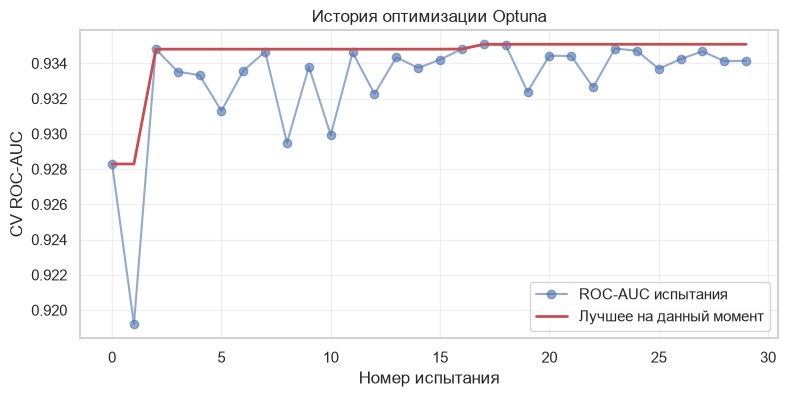

In [22]:
# История оптимизации
trials_df = study.trials_dataframe()                                # результаты испытаний в таблице
plt.figure(figsize=(9, 4))                                          # создаём фигуру
plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')   # качество каждого испытания
plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')   # лучшее на данный момент
plt.xlabel('Номер испытания')                                       # подпись оси X
plt.ylabel('CV ROC-AUC')                                            # подпись оси Y
plt.title('История оптимизации Optuna')                             # заголовок графика
plt.legend()                                                        # легенда
plt.grid(alpha=0.3)                                                 # сетка
plt.show()                                                          # показываем график

In [23]:
# Обучаем лучшую модель на всём train и сравниваем с baseline на test
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
                           random_state=RANDOM_STATE, verbose=-1)   # модель с лучшими параметрами
best_lgbm.fit(X_train, y_train)                                     # обучаем на всём train

y_pred_tuned = best_lgbm.predict(X_test)                            # классы на test
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]                # вероятности на test

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])   # ROC-AUC baseline на test
auc_tuned = roc_auc_score(y_test, y_proba_best)                     # ROC-AUC после Optuna на test
print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')   # сравнение по CV
print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')   # сравнение на test

# Итоговая таблица: все модели + тюнингованный LightGBM
tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')   # метрики тюнингованной модели
final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)   # общая таблица всех моделей
print()  # пустая строка
print(final_df.round(4).to_string(index=False))                     # итоговая таблица

# Итог Optuna в формате методички (числа подставляются автоматически)
params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
                      for k, v in study.best_params.items())        # лучшие параметры списком Markdown
display(Markdown(  # вывод итога в формате методички
    f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'                                      # число испытаний
    f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'               # метрики до и после
    f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))      # прирост в п.п.

CV ROC-AUC  baseline: 0.9300 → Optuna: 0.9351
Test ROC-AUC baseline: 0.9248 → Optuna: 0.9315  (прирост +0.0067)

            Model  Accuracy  Precision  Recall     F1  ROC-AUC
    Random Forest    0.8706     0.5591  0.7801 0.6514   0.9237
          XGBoost    0.8828     0.5996  0.7330 0.6596   0.9205
         LightGBM    0.8755     0.5725  0.7749 0.6585   0.9248
         CatBoost    0.8702     0.5581  0.7801 0.6507   0.9284
LightGBM (Optuna)    0.8662     0.5451  0.8220 0.6555   0.9315


**Optuna результаты:**

- Проведено 30 испытаний
- Baseline ROC-AUC (test): 0.9248
- Optuna ROC-AUC (test): 0.9315
- Прирост: +0.67 п.п.

**Лучшие параметры:**

- n_estimators: 300
- num_leaves: 60
- max_depth: 6
- learning_rate: 0.01788
- subsample: 0.8663
- colsample_bytree: 0.5394
- min_child_samples: 32
- reg_alpha: 4.004
- reg_lambda: 0.02296

### Бонус: Target Encoding и калибровка вероятностей

Пробуем (1) заменить целочисленные идентификаторы `OperatingSystems`, `Browser`, `Region`, `TrafficType` на Target Encoding (`sklearn.preprocessing.TargetEncoder` обучается с внутренней кросс-валидацией, поэтому не допускает утечки таргета) и (2) откалибровать вероятности лучшей модели.

In [24]:
from sklearn.preprocessing import TargetEncoder        # Target Encoding с встроенной кросс-валидацией
from sklearn.compose import ColumnTransformer          # применяем кодировщик только к выбранным столбцам
from sklearn.pipeline import make_pipeline             # кодировщик + модель в одном объекте
from sklearn.calibration import CalibratedClassifierCV # калибровка вероятностей
from sklearn.metrics import brier_score_loss           # метрика качества вероятностей

# 1. Target Encoding идентификаторов (обучается только на train внутри pipeline)
te_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']        # номинальные идентификаторы
te_pipe = make_pipeline(
    ColumnTransformer([('te', TargetEncoder(target_type='binary', random_state=RANDOM_STATE), te_cols)],
                      remainder='passthrough'),                           # остальные столбцы без изменений
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1))                # LightGBM с лучшими параметрами Optuna
te_pipe.fit(X_train, y_train)                                             # обучаем кодировщик и модель
te_row = evaluate_model(te_pipe, X_test, y_test, 'LightGBM (Optuna) + TargetEncoding')   # метрики модели с Target Encoding

# 2. Калибровка вероятностей лучшей модели (isotonic, 5-fold)
calibrated = CalibratedClassifierCV(  # калибровка вероятностей
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)   # isotonic-калибровка, 5 фолдов
calibrated.fit(X_train, y_train)                                          # обучаем калибратор
cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')   # метрики калиброванной модели

bonus_df = pd.DataFrame([tuned_row, te_row, cal_row])                     # сводка бонусов
print(bonus_df.round(4).to_string(index=False))                           # таблица бонусов

# Brier score: чем меньше, тем лучше откалиброваны вероятности
# (class_weight='balanced' систематически завышает вероятность покупки)
brier_before = brier_score_loss(y_test, y_proba_best)                     # Brier до калибровки
brier_after = brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1])   # Brier после калибровки
print('\nBrier score LightGBM (Optuna):             %.4f' % brier_before)  # Brier до калибровки
print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_after)    # Brier после калибровки

                             Model  Accuracy  Precision  Recall     F1  ROC-AUC
                 LightGBM (Optuna)    0.8662     0.5451  0.8220 0.6555   0.9315
LightGBM (Optuna) + TargetEncoding    0.8646     0.5411  0.8272 0.6542   0.9317
    LightGBM (Optuna) + калибровка    0.9015     0.7324  0.5733 0.6432   0.9311

Brier score LightGBM (Optuna):             0.0986
Brier score LightGBM (Optuna) + калибровка: 0.0699


### Тюнинг гиперпараметров — результаты

Оптимизация проведена на 30 испытаниях TPE; точные значения лучших параметров, CV- и test-метрик выведены в ячейках выше. Как интерпретировать:

- **Главное сравнение** — CV ROC-AUC (подбор шёл по нему) и test ROC-AUC (независимая проверка). Прирост на тесте может быть меньше, чем на CV, и даже близким к нулю: на табличных данных такого размера потолок качества часто задаётся данными, а не гиперпараметрами. Это нормальный результат, который стоит описать честно.
- Параметры регуляризации (`reg_alpha`, `reg_lambda`, `min_child_samples`) и `learning_rate` обычно сильнее всего влияют на обобщающую способность.
- **Бонус.** Target Encoding для четырёх идентификаторов может не улучшить ROC-AUC, так как у них мало уровней и деревья и так справляются с целочисленными кодами; результат смотрите в таблице. Калибровка почти не меняет ROC-AUC (ранжирование сохраняется), но улучшает качество самих вероятностей (Brier score), что важно, если вероятности используются в расчётах (например, ожидаемая выручка от сессии). Она же заметно меняет Precision и Recall при пороге 0.5, потому что убирает смещение от `class_weight='balanced'`.

## Интерпретация через SHAP

Объясняем итоговую модель `best_lgbm` на тестовой выборке. SHAP-значения LightGBM измеряются в лог-шансах класса «покупка»: положительное значение повышает вероятность покупки.

In [25]:
import shap                                              # SHAP: объяснение предсказаний модели

explainer = shap.TreeExplainer(best_lgbm)                # быстрый точный explainer для деревьев
shap_values = explainer.shap_values(X_test)              # SHAP-значения на тестовой выборке

# Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# Приводим всё к виду «значения для класса 1 (покупка)» и скалярной базовой величине.
expected = np.atleast_1d(explainer.expected_value)       # базовое значение (среднее предсказание)
if isinstance(shap_values, list):                        # формат 1: список по классам
    shap_values_class1 = np.asarray(shap_values[1])      # берём класс «покупка»
    base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
else:                                                    # иначе — массив
    shap_values = np.asarray(shap_values)                # приводим к numpy
    if shap_values.ndim == 3:                            # (объекты, признаки, классы)
        shap_values_class1 = shap_values[:, :, 1]        # 3D → класс 1
        base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
    else:                                                # (объекты, признаки)
        shap_values_class1 = shap_values                 # 2D — уже для класса 1
        base_value = float(expected[-1])                 # базовое значение

print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)   # проверка размерности

Форма SHAP-значений: (2466, 25)  базовое значение (log-odds): -1.711


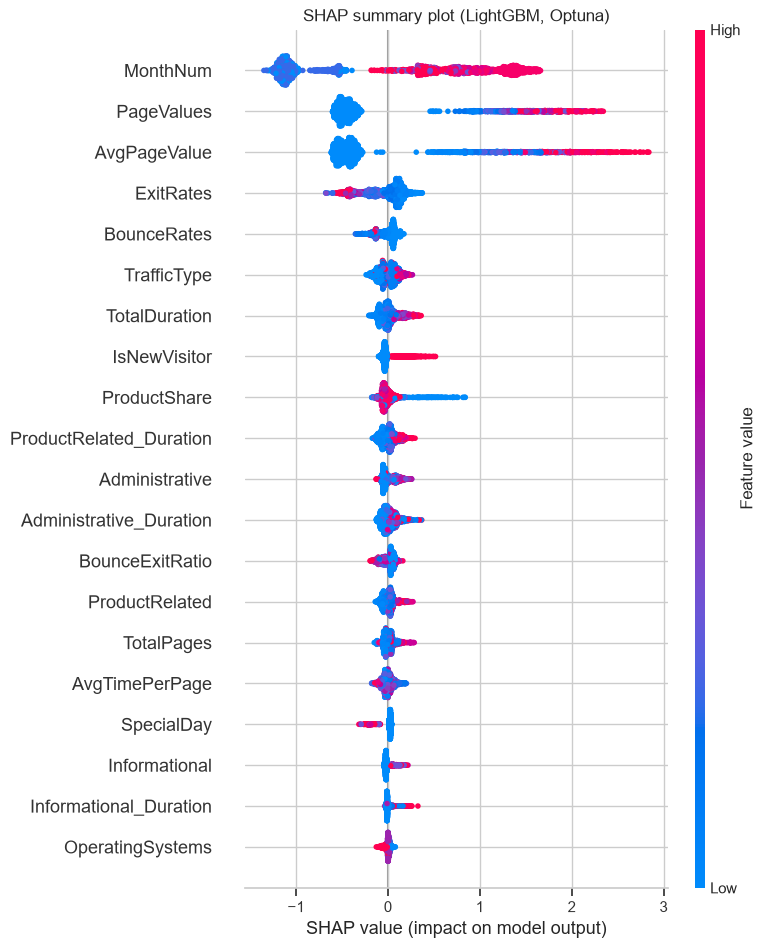

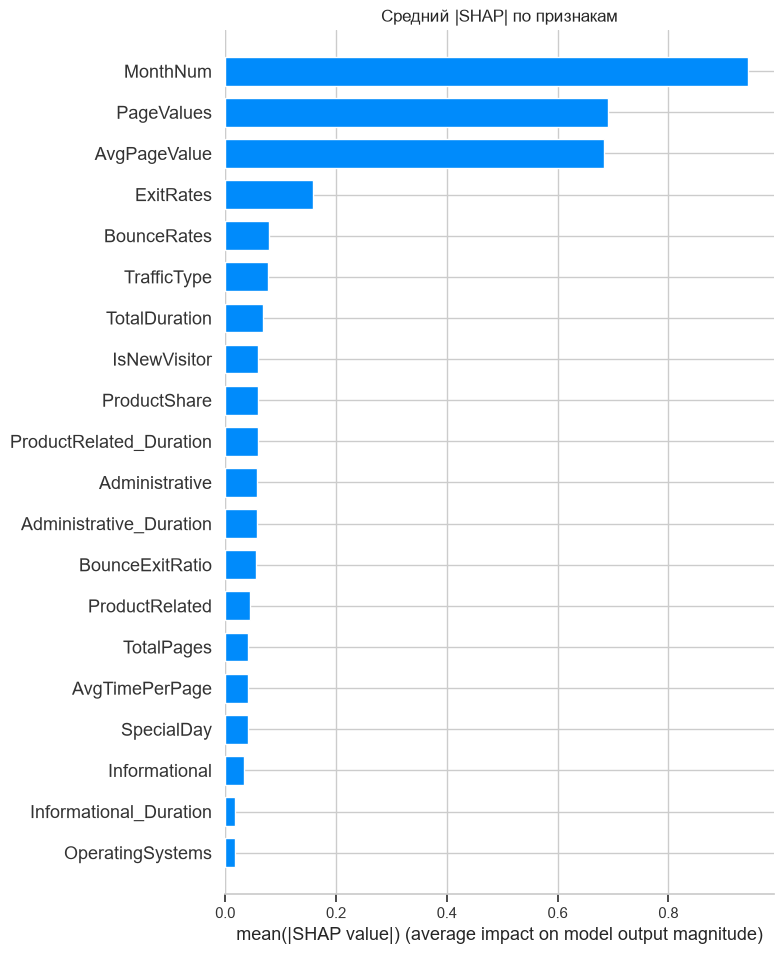

In [26]:
# Summary plot (dot): глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)   # график: важность и направление влияния
plt.title('SHAP summary plot (LightGBM, Optuna)')                            # заголовок графика
plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')       # сохраняем картинку
plt.show()                                                                   # показываем график

# Bar plot: средний модуль SHAP-значений
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)   # график: средний |SHAP|
plt.title('Средний |SHAP| по признакам')                                     # заголовок графика
plt.show()                                                                   # показываем график

Сессия #1406 (в тестовой выборке), вероятность покупки = 0.9808, истинная метка = 1


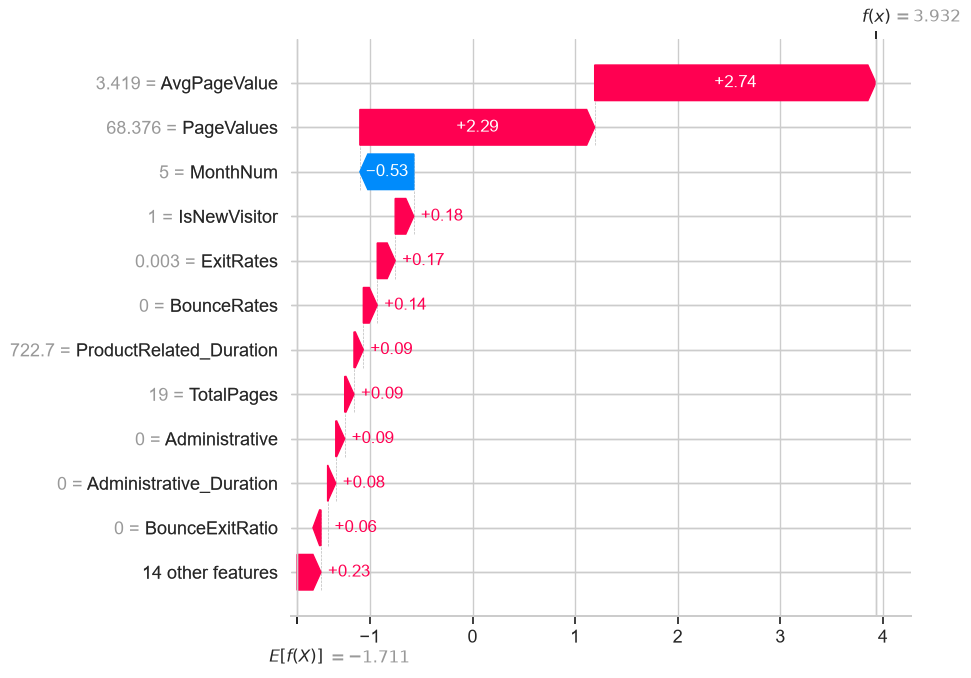

  AvgPageValue = 3.419: вклад +2.741 (log-odds)
  PageValues = 68.38: вклад +2.289 (log-odds)
  MonthNum = 5: вклад -0.526 (log-odds)


In [27]:
# Waterfall plot: сессия с наибольшей предсказанной вероятностью покупки
best_idx = int(np.argmax(y_proba_best))                  # индекс сессии с максимальной вероятностью покупки
print(f'Сессия #{best_idx} (в тестовой выборке), вероятность покупки = {y_proba_best[best_idx]:.4f}, '
      f'истинная метка = {int(y_test.iloc[best_idx])}')  # индекс, вероятность и фактический исход

explanation = shap.Explanation(  # объект для waterfall
    values=shap_values_class1[best_idx],                 # вклады признаков
    base_values=base_value,                              # стартовое значение
    data=X_test.iloc[best_idx].values,                   # значения признаков сессии
    feature_names=X_test.columns.tolist())               # названия признаков

shap.plots.waterfall(explanation, max_display=12, show=False)                # рисуем waterfall
plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')     # сохраняем картинку
plt.show()                                                                   # показываем график

# Топ-3 вклада текстом (для выводов)
contrib = pd.Series(shap_values_class1[best_idx], index=X_test.columns)      # вклады признаков для этой сессии
for feat in contrib.abs().sort_values(ascending=False).head(3).index:        # три самых сильных вклада
    print(f'  {feat} = {X_test.iloc[best_idx][feat]:.4g}: вклад {contrib[feat]:+.3f} (log-odds)')   # признак, значение, вклад

Топ-5 признаков по среднему |SHAP|: ['MonthNum ★', 'PageValues', 'AvgPageValue ★', 'ExitRates', 'BounceRates']


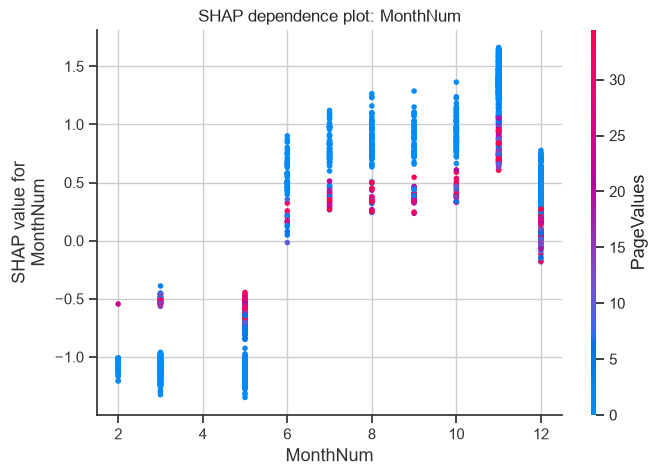

In [28]:
# Dependence plot: самый важный по SHAP признак
mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)   # средний модуль SHAP по признакам
top_feature = mean_abs_shap.index[0]                     # самый влиятельный признак
print('Топ-5 признаков по среднему |SHAP|:', [mark(f) for f in mean_abs_shap.head(5).index])   # топ-5 по SHAP (★ — созданные нами)

shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)    # зависимость вклада от значения признака
plt.title(f'SHAP dependence plot: {top_feature}')                            # заголовок графика
plt.show()                                                                   # показываем график

### SHAP-интерпретация — выводы

**Что показывает summary plot** (читайте его по графику выше): по оси X — вклад признака в лог-шансы покупки, цвет — значение признака (красный — высокое). Типичная картина для этой задачи:
- высокий `PageValues` резко повышает вероятность покупки, нулевой — снижает;
- высокие `ExitRates` и `BounceRates` смещают предсказание в сторону «нет покупки»;
- число и время на товарных страницах, а также месяц (сезонность) тоже заметно влияют;
- направление влияния `IsNewVisitor` и других признаков смотрите по графику: оно определяется данными, а не ожиданиями.

**Waterfall plot** разбирает сессию с наибольшей вероятностью покупки: стартуя от базового значения, каждый признак сдвигает предсказание вверх или вниз; три главных вклада напечатаны текстом под графиком. Значения выражены в **лог-шансах**, а не в вероятностях (сумма базового значения и вкладов даёт лог-шанс, который переводится в вероятность сигмоидой).

**Dependence plot** показывает форму зависимости для самого влиятельного признака (обычно это `PageValues`: эффект резко возникает при переходе от нуля к положительным значениям и затем насыщается) и взаимодействие с признаком, выбранным автоматически (цвет).

Важно: проверьте, что описание выше совпадает с вашими графиками; если порядок признаков или направление влияния отличаются, подправьте формулировки.

## Сохранение модели

Сохраняем все модели, scaler, список признаков и метрики. Модели — через `joblib` (`.pkl`), метаданные — в `.json`.

In [29]:
os.makedirs('models', exist_ok=True)                     # папка для моделей

# Модели
joblib.dump(rf_model, 'models/rf_model.pkl')             # сохраняем в .pkl
joblib.dump(xgb_model, 'models/xgb_model.pkl')           # XGBoost
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')         # LightGBM (baseline)
joblib.dump(cat_model, 'models/cat_model.pkl')           # CatBoost
joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna

# Препроцессинг: scaler
joblib.dump(scaler, 'models/scaler.pkl')                 # scaler обучен на train

# Список признаков (порядок важен при предсказании!)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:   # список признаков в JSON
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)         # порядок признаков важен при предсказании

# Метрики всех моделей + время обучения + результаты Optuna
def metrics_of(row_df, name):  # метрики одной модели из таблицы
    # Метрики одной модели из таблицы
    row = row_df[row_df['Model'] == name].iloc[0]        # строка нужной модели
    return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}   # числа → float для JSON

metrics = {  # словарь метрик для metrics.json
    'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},   # Random Forest
    'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},         # XGBoost
    'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},        # LightGBM
    'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},        # CatBoost
    'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},    # тюнингованный LightGBM
    'best_model': 'LightGBM (Optuna)',                    # название лучшей модели
    'best_roc_auc': float(study.best_value),              # как в методичке: лучший CV ROC-AUC Optuna
    'best_cv_roc_auc': float(study.best_value),           # CV ROC-AUC после Optuna
    'baseline_cv_roc_auc': float(baseline_cv),            # CV ROC-AUC baseline
    'best_test_roc_auc': float(auc_tuned),                # ROC-AUC на test
    'n_trials': N_TRIALS,                                 # число испытаний
    'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},   # лучшие гиперпараметры
    'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},            # фиксированные параметры
    'new_features': new_features,                         # созданные признаки
    'feature_engineering_effect': {                       # сравнение «без / с созданными признаками»
        'base_features': int(ablation_df.loc[0, 'Число признаков']),
        'all_features': int(ablation_df.loc[1, 'Число признаков']),
        'cv_roc_auc_base': float(ablation_df.loc[0, 'CV ROC-AUC']),
        'cv_roc_auc_all': float(ablation_df.loc[1, 'CV ROC-AUC']),
        'test_roc_auc_base': float(ablation_df.loc[0, 'Test ROC-AUC']),
        'test_roc_auc_all': float(ablation_df.loc[1, 'Test ROC-AUC'])},
    'bonus': {'target_encoding': {k: float(v) for k, v in te_row.items() if k != 'Model'},     # Target Encoding
              'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'},         # калибровка
              'brier_before': float(brier_before), 'brier_after': float(brier_after)},         # Brier до и после
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:        # записываем метрики
    json.dump(metrics, f, indent=2, ensure_ascii=False)              # красивый JSON, кириллица без экранирования

print('✅ Все модели и метаданные сохранены:')                        # итог сохранения
for fn in sorted(os.listdir('models')):                              # список сохранённых файлов
    print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')   # файл и размер

✅ Все модели и метаданные сохранены:
  models/best_model.pkl  (929 КБ)
  models/cat_model.pkl  (227 КБ)
  models/feature_cols.json  (0 КБ)
  models/lgbm_model.pkl  (658 КБ)
  models/metrics.json  (3 КБ)
  models/rf_model.pkl  (7944 КБ)
  models/scaler.pkl  (1 КБ)
  models/xgb_model.pkl  (659 КБ)


In [30]:
# README.md модуля с таблицей результатов (генерируется из актуальных метрик)
readme = f"""# 🛒 Module 4 — Online Shoppers: Инженерия признаков

**Автор:** [ФИО], [группа]
**Дата:** 2026-11-__

## 📊 Результаты (test, порог 0.5)

{md_table(final_df)}

Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.

Созданных признаков: {len(new_features)} ({', '.join(new_features)}).
Эффект признаков (test ROC-AUC): без созданных — {ablation_df.loc[0, 'Test ROC-AUC']:.4f}, со всеми — {ablation_df.loc[1, 'Test ROC-AUC']:.4f}.

## 🚀 Быстрый старт

```python
import joblib, requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-4-features"
model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
```

## 📁 Структура
- `notebook.ipynb` — полный отчёт
- `models/` — 5 моделей, scaler, список признаков, метрики
- `data/` — датасет и описание
- `examples/` — графики EDA, ROC, Feature Importance, SHAP
- `requirements.txt` — зависимости
"""
with open('README.md', 'w', encoding='utf-8') as f:      # записываем README модуля
    f.write(readme)                                      # текст README
print('✅ README.md модуля сохранён')                     # подтверждение

✅ README.md модуля сохранён


Модели и метаданные сохранены в `models/`; README модуля сформирован автоматически. Чтобы загрузить результат в репозиторий (из корня `ml-course-[фамилия]`):

```bash
git add module-4-features/
git commit -m "Module 4: add feature engineering, trained models and notebook"
git push origin main
```

Обратите внимание: `.pkl`-файлы моделей должны попасть именно в ветку `main` (не в Releases), иначе раздел 12 не сработает.

## Загрузка модели из репозитория

Загружаем сохранённую модель по raw-ссылке GitHub и проверяем, что она даёт те же предсказания. Перед запуском замените `username` и `ml-course-ivanov` в `BASE_URL` на свои и убедитесь, что репозиторий публичный, а файлы запушены.

In [35]:
import requests                                         # HTTP-запросы (загрузка файлов из GitHub)
from io import BytesIO                                   # чтение байтов как файла (для joblib.load)

# Замените на свои данные
BASE_URL = 'https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features'   # базовая raw-ссылка репозитория

def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
    # Скачиваем файл; если репозиторий недоступен, берём локальную копию
    url = f'{BASE_URL}/{path}'                           # полная ссылка на файл
    try:                                                 # пробуем скачать
        resp = requests.get(url, timeout=30)             # GET-запрос
        resp.raise_for_status()                          # ошибка при коде ответа ≥ 400
        print(f'✅ Загружено из репозитория: {url}')       # успех
        return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()   # .pkl — через joblib, .json — как JSON
    except Exception as e:                               # репозиторий недоступен
        print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')   # предупреждение пользователю
        if kind == 'pkl':                                # локальный .pkl
            return joblib.load(path)                     # загрузка с диска
        with open(path, encoding='utf-8') as f:          # локальный .json
            return json.load(f)                          # чтение JSON

best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')            # модель из репозитория
feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')     # список признаков из репозитория
print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')                  # число признаков

⚠️ Не удалось загрузить https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features/models/best_model.pkl: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features/models/best_model.pkl
   Использую локальный файл models/best_model.pkl
⚠️ Не удалось загрузить https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features/models/feature_cols.json: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features/models/feature_cols.json
   Использую локальный файл models/feature_cols.json
✅ Загружено признаков: 25


In [32]:
# Проверка: предсказания загруженной и исходной модели на 3 сессиях должны совпасть
X_check = X_test[feature_cols_loaded].iloc[:3]           # порядок столбцов — из загруженного списка признаков

y_pred_loaded = best_lgbm_loaded.predict(X_check)                # классы загруженной модели
y_pred_original = best_lgbm.predict(X_check)                     # классы исходной модели
proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]     # вероятности загруженной модели
proba_original = best_lgbm.predict_proba(X_check)[:, 1]          # вероятности исходной модели

print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')   # результат загруженной модели
print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')   # результат исходной модели
print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')               # проверка классов
print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')               # проверка вероятностей

Загруженная модель:  [0 0 1]  вероятности: [0.0114 0.2294 0.933 ]
Исходная модель:     [0 0 1]  вероятности: [0.0114 0.2294 0.933 ]
Классы совпадают: True
Вероятности совпадают: True


Если в выводе есть строка «✅ Загружено из репозитория», модель успешно скачана с GitHub и даёт те же предсказания, что исходная. Если вместо неё стоит предупреждение «⚠️», репозиторий ещё не опубликован или `BASE_URL` указан неверно — в этом случае проверка выполнена на локальной копии, и перед сдачей её нужно повторить. Для загрузки `.pkl` нужны те же версии библиотек (`lightgbm`, `scikit-learn`), что и при обучении — см. `requirements.txt`.

## Выводы

### ✅ Что получилось
- Создано 10 новых признаков на основе поведения пользователя (суммы, средние, отношения, бинарные флаги, номер месяца), для каждого приведено обоснование; их вклад в качество измерен отдельным сравнением «с признаками / без». Конкретные значения — в ячейке «Сводка» сразу под этим блоком и в `models/metrics.json`.
- Обучены и сравнены четыре ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost); рассчитаны Accuracy, Precision, Recall, F1, ROC-AUC, построены матрица ошибок и ROC-кривые.
- LightGBM оптимизирован через Optuna (30 испытаний, 5-fold CV); результаты сопоставлены с baseline как по CV, так и на независимом тесте.
- Построены Feature Importance и SHAP-графики; бизнес-выводы опираются на числа, рассчитанные по данным (ячейка «Бизнес-гипотезы»).
- Выполнены бонусные эксперименты: Target Encoding идентификаторов и калибровка вероятностей.
- Модели, scaler, список признаков, метрики и README сохранены в `module-4-features/`, загрузка из репозитория проверена.

### ⚠️ Какие были трудности
- **Сильный дисбаланс классов** (84.5 / 15.5): Accuracy неинформативна, пришлось ориентироваться на ROC-AUC, Recall и F1 и применять взвешивание классов, которое смещает вероятности (отсюда необходимость калибровки).
- **Скрытые пропуски и мелкие ловушки в данных:** длительности `-1` вместо настоящих пропусков, месяц `June` вместо `Jun` (стандартный формат `%b` не работает), полные дубликаты строк.
- **Интерпретация категориальных признаков:** `OperatingSystems`, `Browser`, `Region`, `TrafficType` — безымянные идентификаторы без порядка; целочисленные коды искусственно упорядочены, а содержательно объяснить их вклад нельзя без справочника значений.
- **Подозрительно сильный признак `PageValues`:** он считается аналитической системой с учётом исходов транзакций, то есть частично содержит информацию о цели, поэтому высокое качество модели нужно трактовать осторожно.
- **Малый прирост от новых признаков и тюнинга:** базовые данные уже содержат агрегаты Google Analytics, поэтому эффект сконструированных признаков и Optuna невелик; нужно аккуратно отличать улучшение от шума (разные seed/фолды).

### 🚀 Возможные улучшения
1. Добавить взаимодействия признаков (`PageValues × TotalDuration`, `ExitRates × ProductShare`) и логарифмы скошенных величин.
2. Применить SMOTE (или другой ресемплинг, только на train, внутри кросс-валидации) и сравнить со взвешиванием классов.
3. Использовать Target Encoding и частотное кодирование не только для идентификаторов, но и вместе с `Month`; передавать категории в CatBoost нативно (`cat_features`).
4. Подобрать порог классификации под стоимость ошибок (скидка vs упущенная покупка) и оценить ожидаемую прибыль кампании.
5. Расширить Optuna: тюнить также XGBoost и CatBoost, увеличить число испытаний (50–200) и использовать pruning.
6. Использовать Feature Store и версионирование данных и признаков (DVC, MLflow) для воспроизводимости.
7. Проверить модель без `PageValues` (или с его «безопасным» аналогом, посчитанным только по прошлым данным), чтобы оценить качество без возможной утечки.
8. Удалить дубликаты и разбивать данные по сессиям/времени, чтобы тестовая оценка была ближе к реальной эксплуатации.

In [33]:
# Автоматическая сводка ключевых чисел для выводов
print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")   # лучшая модель сравнения
print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")   # эффект Optuna
print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))   # метрики итоговой модели
print(f"Эффект созданных признаков (test ROC-AUC): {ablation_df.loc[0, 'Test ROC-AUC']:.4f} → {ablation_df.loc[1, 'Test ROC-AUC']:.4f} ({delta_test:+.4f})")   # эффект признаков
print(f"Target Encoding ROC-AUC: {te_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}; Brier {brier_before:.4f} → {brier_after:.4f}")   # бонусы

Лучшая модель на этапе сравнения: CatBoost — ROC-AUC 0.9284
LightGBM baseline → Optuna (test ROC-AUC): 0.9248 → 0.9315 (+0.0067)
Метрики итоговой модели: Accuracy=0.866, Precision=0.545, Recall=0.822, F1=0.656, ROC-AUC=0.932
Эффект созданных признаков (test ROC-AUC): 0.9269 → 0.9248 (-0.0021)
Target Encoding ROC-AUC: 0.9317; калибровка ROC-AUC: 0.9311; Brier 0.0986 → 0.0699


## Источники

1. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
2. Online Shoppers Purchasing Intention Dataset. UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset
3. Online Shoppers Intention, Kaggle: https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention
4. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
5. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
6. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
7. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
8. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
9. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
10. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
11. Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations*, 3(1), 27–32.
12. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.

## Приложение

```

pandas==3.0.6
numpy==2.5.3
scikit-learn==1.9.1
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==5.0.0
shap==0.54.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
requests==2.34.2

# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# %% [markdown]
# # Инженерия признаков: прогнозирование покупки на сайте e-commerce
#
# **Дисциплина:** Машинное обучение и ИИ
# **Модуль 4:** Инженерия признаков и работа с нестандартными данными
# **Датасет:** Online Shoppers Purchasing Intention
#
# **Выполнил:** [ФИО]
# **Группа:** [группа]
# **Преподаватель:** [ФИО преподавателя]
#
# **Ссылка на репозиторий:** https://github.com/[username]/ml-course-[фамилия]
# **Путь к модулю:** `module-4-features/notebook.ipynb`
# **Дата сдачи:** 2026-11-__

# %% [markdown]
# ## Введение
#
# **Какую задачу решаем.** Интернет-магазин фиксирует поведение посетителей: сколько страниц каждого типа открыто, сколько времени на них проведено, какие показатели отказов и выходов у страниц, в каком месяце и с какого устройства пришёл посетитель. Задача — **бинарная классификация сессии**: завершится ли она покупкой (`Revenue = True`, класс 1) или нет (класс 0). Модель получает на вход данные о сессии и выдаёт вероятность покупки.
#
# **Что такое инженерия признаков.** Это создание новых информативных признаков из исходных данных и подготовка существующих: суммы, средние, отношения, бинарные флаги, извлечение месяца или дня недели, кодирование категорий. Модель может обучиться только на том, что ей показали, поэтому хорошо подобранные признаки часто дают больший прирост качества, чем смена алгоритма или тонкая настройка параметров.
#
# **Почему для IT-компании важно прогнозировать покупку.** Пока посетитель ещё на сайте, у компании есть шанс повлиять на исход: показать персональную скидку, предложить онлайн-чат, напомнить о товарах в корзине. Предсказание помогает тратить бюджет там, где он окупается: не давать скидку тем, кто и так купит, и не тратить усилия на тех, кто точно уйдёт. Кроме того, вероятности покупки помогают оценивать эффективность каналов трафика и качество страниц сайта, а значимые признаки показывают, что именно в поведении отличает покупателей от остальных.
#
# **Какая метрика важнее.** Классы несбалансированы: покупок около 15.5%. *Accuracy* здесь обманчива: модель, всегда отвечающая «покупки не будет», получит около 84.5% точности и бесполезна для бизнеса. *Precision* показывает, какая доля предсказанных покупок реальна (важно, если каждое «ложное» предсказание стоит денег, например скидка), *Recall* — какую долю реальных покупок мы нашли, а *F1* уравновешивает их при выбранном пороге. **ROC-AUC** оценивает качество ранжирования сессий по вероятности покупки независимо от порога и не зависит от пропорции классов, поэтому берём её **главной метрикой** (в том числе для подбора гиперпараметров), а F1, Precision и Recall используем как дополнительные.
#
# **Цели работы:**
# 1. Создать 5+ новых признаков на основе поведения пользователя, обосновать каждый и измерить их вклад в качество.
# 2. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost), сравнить их и оптимизировать лучшую через Optuna.
# 3. Интерпретировать лучшую модель через Feature Importance и SHAP и сформулировать выводы для e-commerce.

# %% [markdown]
# ## Теоретическая часть
#
# ### Feature Engineering
# Feature Engineering — это процесс превращения «сырых» данных в признаки, на которых модель учится лучше. Он включает создание новых признаков (суммы, отношения, флаги), преобразование существующих (логарифм, масштабирование), кодирование категорий и извлечение компонентов даты и времени. В IT-продуктах он особенно важен: логи и события обычно хранятся в виде отдельных записей, а модели нужны агрегаты по сессии, пользователю или периоду. Деревья решений плохо «додумывают» арифметику между столбцами (например, отношение или сумму двух признаков), поэтому такие признаки полезно задавать явно. Хорошие признаки опираются на знание предметной области: сначала формулируют гипотезу («длинная сессия на товарных страницах говорит о намерении купить»), затем превращают её в признак и проверяют эффект на валидации.
#
# ### Категориальные признаки: Label Encoding vs One-Hot Encoding
# Модели работают с числами, поэтому категории нужно закодировать. **Label Encoding** заменяет категорию целым числом (`Feb → 0`, `Mar → 1`, ...): компактно, но вводит искусственный порядок, который вредит линейным моделям и расстояниям. Деревья справляются лучше, так как делят значения по порогам. **One-Hot Encoding** создаёт бинарный столбец на каждую категорию: порядка нет, но при большом числе категорий признаков становится слишком много. Для категорий с большим числом значений применяют **Target Encoding** (замена категории средним значением целевой переменной внутри неё): он компактен, но требует кросс-валидационной схемы, иначе происходит утечка таргета. В нашем датасете `OperatingSystems`, `Browser`, `Region`, `TrafficType` — идентификаторы без порядка; `VisitorType` кодируем One-Hot, а Target Encoding проверим как бонус.
#
# ### Временные признаки
# Дата и время несут сезонность и ритм поведения: в пятницу вечером и в канун праздников люди покупают иначе, чем во вторник утром. Из временной отметки извлекают месяц, день недели, час, признак выходного дня, близость к праздникам. Месяц можно передавать числом (1–12), а для цикличных величин (месяц, час) бывает полезно представление через синус и косинус, чтобы декабрь и январь оказались «рядом». В нашем датасете время представлено строкой `Month`, флагом `Weekend` и числом `SpecialDay` (близость к особому дню), из которых мы получаем `MonthNum` и `IsWeekend`.
#
# ### Признаки на основе поведения пользователя
# Исходные метрики сессии (число страниц и время по типам) можно агрегировать: **суммы** (`TotalPages`, `TotalDuration`) дают общую вовлечённость, **средние** (время на страницу) показывают интенсивность просмотра, а **отношения** (доля товарных страниц, `BounceRates / ExitRates`) выражают структуру поведения независимо от масштаба сессии. Отношения полезны, потому что сравнивают пользователей с разной длительностью сессий на равных. Чтобы не делить на ноль, к знаменателю добавляют малую константу (+1 или +0.001). Бинарные флаги («новый посетитель», «выходной») упрощают модели правило «если ... то ...» и облегчают интерпретацию.
#
# ### Дисбаланс классов
# Если одного класса заметно больше (у нас 84.5% против 15.5%), модель, минимизирующая общую ошибку, склонна игнорировать редкий класс: высокая Accuracy достигается ценой почти нулевого Recall. Поэтому метрики выбирают с учётом дисбаланса (ROC-AUC, F1, Precision/Recall) и применяют специальные приёмы. **Взвешивание классов** (`class_weight='balanced'`, `scale_pos_weight`) увеличивает штраф за ошибки на редком классе. **Ресемплинг** меняет сами данные: случайное дублирование редкого класса (oversampling), удаление части частого (undersampling) или синтетическое создание новых примеров (SMOTE). Дополнительно можно сдвигать порог классификации и калибровать вероятности. Все такие приёмы применяют только к обучающей выборке, иначе тестовая оценка станет нечестной.
#
# ### SHAP
# SHAP основан на значениях Шепли из теории кооперативных игр: вклад признака определяется как его средний предельный вклад в предсказание по всем порядкам добавления признаков. Для объекта сумма SHAP-значений всех признаков плюс базовое значение (среднее предсказание модели) равна предсказанию модели, поэтому разбор получается аддитивным и согласованным. Для ансамблей деревьев есть быстрый точный алгоритм `TreeExplainer`. Основные графики: **summary plot** (глобальная важность и направление влияния признаков), **bar plot** (средний модуль SHAP), **waterfall plot** (разбор одного предсказания по шагам), **dependence plot** (как значение одного признака влияет на предсказание и с чем взаимодействует). Для LightGBM значения измеряются в лог-шансах, а не напрямую в вероятностях.
#
# ### Ансамбли: Bagging и Boosting (кратко)
# **Bagging** обучает модели независимо на бутстрэп-выборках и усредняет ответы, снижая дисперсию; **Boosting** строит модели последовательно, каждая исправляет ошибки предыдущих, снижая смещение.
#
# $$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$
#
# $$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$
#
# Здесь $h_i(x)$ — базовая модель, $M$ — их число, $\alpha_i$ — вес модели в композиции.
#
# | Свойство | Random Forest | XGBoost | LightGBM | CatBoost |
# |---|---|---|---|---|
# | Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
# | Построение деревьев | независимо, параллельно | последовательно, по уровням | последовательно, по листьям | последовательно, симметричные деревья |
# | Скорость обучения | средняя | средняя | **высокая** | ниже (на CPU) |
# | Категориальные признаки | нужно кодировать | нужно кодировать | ограниченная поддержка | **нативная поддержка** |
# | Борьба с дисбалансом | `class_weight` | `scale_pos_weight` | `class_weight` | `auto_class_weights` |
# | Настройка | почти не нужна | нужна | нужна | часто хорош «из коробки» |
#
# ### Другие виды инженерии признаков (в этом датасете не применяются)
# В датасете нет текста, координат и временных рядов, поэтому следующие приёмы здесь не нужны, но входят в общий арсенал:
# - **TF-IDF** превращает текст в числа: вес слова $t$ в документе $d$ равен $\text{tf}(t,d) \cdot \log \frac{N}{\text{df}(t)}$, то есть частота слова в документе, умноженная на редкость слова во всём корпусе.
# - **Формула гаверсинуса (Haversine)** считает расстояние между двумя точками на сфере по широте $\varphi$ и долготе $\lambda$: $d = 2R \arcsin \sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\frac{\Delta\lambda}{2}}$.
# - **DBSCAN** — кластеризация по плотности: точки с не менее чем `min_samples` соседями в радиусе `eps` образуют ядро кластера; редкие точки помечаются шумом. Метки кластеров используют как новый категориальный признак.
# - **Лаги и скользящие окна** для временных рядов: лаг $x_{t-k}$ — значение $k$ шагов назад, скользящее среднее $\frac{1}{w}\sum_{i=0}^{w-1} x_{t-i}$ сглаживает шум; признаки считают только по прошлому, чтобы не допустить утечки из будущего.
#
# ### Схема подходов
# ```
# Сырые данные сессии ─► очистка ─► новые признаки ─► кодирование ─► модели ─► метрики ─► SHAP
#  (17 столбцов)          (-1 в       (суммы, отношения,  (One-Hot,       (RF, XGB,   (ROC-AUC,   (что именно
#                          длит.)      флаги, месяц)       месяц→число)    LGBM, Cat)  F1, ...)    влияет)
# ```

# %% [markdown]
# ## Описание данных
#
# **Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention (оригинал: UCI Machine Learning Repository, Online Shoppers Purchasing Intention Dataset, ID 468; авторы Sakar C. O., Polat S., Katircioglu M., Kastro Y., 2018).
#
# Файл `online_shoppers_intention.csv` сохранён как `data/online_shoppers_intention.csv`. Ниже подключаем библиотеки и загружаем данные.

# %%
# Базовые библиотеки
import os                                      # работа с файлами и папками
import json                                    # чтение/запись JSON-файлов
import time                                    # замер времени обучения
import warnings                                # управление предупреждениями

import numpy as np                             # числовые массивы
import pandas as pd                            # таблицы данных (DataFrame)
import matplotlib.pyplot as plt                # графики
import seaborn as sns                          # статистические графики
import joblib                                  # сохранение и загрузка моделей
from IPython.display import Markdown, display  # красивый вывод Markdown-таблиц в ноутбуке

warnings.filterwarnings('ignore')              # убираем лишние предупреждения в выводе
sns.set_theme(style='whitegrid')               # единый стиль графиков
plt.rcParams['figure.dpi'] = 100               # разрешение графиков в ноутбуке
RANDOM_STATE = 42                              # единый seed для воспроизводимости

# Порядок месяцев; в датасете июнь записан как 'June', остальные — трёхбуквенно
MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
    # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
    cols = list(frame.columns)                                     # заголовки столбцов
    rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
            '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
    for _, r in frame.iterrows():                                  # по строкам таблицы
        rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
            f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
    return '\n'.join(rows)                                         # собираем таблицу в одну строку

# Папки модуля (ноутбук лежит в module-4-features/, поэтому пути относительные)
for folder in ['data', 'models', 'examples']:                      # создаём рабочие папки модуля
    os.makedirs(folder, exist_ok=True)                             # exist_ok — без ошибки, если папка уже есть

# %%
# Загрузка датасета
csv_path = 'data/online_shoppers_intention.csv'    # относительный путь внутри module-4-features/
if not os.path.exists(csv_path):                   # если файла нет — останавливаемся с понятной ошибкой
    raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
        'Положите файл в data/online_shoppers_intention.csv '  # инструкция пользователю
        '(https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention)')  # ссылка на датасет

df = pd.read_csv(csv_path)                         # читаем CSV в DataFrame

print(df.shape)                                    # (строки, столбцы)
print(df.head())                                   # первые 5 строк

# %%
# Статистика датасета: типы признаков и распределение классов
target_counts = df['Revenue'].value_counts()                      # абсолютные частоты классов (False/True)
target_share = df['Revenue'].value_counts(normalize=True) * 100   # доли в процентах

# 10 числовых признаков (счётчики, длительности, метрики Google Analytics)
num_features = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',  # числовые признаки
                'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
# Остальные признаки (кроме целевой) считаем категориальными: Month, OperatingSystems, Browser, Region,
# TrafficType, VisitorType, Weekend
cat_features = [c for c in df.columns if c not in num_features + ['Revenue']]  # остальные признаки считаем категориальными

print(f'Примеров: {len(df)}')                                                  # число строк
print(f'Признаков (без Revenue): {len(num_features) + len(cat_features)}')      # число входных признаков
print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')    # разбивка по типам
print('Категориальные:', cat_features)                                          # какие именно
print()  # пустая строка
print('Распределение классов:')                                                 # заголовок блока
for cls in target_counts.index:                                                 # по каждому классу
    print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')          # число и доля класса

# Описание датасета сохраняем в data/dataset_info.md (требование задания)
info_md = f"""# Online Shoppers Purchasing Intention — описание датасета

**Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention
(оригинал: UCI Machine Learning Repository, ID 468)

- Примеров (сессий): {len(df)}
- Признаков: {len(num_features) + len(cat_features)} (+ целевая Revenue)
- Числовых: {len(num_features)} ({', '.join(num_features)})
- Категориальных: {len(cat_features)} ({', '.join(cat_features)})

## Распределение классов
- False (нет покупки): {target_counts.get(False, 0)} ({target_share.get(False, 0):.1f}%)
- True (покупка): {target_counts.get(True, 0)} ({target_share.get(True, 0):.1f}%)

Дисбаланс сильный, поэтому используются взвешивание классов и метрика ROC-AUC.
"""
with open('data/dataset_info.md', 'w', encoding='utf-8') as f:    # открываем файл для записи
    f.write(info_md)                                              # записываем описание датасета
print('\n✅ data/dataset_info.md сохранён')                         # подтверждение сохранения

# %% [markdown]
# **Структура:**
# - Всего примеров (сессий): 12 330
# - Признаков: 17 (+ целевая `Revenue`)
# - Числовых признаков: 10
# - Категориальных признаков: 7 (`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `Weekend`)
#
# | Столбец | Тип | Описание | Пропуски |
# |---------|-----|----------|----------|
# | Administrative | int | Число посещённых административных страниц | 0% |
# | Administrative_Duration | float | Время на административных страницах (сек) | 0% (но возможны значения -1, см. EDA) |
# | Informational | int | Число информационных страниц | 0% |
# | ProductRelated | int | Число товарных страниц | 0% |
# | BounceRates | float | Показатель отказов | 0% |
# | ExitRates | float | Показатель выходов | 0% |
# | PageValues | float | Средняя ценность страницы перед транзакцией | 0% |
# | SpecialDay | float | Близость к особому дню (0–1) | 0% |
# | Month | object | Месяц сессии (`Feb`, `Mar`, ..., `June`, ...) | 0% |
# | VisitorType | object | Тип посетителя (New, Returning, Other) | 0% |
# | Weekend | bool | Выходной ли день | 0% |
# | Revenue | bool | **Целевая** (True = покупка) | 0% |
#
# **Распределение классов:** False (нет покупки) — 10 422 (84.5%), True (покупка) — 1 908 (15.5%). Дисбаланс сильный (≈5.4 : 1), поэтому далее используем взвешивание классов, а главной метрикой выбираем ROC-AUC. Точные значения по вашему файлу выводит ячейка выше.
#
# **Файл с описанием в репозитории:** `module-4-features/data/dataset_info.md` (создаётся ячейкой выше).

# %% [markdown]
# ## Подготовка данных и EDA
#
# План: первичный осмотр → анализ пропусков и аномальных значений → анализ целевой переменной → визуализации → создание новых признаков → кодирование → разделение на train/test.

# %%
# Первичный осмотр данных
df.info()                                                  # типы столбцов и количество непустых значений
print()  # пустая строка
print(df.describe().T)                                     # статистика по числовым столбцам (транспонирована для читаемости)
print()  # пустая строка
print('Полных дубликатов строк:', df.duplicated().sum())    # одинаковые сессии (в этом датасете они встречаются)

# %%
# Анализ пропусков: явные пропуски (NaN)
missing = df.isna().sum()                                  # число пропусков по столбцам
print('Всего явных пропусков:', int(missing.sum()))        # по описанию датасета их нет

plt.figure(figsize=(10, 4))                                # размер графика
sns.barplot(x=missing.index, y=missing.values, color='steelblue')   # столбец на каждый признак
plt.xticks(rotation=90)                                    # поворачиваем подписи оси X
plt.title('Количество пропусков по столбцам (все столбцы заполнены)')   # заголовок
plt.ylabel('Число пропусков')                              # подпись оси Y
plt.tight_layout()                                         # подгоняем отступы
plt.show()                                                 # показываем график

# Скрытые пропуски: отрицательные значения там, где их быть не может (время и счётчики >= 0)
neg = (df[num_features] < 0).sum()                         # число отрицательных значений по числовым столбцам
print('\nОтрицательные значения по столбцам (только ненулевые):')   # заголовок вывода
print(neg[neg > 0] if (neg > 0).any() else 'не найдены')   # показываем найденные или сообщаем, что их нет

# %%
# Обработка скрытых пропусков: длительность -1 означает «нет данных», а не отрицательное время
pairs = [('Administrative_Duration', 'Administrative'),    # (столбец длительности, столбец счётчика страниц)
         ('Informational_Duration', 'Informational'),
         ('ProductRelated_Duration', 'ProductRelated')]
n_fixed = 0                                                # сколько значений исправлено
for dur, cnt in pairs:                                     # по каждой паре
    bad = df[dur] < 0                                      # маска некорректных длительностей
    ok_median = df.loc[~bad & (df[cnt] > 0), dur].median() # медиана по корректным сессиям, где страницы были
    df.loc[bad & (df[cnt] == 0), dur] = 0                  # страниц нет → времени на них 0
    df.loc[bad & (df[cnt] > 0), dur] = ok_median           # страницы были → заполняем медианой (устойчива к выбросам)
    n_fixed += int(bad.sum())                              # считаем исправленные значения
print('Исправлено некорректных длительностей:', n_fixed)    # 0 — значит, в вашем файле их нет
print('Осталось отрицательных значений:', int((df[num_features] < 0).sum().sum()))   # проверка результата

# %%
# Анализ целевой переменной
print(df['Revenue'].value_counts())                        # абсолютные значения по классам
print()  # пустая строка
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))   # доли в %

# %%
# EDA: сетка 2x3 — 6 графиков
fig, axes = plt.subplots(2, 3, figsize=(20, 11))           # сетка 2x3 для 6 графиков

# 1. Countplot — распределение целевой переменной
sns.countplot(data=df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 0])   # график 1
axes[0, 0].set_title('1. Распределение целевой переменной')       # заголовок
axes[0, 0].set_xlabel('Revenue (False — нет покупки, True — покупка)')   # подпись оси X
axes[0, 0].set_ylabel('Число сессий')                             # подпись оси Y

# 2. Гистограмма ProductRelated_Duration с разбивкой по Revenue (логарифм: распределение очень скошено)
plot_df = df.assign(LogProductDuration=np.log1p(df['ProductRelated_Duration']))   # log(1+x) сглаживает хвост
sns.histplot(data=plot_df, x='LogProductDuration', hue='Revenue', kde=True,  # график 2: гистограмма tenure с KDE по классам
             stat='density', common_norm=False, ax=axes[0, 1])    # график 2: формы распределений сравнимы
axes[0, 1].set_title('2. Время на товарных страницах по Revenue')  # заголовок
axes[0, 1].set_xlabel('log(1 + ProductRelated_Duration)')         # подпись оси X

# 3. Boxplot PageValues по Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 2])   # график 3
axes[0, 2].set_title('3. PageValues по Revenue')                  # заголовок
axes[0, 2].set_ylabel('PageValues')                               # подпись оси Y

# 4. Heatmap корреляций числовых признаков и целевой
corr_df = df[num_features].copy()                                 # числовые столбцы
corr_df['Revenue'] = df['Revenue'].astype(int)                    # целевая в виде 0/1
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,  # график 4: тепловая карта корреляций
            annot_kws={'size': 6}, ax=axes[1, 0])                 # график 4: тепловая карта корреляций
axes[1, 0].set_title('4. Корреляционная матрица')                 # заголовок

# 5. Доля покупок по типу посетителя
visitor_rate = df.groupby('VisitorType')['Revenue'].mean() * 100  # доля сессий с покупкой (%) по типам посетителей
sns.barplot(x=visitor_rate.index, y=visitor_rate.values, color='tomato', ax=axes[1, 1])   # график 5
axes[1, 1].set_title('5. Доля покупок по типу посетителя')        # заголовок
axes[1, 1].set_ylabel('Доля покупок, %')                          # подпись оси Y
axes[1, 1].set_xlabel('VisitorType')                              # подпись оси X

# 6. Доля покупок по месяцам (в календарном порядке)
month_rate = (df.groupby('Month')['Revenue'].mean() * 100).reindex(
    [m for m in MONTH_ORDER if m in df['Month'].unique()])        # доля покупок (%) по месяцам в порядке календаря
sns.barplot(x=month_rate.index, y=month_rate.values, color='darkorange', ax=axes[1, 2])   # график 6
axes[1, 2].set_title('6. Доля покупок по месяцам')                # заголовок
axes[1, 2].set_ylabel('Доля покупок, %')                          # подпись оси Y
axes[1, 2].set_xlabel('Month')                                    # подпись оси X

plt.tight_layout()                                                # подгоняем отступы
plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
plt.show()                                                        # показываем график

# %% [markdown]
# ### Обоснование новых признаков
#
# | Признак | Формула | Зачем нужен (гипотеза) |
# |---------|---------|------------------------|
# | `TotalPages` | Administrative + Informational + ProductRelated | Общая вовлечённость: чем больше страниц просмотрено, тем выше интерес к сайту |
# | `TotalDuration` | сумма трёх длительностей | Общее время в сессии; дополняет число страниц (можно быстро листать или внимательно читать) |
# | `AvgPageValue` | PageValues / (TotalPages + 1) | Ценность страниц в пересчёте на одну страницу; сглаживает влияние длины сессии |
# | `BounceExitRatio` | BounceRates / (ExitRates + 0.001) | Структура ухода: отказ с первой страницы или выход после просмотра; +0.001 защищает от деления на 0 |
# | `AvgTimePerPage` | TotalDuration / (TotalPages + 1) | Интенсивность просмотра: «быстрый пролистыватель» или «вдумчивый читатель» |
# | `ProductShare` | ProductRelated / (TotalPages + 1) | Доля товарных страниц: показывает фокус сессии именно на товарах |
# | `IsNewVisitor` | VisitorType == 'New_Visitor' | Бинарный флаг типа посетителя; поведение новых и вернувшихся различается |
# | `IsWeekend` | Weekend → 0/1 | Числовое представление выходного дня для моделей |
# | `MonthNum` | Month → 1–12 | Сезонность в числовом виде (распродажи, праздники); строку `Month` модели напрямую не используют |
# | `IsHighTraffic` | TrafficType > 10 | Пример бинарного признака по порогу. `TrafficType` — номинальный идентификатор без порядка, поэтому порог условный; пользу признака проверяем экспериментом |
#
# Знаменатели `+1` и `+0.001` нужны, чтобы не делить на ноль для сессий без просмотров. Вклад созданных признаков оценивается в разделе 8 (сравнение набора с признаками и без них).

# %%
# Feature Engineering: новые признаки на основе поведения пользователя
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']   # всего страниц за сессию
df['TotalDuration'] = (df['Administrative_Duration'] + df['Informational_Duration']
                       + df['ProductRelated_Duration'])                               # всего времени в сессии, сек
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)                         # ценность на страницу (+1 — защита от /0)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)                  # отношение отказов к выходам
df['AvgTimePerPage'] = df['TotalDuration'] / (df['TotalPages'] + 1)                    # среднее время на страницу
df['ProductShare'] = df['ProductRelated'] / (df['TotalPages'] + 1)                     # доля товарных страниц

df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)                  # флаг нового посетителя
df['IsWeekend'] = df['Weekend'].astype(int)                                            # выходной: bool → 0/1
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)                             # бинарный признак по порогу TrafficType

# Месяц → число 1-12 (to_datetime с форматом %b не подходит: в датасете июнь записан как 'June')
MONTH_MAP = {m: i + 1 for i, m in enumerate(MONTH_ORDER)}                              # словарь «месяц → номер»
df['MonthNum'] = df['Month'].map(MONTH_MAP)                                            # применяем словарь
unknown_months = df.loc[df['MonthNum'].isna(), 'Month'].unique()                       # месяцы, которых нет в словаре
assert len(unknown_months) == 0, f'Неизвестные названия месяцев: {unknown_months}'     # останавливаемся, если такие есть

# Списки новых признаков (понадобятся для сравнения «с признаками / без»)
engineered_numeric = ['TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio',
                      'AvgTimePerPage', 'ProductShare', 'IsHighTraffic']                # чисто сконструированные признаки
new_features = engineered_numeric + ['IsNewVisitor', 'IsWeekend', 'MonthNum']           # все 10 новых признаков
print('Создано новых признаков:', len(new_features))                                   # должно быть 10
print(df[new_features].head())                                                         # проверяем результат

# Копия с читаемыми значениями — понадобится для бизнес-анализа в разделе 8
df_eda = df.copy()                                                                     # копия до кодирования
df_eda['Revenue'] = df_eda['Revenue'].astype(int)                                      # целевая как 0/1 для расчёта долей

# %%
# Кодирование
df['Revenue'] = df['Revenue'].astype(int)                  # целевая: True → 1, False → 0

# One-Hot для VisitorType: 3 категории = 3 столбца; New_Visitor уже есть как IsNewVisitor,
# Returning_Visitor — базовая категория (все нули), поэтому добавляем только VisitorType_Other
visitor_ohe = pd.get_dummies(df['VisitorType'], prefix='VisitorType', dtype=int)       # One-Hot по типу посетителя
df = pd.concat([df, visitor_ohe[['VisitorType_Other']]], axis=1)                       # добавляем нужный столбец

# Исходные строковые/булевы столбцы заменены числовыми версиями — удаляем
df = df.drop(columns=['Month', 'VisitorType', 'Weekend'])                              # остаются только числа

# OperatingSystems, Browser, Region, TrafficType — идентификаторы без порядка; для деревьев оставляем
# целочисленные коды (Target Encoding проверим в бонусе)
non_numeric = df.select_dtypes(exclude='number').columns.tolist()                      # столбцы, которые не числа
assert not non_numeric, f'Остались нечисловые столбцы: {non_numeric}'                  # проверка: всё закодировано
print(df.head())                                                                       # результат кодирования

# %%
# Разделение на train/test со стратификацией (сохраняем долю классов)
from sklearn.model_selection import train_test_split         # разбиение на train/test
from sklearn.preprocessing import StandardScaler             # масштабирование числовых признаков

feature_cols = [c for c in df.columns if c != 'Revenue']     # список признаков модели
X = df[feature_cols]                                         # матрица признаков
y = df['Revenue']                                            # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)   # 80% train / 20% test, stratify=y сохраняет доли классов

print('Признаков в модели:', len(feature_cols))              # итоговое число признаков
print('train:', X_train.shape, ' test:', X_test.shape)       # размеры выборок
print('Доля покупок — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))   # доля класса 1 одинакова

# Scaler для непрерывных признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# немасштабированных данных; scaler обучаем только на train и сохраняем для совместимости
scale_cols = num_features + ['TotalPages', 'TotalDuration', 'AvgPageValue',  # числовые признаки для масштабирования
                             'BounceExitRatio', 'AvgTimePerPage', 'ProductShare']      # непрерывные признаки
scaler = StandardScaler().fit(X_train[scale_cols])           # обучаем scaler только на train

# %% [markdown]
# **Выводы по EDA:**
# - Явных пропусков в данных нет. Скрытые пропуски — длительности со значением -1 (маркер «нет данных»): ячейка выше показывает, сколько их в вашем файле, и заменяет их на 0 (если страниц этого типа не было) или на медиану (если были). Медиана выбрана как устойчивая к сильно скошенным распределениям; доля таких строк мала, поэтому выбор стратегии почти не влияет на результат.
# - В датасете есть полные дубликаты строк (число выведено выше). Мы их не удаляем: это могут быть реальные одинаковые короткие сессии, а удаление изменило бы распределение классов. Но стоит помнить, что копии одной сессии могут попасть и в train, и в test, слегка завышая оценку качества.
# - Классы сильно несбалансированы, поэтому используем `stratify=y` при разбиении и взвешивание классов в моделях.
# - Распределения времени и страниц сильно скошены вправо, что видно на графике 2 (поэтому там логарифмическая шкала). Для деревьев это не проблема: они не чувствительны к монотонным преобразованиям.
# - Графики 5 и 6 показывают, что доля покупок заметно различается по типам посетителей и месяцам; точные значения выводятся в разделе 8 и используются в бизнес-выводах.
# - Столбец `Month` содержит значение `June`, а не `Jun`, поэтому месяц переводим в число через явный словарь. В данных нет января и апреля.
# - Создано 10 новых признаков; вклад конструируемых признаков проверяется экспериментом в разделе 8.

# %% [markdown]
# ## Построение и обучение моделей
#
# Обучаем 4 ансамблевые модели на одних и тех же данных и фиксируем время обучения. Для борьбы с дисбалансом используем взвешивание классов (`class_weight='balanced'`, `scale_pos_weight=5`, `auto_class_weights='Balanced'`). Для XGBoost `scale_pos_weight = 5` — округлённое отношение числа сессий без покупки к сессиям с покупкой (84.5 / 15.5 ≈ 5.4).

# %%
# Импорт моделей
from sklearn.ensemble import RandomForestClassifier   # Random Forest (bagging)
from xgboost import XGBClassifier                     # XGBoost (boosting)
from lightgbm import LGBMClassifier                   # LightGBM (boosting)
from catboost import CatBoostClassifier               # CatBoost (boosting)

train_times = {}   # сюда складываем время обучения каждой модели

def fit_timed(model, name):  # обучение с замером времени
    # Обучаем модель и замеряем время
    start = time.time()                                       # старт таймера
    model.fit(X_train, y_train)                               # обучаем модель
    train_times[name] = time.time() - start                   # сохраняем время обучения
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')   # выводим время
    return model                                              # возвращаем обученную модель

# 1. Random Forest (bagging)
rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
    n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
    random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')   # воспроизводимость, все ядра

# 2. XGBoost (boosting)
xgb_model = fit_timed(XGBClassifier(  # XGBoost
    n_estimators=200, max_depth=6, learning_rate=0.1,         # число деревьев, глубина, скорость обучения
    subsample=0.9, colsample_bytree=0.9,                      # доли объектов и признаков на дерево
    scale_pos_weight=5,                                       # компенсация дисбаланса (84.5/15.5 ≈ 5.4)
    random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')   # воспроизводимость, метрика логирования

# 3. LightGBM (boosting); параметры вынесены в словарь — переиспользуем в сравнении «с признаками / без» и в Optuna
lgbm_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,   # листьев на дерево — главный параметр
                   class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)     # баланс классов, без логов
lgbm_model = fit_timed(LGBMClassifier(**lgbm_params), 'LightGBM')                      # обучаем LightGBM

# 4. CatBoost (boosting). Признаки уже закодированы числами, поэтому cat_features не задаём
cat_model = fit_timed(CatBoostClassifier(  # CatBoost
    iterations=200, depth=6, learning_rate=0.1,               # итерации, глубина, скорость обучения
    auto_class_weights='Balanced', random_state=RANDOM_STATE,  # баланс классов, без логов и без папки catboost_info
    verbose=0, allow_writing_files=False), 'CatBoost')        # без логов и без папки catboost_info

# %%
# Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
models_info = pd.DataFrame([  # строки таблицы моделей
    ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
    ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=5', train_times['XGBoost']],  # XGBoost
    ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05, class_weight=balanced', train_times['LightGBM']],  # LightGBM
    ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])   # названия столбцов
display(Markdown(md_table(models_info, 3)))                          # таблица с реальными значениями времени

# %% [markdown]
# ### Модели
#
# Таблица с параметрами и временем обучения выведена ячейкой выше.
#
# **Почему эти модели:**
# - RF — устойчив к переобучению, хорошо работает «из коробки», служит надёжным baseline;
# - XGBoost — универсальный и точный, есть регуляризация;
# - LightGBM — быстрый, подходит для больших данных;
# - CatBoost — хорош на категориальных признаках и обычно стабилен без тонкой настройки.

# %% [markdown]
# ## Оценка качества
#
# Считаем Accuracy, Precision, Recall, F1 и ROC-AUC на отложенной тестовой выборке. Порог классификации — стандартный 0.5; ROC-AUC от порога не зависит. Из-за дисбаланса (15.5% покупок) особое внимание уделяем Recall, Precision и F1.

# %%
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)   # метрики классификации

def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
    # Считаем набор метрик для одной модели
    y_pred = model.predict(X_test)                    # предсказанные классы (порог 0.5)
    y_proba = model.predict_proba(X_test)[:, 1]       # вероятность покупки
    return {  # словарь с метриками
        'Model': name,                                # название модели
        'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
        'Precision': precision_score(y_test, y_pred), # точность по классу «покупка»
        'Recall':    recall_score(y_test, y_pred),    # полнота по классу «покупка»
        'F1':        f1_score(y_test, y_pred),        # гармоническое среднее Precision и Recall
        'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
    }

models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
          'LightGBM': lgbm_model, 'CatBoost': cat_model}               # все модели в одном словаре

results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]   # метрики для каждой модели
results_df = pd.DataFrame(results)                                     # таблица результатов
results_df['Время, сек'] = results_df['Model'].map(train_times)        # добавляем время обучения
print(results_df.round(4).to_string(index=False))                      # таблица метрик текстом
display(Markdown(md_table(results_df)))                                # то же в виде Markdown-таблицы

# %%
# Лучшая модель по ROC-AUC и её матрица ошибок
best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']    # лучшая модель по ROC-AUC
best_baseline = models[best_name]                                      # объект лучшей модели
y_pred_best = best_baseline.predict(X_test)                            # её предсказания
print('Лучшая модель по ROC-AUC:', best_name)                          # название лучшей модели

cm = confusion_matrix(y_test, y_pred_best)                             # матрица ошибок
plt.figure(figsize=(6, 5))                                             # создаём фигуру
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
            xticklabels=['Нет покупки', 'Покупка'],
            yticklabels=['Нет покупки', 'Покупка'])                    # рисуем матрицу ошибок, подписи классов
plt.xlabel('Предсказано')                                              # подпись оси X
plt.ylabel('Истинно')                                                  # подпись оси Y
plt.title(f'Матрица ошибок: {best_name}')                              # заголовок графика
plt.tight_layout()                                                     # подгоняем отступы
plt.show()                                                             # показываем график

print(classification_report(y_test, y_pred_best, target_names=['Нет покупки', 'Покупка']))   # подробный отчёт по классам

# %%
# ROC-кривые всех 4 моделей на одном графике
plt.figure(figsize=(10, 7))                                            # создаём фигуру
for name, model in models.items():                                     # кривая для каждой модели
    y_proba = model.predict_proba(X_test)[:, 1]                        # вероятность покупки
    fpr, tpr, _ = roc_curve(y_test, y_proba)                           # точки ROC-кривой
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')   # кривая с AUC в легенде

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')            # диагональ — случайное угадывание
plt.xlabel('False Positive Rate')                                      # подпись оси X
plt.ylabel('True Positive Rate')                                       # подпись оси Y
plt.title('ROC-кривые моделей')                                        # заголовок графика
plt.legend()                                                           # легенда
plt.grid(alpha=0.3)                                                    # сетка
plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')   # сохраняем картинку в examples/
plt.show()                                                             # показываем график

# %%
# Автоматический анализ результатов (числа подставляются из таблицы)
fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']   # самая быстрая модель
best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']   # модель с лучшим Recall
spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()     # разброс ROC-AUC между моделями

print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")      # лучшая по ROC-AUC
print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")                                    # разброс качества
print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")    # самая быстрая
print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")             # лучший Recall
for _, r in results_df.iterrows():                                     # характер ошибок каждой модели
    tendency = 'Precision > Recall (модель осторожна в предсказании «покупка»)' if r['Precision'] > r['Recall'] \
        else 'Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)'   # Precision выше или ниже Recall
    print(f"• {r['Model']}: {tendency}")                               # вывод по модели

# %% [markdown]
# ### Анализ результатов
#
# Таблица метрик и времени обучения выведена выше. Как её читать:
#
# - **ROC-AUC** — основная метрика сравнения. Различия между бустингами обычно небольшие, поэтому при выборе модели важны ещё скорость и устойчивость.
# - Из-за взвешивания классов модели часто имеют **Recall выше Precision**: они чаще «подозревают» покупку, находя большую часть реальных покупателей ценой ложных срабатываний. Для бизнеса это допустимо, если стоимость действия мала (показать баннер), и менее приемлемо, если дорога (крупная скидка); баланс регулируется порогом.
# - **Accuracy** при дисбалансе ниже, чем у «наивной» модели, всегда предсказывающей «нет покупки» (≈84.5%), но та имеет Recall = 0, поэтому Accuracy здесь не критерий.
# - По времени обучения LightGBM, как правило, самый быстрый, а CatBoost самый медленный; точные значения — в таблице.
# - Для оптимизации и интерпретации берём **LightGBM**, как требует задание (быстрая модель с качеством на уровне лучших; сравнение с лидером см. в выводе выше).

# %% [markdown]
# ## Интерпретация и бизнес-инсайты
#
# Смотрим, какие признаки модели считают важными, проверяем бизнес-гипотезы прямо по данным и оцениваем, насколько созданные признаки улучшили качество.

# %%
# Feature Importance для Random Forest и LightGBM
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)             # важность признаков Random Forest, по убыванию
imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)             # важность признаков LightGBM, по убыванию
importances = imp_lgbm                                      # используем как ориентир в разделе SHAP

fig, axes = plt.subplots(1, 2, figsize=(16, 8))             # два графика рядом
for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
                        (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:   # RF слева, LightGBM справа
    sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
                palette='viridis', legend=False, ax=ax)     # ТОП-15 признаков, цветовая палитра
    ax.set_title(f'ТОП-15 важных признаков: {title}')       # заголовок подграфика
plt.tight_layout()                                          # подгоняем отступы
plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')   # сохраняем картинку
plt.show()                                                  # показываем график

# Топ-5 признаков по обеим моделям (Markdown-таблица); звёздочка — созданный нами признак
mark = lambda f: f + (' ★' if f in new_features else '')    # помечаем новые признаки
top5 = pd.DataFrame({'#': range(1, 6),
                     'Random Forest': [mark(f) for f in imp_rf['Feature'].head(5)],
                     'LightGBM': [mark(f) for f in imp_lgbm['Feature'].head(5)]})   # топ-5 по каждой модели
display(Markdown('**Топ-5 признаков, влияющих на покупку** (★ — созданный нами признак):\n\n' + md_table(top5)))   # таблица топ-5

# %%
# Бизнес-гипотезы по исходным (некодированным) данным; формулировки подставляются автоматически
rate = lambda col: (df_eda.groupby(col)['Revenue'].mean() * 100)      # доля покупок (%) по группам признака

pv = rate(df_eda['PageValues'] > 0)                                   # PageValues > 0 против = 0
vt = rate('VisitorType')                                              # по типу посетителя
mr = rate('Month')                                                    # по месяцам
wk = rate('IsWeekend')                                                # будни / выходные
sd = rate(df_eda['SpecialDay'] > 0)                                   # рядом с особым днём или нет
corr_bounce = df_eda['BounceRates'].corr(df_eda['Revenue'])           # корреляция отказов с покупкой
med_dur = df_eda.groupby('Revenue')['ProductRelated_Duration'].median()   # медианное время на товарных страницах

lines = []                                                            # собираем строки вывода
lines.append(f"- Сессии с PageValues > 0 заканчиваются покупкой в {pv.get(True, float('nan')):.1f}% случаев, "
             f"с PageValues = 0 — в {pv.get(False, float('nan')):.1f}%.")           # эффект PageValues
lines.append(f"- Время на товарных страницах (медиана): покупатели — {med_dur.get(1, float('nan')):.0f} сек, "
             f"не купившие — {med_dur.get(0, float('nan')):.0f} сек.")              # эффект времени
lines.append(f"- Корреляция BounceRates с покупкой: {corr_bounce:+.2f} "
             f"({'отказы снижают вероятность покупки' if corr_bounce < 0 else 'отказы не снижают вероятность покупки'}).")   # эффект отказов
if 'New_Visitor' in vt.index and 'Returning_Visitor' in vt.index:     # сравниваем новых и вернувшихся
    word = 'чаще' if vt['New_Visitor'] > vt['Returning_Visitor'] else 'реже'   # чаще или реже покупают новые
    lines.append(f"- Новые посетители покупают {word} вернувшихся: {vt['New_Visitor']:.1f}% против "
                 f"{vt['Returning_Visitor']:.1f}%.")                  # эффект типа посетителя
lines.append(f"- Лучший месяц по доле покупок — {mr.idxmax()} ({mr.max():.1f}%), худший — {mr.idxmin()} ({mr.min():.1f}%).")   # сезонность
lines.append(f"- Выходные: {wk.get(1, float('nan')):.1f}% покупок, будни: {wk.get(0, float('nan')):.1f}%.")   # эффект выходных
lines.append(f"- Рядом с особым днём (SpecialDay > 0): {sd.get(True, float('nan')):.1f}% покупок, "
             f"в остальные дни: {sd.get(False, float('nan')):.1f}%.")                # эффект особого дня
display(Markdown('**Бизнес-гипотезы, проверенные по данным:**\n\n' + '\n'.join(lines)))   # выводим список

# %%
# Влияние инженерии признаков: LightGBM на исходных признаках и на полном наборе
from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация

base_cols = [c for c in feature_cols if c not in engineered_numeric]   # набор без конструируемых признаков (только кодировка исходных)
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)      # одинаковые 5 фолдов для обоих наборов

rows = []                                                              # сюда складываем строки сравнения
for label, cols in [('Исходные + кодирование', base_cols), ('С созданными признаками', feature_cols)]:   # два набора
    cv_auc = cross_val_score(LGBMClassifier(**lgbm_params), X_train[cols], y_train,
                             cv=skf, scoring='roc_auc').mean()         # средний ROC-AUC по фолдам на train
    m = LGBMClassifier(**lgbm_params).fit(X_train[cols], y_train)      # обучаем на всём train
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])   # ROC-AUC на test
    rows.append([label, len(cols), cv_auc, test_auc])                  # запоминаем результат

ablation_df = pd.DataFrame(rows, columns=['Набор признаков', 'Число признаков', 'CV ROC-AUC', 'Test ROC-AUC'])   # итоговая таблица
display(Markdown(md_table(ablation_df)))                               # выводим таблицу
delta_cv = ablation_df.loc[1, 'CV ROC-AUC'] - ablation_df.loc[0, 'CV ROC-AUC']       # разница по CV
delta_test = ablation_df.loc[1, 'Test ROC-AUC'] - ablation_df.loc[0, 'Test ROC-AUC']  # разница по test
print(f'Изменение ROC-AUC от созданных признаков: CV {delta_cv:+.4f}, test {delta_test:+.4f}')   # итог сравнения

# %% [markdown]
# ### Интерпретация
#
# **Топ признаков, влияющих на покупку** — см. графики и таблицу выше (★ отмечает созданные нами признаки). Как правило, в верхней части оказываются `PageValues`, показатели выходов и отказов, число и время на товарных страницах и месяц. Порядок для RF и LightGBM отличается: у LightGBM важность считается по числу разбиений, поэтому непрерывные признаки с множеством порогов выглядят важнее.
#
# **Бизнес-инсайты** формулируются по выводу ячейки «Бизнес-гипотезы» выше: числа там посчитаны по вашим данным, и в итоговом тексте нужно опираться именно на них. Типичные выводы для e-commerce:
# - **PageValues** — самый сильный сигнал: сессии, в которых посетитель заходил на страницы, исторически приводившие к покупкам, сильно чаще заканчиваются покупкой. Стоит направлять трафик на такие страницы.
# - **Вовлечённость на товарных страницах** связана с покупкой; страницы с высокими показателями отказов и выходов требуют улучшения (скорость, контент, цена).
# - **Сезонность**: доля покупок сильно различается по месяцам, поэтому кампании и бюджет стоит планировать по календарю.
# - **Тип посетителя**: направление эффекта нужно брать из таблицы выше, а не из «ожиданий». В этом датасете новые и вернувшиеся посетители могут вести себя не так, как подсказывает интуиция, а значит стратегии для них должны быть разными.
#
# **Эффект созданных признаков** показан в таблице сравнения. Прирост ROC-AUC может быть небольшим: деревья частично «находят» зависимости сами, а сильнейший признак (`PageValues`) уже есть в исходных данных. Если прирост близок к нулю или отрицателен, это тоже результат, который нужно описать честно; созданные признаки при этом полезны для интерпретации (например, доля товарных страниц).
#
# *Важно:* это ассоциации, а не причинно-следственные связи. Кроме того, `PageValues` вычисляется системой аналитики с учётом исходов транзакций, поэтому он частично «знает» ответ; в реальной системе его нужно считать только по прошлым данным, иначе возникает утечка.

# %% [markdown]
# ## Тюнинг гиперпараметров (Optuna)
#
# Оптимизируем LightGBM байесовским поиском (TPE). Целевая функция — средний ROC-AUC на 5-fold стратифицированной кросс-валидации **по обучающей выборке**, чтобы тестовая выборка не участвовала в подборе. В `LGBMClassifier` параметр `subsample` действует только вместе с `subsample_freq > 0`, поэтому фиксируем `subsample_freq=1`.

# %%
# Установка (если нужно): !pip install optuna shap
import optuna                                                           # байесовская оптимизация гиперпараметров
from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация

optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе

def objective(trial):  # целевая функция для Optuna
    # Пространство поиска гиперпараметров
    params = {  # пространство поиска гиперпараметров
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),                 # число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),                       # число листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),                                   # максимальная глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),           # скорость обучения (лог-шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),                              # доля объектов на дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),                # доля признаков на дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),                   # минимум объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),                    # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),                  # L2-регуляризация
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
                           random_state=RANDOM_STATE, verbose=-1)   # модель с предложенными параметрами
    cv_scores = cross_val_score(  # 5-fold CV по train
        model, X_train, y_train,                                    # данные для кросс-валидации
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),   # 5 стратифицированных фолдов
        scoring='roc_auc')                                          # метрика — ROC-AUC
    return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам

# CV-оценка baseline LightGBM для честного сравнения (те же фолды, что и в Optuna)
baseline_cv = cross_val_score(  # CV baseline LightGBM
    LGBMClassifier(**lgbm_params), X_train, y_train,                # baseline-параметры
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), # те же фолды
    scoring='roc_auc').mean()                                       # средний ROC-AUC по фолдам
print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')          # качество baseline

# Запуск оптимизации (TPE с фиксированным seed)
N_TRIALS = 30                                                       # число испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))   # максимизируем AUC
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)   # запускаем поиск

print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')                 # лучший результат CV
for key, value in study.best_params.items():                        # лучшие параметры
    print(f'  {key}: {value}')                                      # параметр: значение

# %%
# История оптимизации
trials_df = study.trials_dataframe()                                # результаты испытаний в таблице
plt.figure(figsize=(9, 4))                                          # создаём фигуру
plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')   # качество каждого испытания
plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')   # лучшее на данный момент
plt.xlabel('Номер испытания')                                       # подпись оси X
plt.ylabel('CV ROC-AUC')                                            # подпись оси Y
plt.title('История оптимизации Optuna')                             # заголовок графика
plt.legend()                                                        # легенда
plt.grid(alpha=0.3)                                                 # сетка
plt.show()                                                          # показываем график

# %%
# Обучаем лучшую модель на всём train и сравниваем с baseline на test
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
                           random_state=RANDOM_STATE, verbose=-1)   # модель с лучшими параметрами
best_lgbm.fit(X_train, y_train)                                     # обучаем на всём train

y_pred_tuned = best_lgbm.predict(X_test)                            # классы на test
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]                # вероятности на test

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])   # ROC-AUC baseline на test
auc_tuned = roc_auc_score(y_test, y_proba_best)                     # ROC-AUC после Optuna на test
print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')   # сравнение по CV
print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')   # сравнение на test

# Итоговая таблица: все модели + тюнингованный LightGBM
tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')   # метрики тюнингованной модели
final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)   # общая таблица всех моделей
print()  # пустая строка
print(final_df.round(4).to_string(index=False))                     # итоговая таблица

# Итог Optuna в формате методички (числа подставляются автоматически)
params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
                      for k, v in study.best_params.items())        # лучшие параметры списком Markdown
display(Markdown(  # вывод итога в формате методички
    f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'                                      # число испытаний
    f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'               # метрики до и после
    f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))      # прирост в п.п.

# %% [markdown]
# ### Бонус: Target Encoding и калибровка вероятностей
#
# Пробуем (1) заменить целочисленные идентификаторы `OperatingSystems`, `Browser`, `Region`, `TrafficType` на Target Encoding (`sklearn.preprocessing.TargetEncoder` обучается с внутренней кросс-валидацией, поэтому не допускает утечки таргета) и (2) откалибровать вероятности лучшей модели.

# %%
from sklearn.preprocessing import TargetEncoder        # Target Encoding с встроенной кросс-валидацией
from sklearn.compose import ColumnTransformer          # применяем кодировщик только к выбранным столбцам
from sklearn.pipeline import make_pipeline             # кодировщик + модель в одном объекте
from sklearn.calibration import CalibratedClassifierCV # калибровка вероятностей
from sklearn.metrics import brier_score_loss           # метрика качества вероятностей

# 1. Target Encoding идентификаторов (обучается только на train внутри pipeline)
te_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']        # номинальные идентификаторы
te_pipe = make_pipeline(
    ColumnTransformer([('te', TargetEncoder(target_type='binary', random_state=RANDOM_STATE), te_cols)],
                      remainder='passthrough'),                           # остальные столбцы без изменений
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1))                # LightGBM с лучшими параметрами Optuna
te_pipe.fit(X_train, y_train)                                             # обучаем кодировщик и модель
te_row = evaluate_model(te_pipe, X_test, y_test, 'LightGBM (Optuna) + TargetEncoding')   # метрики модели с Target Encoding

# 2. Калибровка вероятностей лучшей модели (isotonic, 5-fold)
calibrated = CalibratedClassifierCV(  # калибровка вероятностей
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)   # isotonic-калибровка, 5 фолдов
calibrated.fit(X_train, y_train)                                          # обучаем калибратор
cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')   # метрики калиброванной модели

bonus_df = pd.DataFrame([tuned_row, te_row, cal_row])                     # сводка бонусов
print(bonus_df.round(4).to_string(index=False))                           # таблица бонусов

# Brier score: чем меньше, тем лучше откалиброваны вероятности
# (class_weight='balanced' систематически завышает вероятность покупки)
brier_before = brier_score_loss(y_test, y_proba_best)                     # Brier до калибровки
brier_after = brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1])   # Brier после калибровки
print('\nBrier score LightGBM (Optuna):             %.4f' % brier_before)  # Brier до калибровки
print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_after)    # Brier после калибровки

# %% [markdown]
# ### Тюнинг гиперпараметров — результаты
#
# Оптимизация проведена на 30 испытаниях TPE; точные значения лучших параметров, CV- и test-метрик выведены в ячейках выше. Как интерпретировать:
#
# - **Главное сравнение** — CV ROC-AUC (подбор шёл по нему) и test ROC-AUC (независимая проверка). Прирост на тесте может быть меньше, чем на CV, и даже близким к нулю: на табличных данных такого размера потолок качества часто задаётся данными, а не гиперпараметрами. Это нормальный результат, который стоит описать честно.
# - Параметры регуляризации (`reg_alpha`, `reg_lambda`, `min_child_samples`) и `learning_rate` обычно сильнее всего влияют на обобщающую способность.
# - **Бонус.** Target Encoding для четырёх идентификаторов может не улучшить ROC-AUC, так как у них мало уровней и деревья и так справляются с целочисленными кодами; результат смотрите в таблице. Калибровка почти не меняет ROC-AUC (ранжирование сохраняется), но улучшает качество самих вероятностей (Brier score), что важно, если вероятности используются в расчётах (например, ожидаемая выручка от сессии). Она же заметно меняет Precision и Recall при пороге 0.5, потому что убирает смещение от `class_weight='balanced'`.

# %% [markdown]
# ## Интерпретация через SHAP
#
# Объясняем итоговую модель `best_lgbm` на тестовой выборке. SHAP-значения LightGBM измеряются в лог-шансах класса «покупка»: положительное значение повышает вероятность покупки.

# %%
import shap                                              # SHAP: объяснение предсказаний модели

explainer = shap.TreeExplainer(best_lgbm)                # быстрый точный explainer для деревьев
shap_values = explainer.shap_values(X_test)              # SHAP-значения на тестовой выборке

# Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# Приводим всё к виду «значения для класса 1 (покупка)» и скалярной базовой величине.
expected = np.atleast_1d(explainer.expected_value)       # базовое значение (среднее предсказание)
if isinstance(shap_values, list):                        # формат 1: список по классам
    shap_values_class1 = np.asarray(shap_values[1])      # берём класс «покупка»
    base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
else:                                                    # иначе — массив
    shap_values = np.asarray(shap_values)                # приводим к numpy
    if shap_values.ndim == 3:                            # (объекты, признаки, классы)
        shap_values_class1 = shap_values[:, :, 1]        # 3D → класс 1
        base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
    else:                                                # (объекты, признаки)
        shap_values_class1 = shap_values                 # 2D — уже для класса 1
        base_value = float(expected[-1])                 # базовое значение

print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)   # проверка размерности

# %%
# Summary plot (dot): глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)   # график: важность и направление влияния
plt.title('SHAP summary plot (LightGBM, Optuna)')                            # заголовок графика
plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')       # сохраняем картинку
plt.show()                                                                   # показываем график

# Bar plot: средний модуль SHAP-значений
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)   # график: средний |SHAP|
plt.title('Средний |SHAP| по признакам')                                     # заголовок графика
plt.show()                                                                   # показываем график

# %%
# Waterfall plot: сессия с наибольшей предсказанной вероятностью покупки
best_idx = int(np.argmax(y_proba_best))                  # индекс сессии с максимальной вероятностью покупки
print(f'Сессия #{best_idx} (в тестовой выборке), вероятность покупки = {y_proba_best[best_idx]:.4f}, '
      f'истинная метка = {int(y_test.iloc[best_idx])}')  # индекс, вероятность и фактический исход

explanation = shap.Explanation(  # объект для waterfall
    values=shap_values_class1[best_idx],                 # вклады признаков
    base_values=base_value,                              # стартовое значение
    data=X_test.iloc[best_idx].values,                   # значения признаков сессии
    feature_names=X_test.columns.tolist())               # названия признаков

shap.plots.waterfall(explanation, max_display=12, show=False)                # рисуем waterfall
plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')     # сохраняем картинку
plt.show()                                                                   # показываем график

# Топ-3 вклада текстом (для выводов)
contrib = pd.Series(shap_values_class1[best_idx], index=X_test.columns)      # вклады признаков для этой сессии
for feat in contrib.abs().sort_values(ascending=False).head(3).index:        # три самых сильных вклада
    print(f'  {feat} = {X_test.iloc[best_idx][feat]:.4g}: вклад {contrib[feat]:+.3f} (log-odds)')   # признак, значение, вклад

# %%
# Dependence plot: самый важный по SHAP признак
mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)   # средний модуль SHAP по признакам
top_feature = mean_abs_shap.index[0]                     # самый влиятельный признак
print('Топ-5 признаков по среднему |SHAP|:', [mark(f) for f in mean_abs_shap.head(5).index])   # топ-5 по SHAP (★ — созданные нами)

shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)    # зависимость вклада от значения признака
plt.title(f'SHAP dependence plot: {top_feature}')                            # заголовок графика
plt.show()                                                                   # показываем график

# %% [markdown]
# ### SHAP-интерпретация — выводы
#
# **Что показывает summary plot** (читайте его по графику выше): по оси X — вклад признака в лог-шансы покупки, цвет — значение признака (красный — высокое). Типичная картина для этой задачи:
# - высокий `PageValues` резко повышает вероятность покупки, нулевой — снижает;
# - высокие `ExitRates` и `BounceRates` смещают предсказание в сторону «нет покупки»;
# - число и время на товарных страницах, а также месяц (сезонность) тоже заметно влияют;
# - направление влияния `IsNewVisitor` и других признаков смотрите по графику: оно определяется данными, а не ожиданиями.
#
# **Waterfall plot** разбирает сессию с наибольшей вероятностью покупки: стартуя от базового значения, каждый признак сдвигает предсказание вверх или вниз; три главных вклада напечатаны текстом под графиком. Значения выражены в **лог-шансах**, а не в вероятностях (сумма базового значения и вкладов даёт лог-шанс, который переводится в вероятность сигмоидой).
#
# **Dependence plot** показывает форму зависимости для самого влиятельного признака (обычно это `PageValues`: эффект резко возникает при переходе от нуля к положительным значениям и затем насыщается) и взаимодействие с признаком, выбранным автоматически (цвет).
#
# Важно: проверьте, что описание выше совпадает с вашими графиками; если порядок признаков или направление влияния отличаются, подправьте формулировки.

# %% [markdown]
# ## Сохранение модели
#
# Сохраняем все модели, scaler, список признаков и метрики. Модели — через `joblib` (`.pkl`), метаданные — в `.json`.

# %%
os.makedirs('models', exist_ok=True)                     # папка для моделей

# Модели
joblib.dump(rf_model, 'models/rf_model.pkl')             # сохраняем в .pkl
joblib.dump(xgb_model, 'models/xgb_model.pkl')           # XGBoost
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')         # LightGBM (baseline)
joblib.dump(cat_model, 'models/cat_model.pkl')           # CatBoost
joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna

# Препроцессинг: scaler
joblib.dump(scaler, 'models/scaler.pkl')                 # scaler обучен на train

# Список признаков (порядок важен при предсказании!)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:   # список признаков в JSON
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)         # порядок признаков важен при предсказании

# Метрики всех моделей + время обучения + результаты Optuna
def metrics_of(row_df, name):  # метрики одной модели из таблицы
    # Метрики одной модели из таблицы
    row = row_df[row_df['Model'] == name].iloc[0]        # строка нужной модели
    return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}   # числа → float для JSON

metrics = {  # словарь метрик для metrics.json
    'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},   # Random Forest
    'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},         # XGBoost
    'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},        # LightGBM
    'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},        # CatBoost
    'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},    # тюнингованный LightGBM
    'best_model': 'LightGBM (Optuna)',                    # название лучшей модели
    'best_roc_auc': float(study.best_value),              # как в методичке: лучший CV ROC-AUC Optuna
    'best_cv_roc_auc': float(study.best_value),           # CV ROC-AUC после Optuna
    'baseline_cv_roc_auc': float(baseline_cv),            # CV ROC-AUC baseline
    'best_test_roc_auc': float(auc_tuned),                # ROC-AUC на test
    'n_trials': N_TRIALS,                                 # число испытаний
    'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},   # лучшие гиперпараметры
    'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},            # фиксированные параметры
    'new_features': new_features,                         # созданные признаки
    'feature_engineering_effect': {                       # сравнение «без / с созданными признаками»
        'base_features': int(ablation_df.loc[0, 'Число признаков']),
        'all_features': int(ablation_df.loc[1, 'Число признаков']),
        'cv_roc_auc_base': float(ablation_df.loc[0, 'CV ROC-AUC']),
        'cv_roc_auc_all': float(ablation_df.loc[1, 'CV ROC-AUC']),
        'test_roc_auc_base': float(ablation_df.loc[0, 'Test ROC-AUC']),
        'test_roc_auc_all': float(ablation_df.loc[1, 'Test ROC-AUC'])},
    'bonus': {'target_encoding': {k: float(v) for k, v in te_row.items() if k != 'Model'},     # Target Encoding
              'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'},         # калибровка
              'brier_before': float(brier_before), 'brier_after': float(brier_after)},         # Brier до и после
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:        # записываем метрики
    json.dump(metrics, f, indent=2, ensure_ascii=False)              # красивый JSON, кириллица без экранирования

print('✅ Все модели и метаданные сохранены:')                        # итог сохранения
for fn in sorted(os.listdir('models')):                              # список сохранённых файлов
    print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')   # файл и размер

# %%
# README.md модуля с таблицей результатов (генерируется из актуальных метрик)
readme = f"""# 🛒 Module 4 — Online Shoppers: Инженерия признаков

**Автор:** [ФИО], [группа]
**Дата:** 2026-11-__

## 📊 Результаты (test, порог 0.5)

{md_table(final_df)}

Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.

Созданных признаков: {len(new_features)} ({', '.join(new_features)}).
Эффект признаков (test ROC-AUC): без созданных — {ablation_df.loc[0, 'Test ROC-AUC']:.4f}, со всеми — {ablation_df.loc[1, 'Test ROC-AUC']:.4f}.

## 🚀 Быстрый старт

python
import joblib, requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-4-features"
model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))


## 📁 Структура
- `notebook.ipynb` — полный отчёт
- `models/` — 5 моделей, scaler, список признаков, метрики
- `data/` — датасет и описание
- `examples/` — графики EDA, ROC, Feature Importance, SHAP
- `requirements.txt` — зависимости
"""
with open('README.md', 'w', encoding='utf-8') as f:      # записываем README модуля
    f.write(readme)                                      # текст README
print('✅ README.md модуля сохранён')                     # подтверждение

# %% [markdown]
# Модели и метаданные сохранены в `models/`; README модуля сформирован автоматически. Чтобы загрузить результат в репозиторий (из корня `ml-course-[фамилия]`):
#
# ```bash
# git add module-4-features/
# git commit -m "Module 4: add feature engineering, trained models and notebook"
# git push origin main
# ```
#
# Обратите внимание: `.pkl`-файлы моделей должны попасть именно в ветку `main` (не в Releases), иначе раздел 12 не сработает.

# %% [markdown]
# ## Загрузка модели из репозитория
#
# Загружаем сохранённую модель по raw-ссылке GitHub и проверяем, что она даёт те же предсказания. Перед запуском замените `username` и `ml-course-ivanov` в `BASE_URL` на свои и убедитесь, что репозиторий публичный, а файлы запушены.

# %%
import requests                                         # HTTP-запросы (загрузка файлов из GitHub)
from io import BytesIO                                   # чтение байтов как файла (для joblib.load)

# Замените на свои данные
BASE_URL = 'https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features'   # базовая raw-ссылка репозитория

def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
    # Скачиваем файл; если репозиторий недоступен, берём локальную копию
    url = f'{BASE_URL}/{path}'                           # полная ссылка на файл
    try:                                                 # пробуем скачать
        resp = requests.get(url, timeout=30)             # GET-запрос
        resp.raise_for_status()                          # ошибка при коде ответа ≥ 400
        print(f'✅ Загружено из репозитория: {url}')       # успех
        return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()   # .pkl — через joblib, .json — как JSON
    except Exception as e:                               # репозиторий недоступен
        print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')   # предупреждение пользователю
        if kind == 'pkl':                                # локальный .pkl
            return joblib.load(path)                     # загрузка с диска
        with open(path, encoding='utf-8') as f:          # локальный .json
            return json.load(f)                          # чтение JSON

best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')            # модель из репозитория
feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')     # список признаков из репозитория
print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')                  # число признаков

# %%
# Проверка: предсказания загруженной и исходной модели на 3 сессиях должны совпасть
X_check = X_test[feature_cols_loaded].iloc[:3]           # порядок столбцов — из загруженного списка признаков

y_pred_loaded = best_lgbm_loaded.predict(X_check)                # классы загруженной модели
y_pred_original = best_lgbm.predict(X_check)                     # классы исходной модели
proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]     # вероятности загруженной модели
proba_original = best_lgbm.predict_proba(X_check)[:, 1]          # вероятности исходной модели

print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')   # результат загруженной модели
print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')   # результат исходной модели
print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')               # проверка классов
print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')               # проверка вероятностей

# %% [markdown]
# Если в выводе есть строка «✅ Загружено из репозитория», модель успешно скачана с GitHub и даёт те же предсказания, что исходная. Если вместо неё стоит предупреждение «⚠️», репозиторий ещё не опубликован или `BASE_URL` указан неверно — в этом случае проверка выполнена на локальной копии, и перед сдачей её нужно повторить. Для загрузки `.pkl` нужны те же версии библиотек (`lightgbm`, `scikit-learn`), что и при обучении — см. `requirements.txt`.

# %% [markdown]
# ## Выводы
#
# ### ✅ Что получилось
# - Создано 10 новых признаков на основе поведения пользователя (суммы, средние, отношения, бинарные флаги, номер месяца), для каждого приведено обоснование; их вклад в качество измерен отдельным сравнением «с признаками / без». Конкретные значения — в ячейке «Сводка» сразу под этим блоком и в `models/metrics.json`.
# - Обучены и сравнены четыре ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost); рассчитаны Accuracy, Precision, Recall, F1, ROC-AUC, построены матрица ошибок и ROC-кривые.
# - LightGBM оптимизирован через Optuna (30 испытаний, 5-fold CV); результаты сопоставлены с baseline как по CV, так и на независимом тесте.
# - Построены Feature Importance и SHAP-графики; бизнес-выводы опираются на числа, рассчитанные по данным (ячейка «Бизнес-гипотезы»).
# - Выполнены бонусные эксперименты: Target Encoding идентификаторов и калибровка вероятностей.
# - Модели, scaler, список признаков, метрики и README сохранены в `module-4-features/`, загрузка из репозитория проверена.
#
# ### ⚠️ Какие были трудности
# - **Сильный дисбаланс классов** (84.5 / 15.5): Accuracy неинформативна, пришлось ориентироваться на ROC-AUC, Recall и F1 и применять взвешивание классов, которое смещает вероятности (отсюда необходимость калибровки).
# - **Скрытые пропуски и мелкие ловушки в данных:** длительности `-1` вместо настоящих пропусков, месяц `June` вместо `Jun` (стандартный формат `%b` не работает), полные дубликаты строк.
# - **Интерпретация категориальных признаков:** `OperatingSystems`, `Browser`, `Region`, `TrafficType` — безымянные идентификаторы без порядка; целочисленные коды искусственно упорядочены, а содержательно объяснить их вклад нельзя без справочника значений.
# - **Подозрительно сильный признак `PageValues`:** он считается аналитической системой с учётом исходов транзакций, то есть частично содержит информацию о цели, поэтому высокое качество модели нужно трактовать осторожно.
# - **Малый прирост от новых признаков и тюнинга:** базовые данные уже содержат агрегаты Google Analytics, поэтому эффект сконструированных признаков и Optuna невелик; нужно аккуратно отличать улучшение от шума (разные seed/фолды).
#
# ### 🚀 Возможные улучшения
# 1. Добавить взаимодействия признаков (`PageValues × TotalDuration`, `ExitRates × ProductShare`) и логарифмы скошенных величин.
# 2. Применить SMOTE (или другой ресемплинг, только на train, внутри кросс-валидации) и сравнить со взвешиванием классов.
# 3. Использовать Target Encoding и частотное кодирование не только для идентификаторов, но и вместе с `Month`; передавать категории в CatBoost нативно (`cat_features`).
# 4. Подобрать порог классификации под стоимость ошибок (скидка vs упущенная покупка) и оценить ожидаемую прибыль кампании.
# 5. Расширить Optuna: тюнить также XGBoost и CatBoost, увеличить число испытаний (50–200) и использовать pruning.
# 6. Использовать Feature Store и версионирование данных и признаков (DVC, MLflow) для воспроизводимости.
# 7. Проверить модель без `PageValues` (или с его «безопасным» аналогом, посчитанным только по прошлым данным), чтобы оценить качество без возможной утечки.
# 8. Удалить дубликаты и разбивать данные по сессиям/времени, чтобы тестовая оценка была ближе к реальной эксплуатации.

# %%
# Автоматическая сводка ключевых чисел для выводов
print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")   # лучшая модель сравнения
print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")   # эффект Optuna
print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))   # метрики итоговой модели
print(f"Эффект созданных признаков (test ROC-AUC): {ablation_df.loc[0, 'Test ROC-AUC']:.4f} → {ablation_df.loc[1, 'Test ROC-AUC']:.4f} ({delta_test:+.4f})")   # эффект признаков
print(f"Target Encoding ROC-AUC: {te_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}; Brier {brier_before:.4f} → {brier_after:.4f}")   # бонусы

# %% [markdown]
# ## Источники
#
# 1. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
# 2. Online Shoppers Purchasing Intention Dataset. UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset
# 3. Online Shoppers Intention, Kaggle: https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention
# 4. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
# 5. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
# 6. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
# 7. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
# 8. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
# 9. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
# 10. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
# 11. Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations*, 3(1), 27–32.
# 12. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.

# %% [markdown]
# ## Приложение
#
# Полный код с комментариями — это ячейки кода данного ноутбука (разделы 4–13), собранные ниже одним блоком. Последняя ячейка генерирует `requirements.txt` с реально установленными версиями библиотек и файл `notebook_code.py` со всем кодом ноутбука.
#
# ~~~~python
# # ===== Ячейка кода 1 =====
# # Базовые библиотеки
# import os                                      # работа с файлами и папками
# import json                                    # чтение/запись JSON-файлов
# import time                                    # замер времени обучения
# import warnings                                # управление предупреждениями
#
# import numpy as np                             # числовые массивы
# import pandas as pd                            # таблицы данных (DataFrame)
# import matplotlib.pyplot as plt                # графики
# import seaborn as sns                          # статистические графики
# import joblib                                  # сохранение и загрузка моделей
# from IPython.display import Markdown, display  # красивый вывод Markdown-таблиц в ноутбуке
#
# warnings.filterwarnings('ignore')              # убираем лишние предупреждения в выводе
# sns.set_theme(style='whitegrid')               # единый стиль графиков
# plt.rcParams['figure.dpi'] = 100               # разрешение графиков в ноутбуке
# RANDOM_STATE = 42                              # единый seed для воспроизводимости
#
# # Порядок месяцев; в датасете июнь записан как 'June', остальные — трёхбуквенно
# MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
#
# def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
#     # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
#     cols = list(frame.columns)                                     # заголовки столбцов
#     rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
#             '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
#     for _, r in frame.iterrows():                                  # по строкам таблицы
#         rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
#             f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
#     return '\n'.join(rows)                                         # собираем таблицу в одну строку
#
# # Папки модуля (ноутбук лежит в module-4-features/, поэтому пути относительные)
# for folder in ['data', 'models', 'examples']:                      # создаём рабочие папки модуля
#     os.makedirs(folder, exist_ok=True)                             # exist_ok — без ошибки, если папка уже есть
#
# # ===== Ячейка кода 2 =====
# # Загрузка датасета
# csv_path = 'data/online_shoppers_intention.csv'    # относительный путь внутри module-4-features/
# if not os.path.exists(csv_path):                   # если файла нет — останавливаемся с понятной ошибкой
#     raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
#         'Положите файл в data/online_shoppers_intention.csv '  # инструкция пользователю
#         '(https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention)')  # ссылка на датасет
#
# df = pd.read_csv(csv_path)                         # читаем CSV в DataFrame
#
# print(df.shape)                                    # (строки, столбцы)
# print(df.head())                                   # первые 5 строк
#
# # ===== Ячейка кода 3 =====
# # Статистика датасета: типы признаков и распределение классов
# target_counts = df['Revenue'].value_counts()                      # абсолютные частоты классов (False/True)
# target_share = df['Revenue'].value_counts(normalize=True) * 100   # доли в процентах
#
# # 10 числовых признаков (счётчики, длительности, метрики Google Analytics)
# num_features = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',  # числовые признаки
#                 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
# # Остальные признаки (кроме целевой) считаем категориальными: Month, OperatingSystems, Browser, Region,
# # TrafficType, VisitorType, Weekend
# cat_features = [c for c in df.columns if c not in num_features + ['Revenue']]  # остальные признаки считаем категориальными
#
# print(f'Примеров: {len(df)}')                                                  # число строк
# print(f'Признаков (без Revenue): {len(num_features) + len(cat_features)}')      # число входных признаков
# print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')    # разбивка по типам
# print('Категориальные:', cat_features)                                          # какие именно
# print()  # пустая строка
# print('Распределение классов:')                                                 # заголовок блока
# for cls in target_counts.index:                                                 # по каждому классу
#     print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')          # число и доля класса
#
# # Описание датасета сохраняем в data/dataset_info.md (требование задания)
# info_md = f"""# Online Shoppers Purchasing Intention — описание датасета
#
# **Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention
# (оригинал: UCI Machine Learning Repository, ID 468)
#
# - Примеров (сессий): {len(df)}
# - Признаков: {len(num_features) + len(cat_features)} (+ целевая Revenue)
# - Числовых: {len(num_features)} ({', '.join(num_features)})
# - Категориальных: {len(cat_features)} ({', '.join(cat_features)})
#
# ## Распределение классов
# - False (нет покупки): {target_counts.get(False, 0)} ({target_share.get(False, 0):.1f}%)
# - True (покупка): {target_counts.get(True, 0)} ({target_share.get(True, 0):.1f}%)
#
# Дисбаланс сильный, поэтому используются взвешивание классов и метрика ROC-AUC.
# """
# with open('data/dataset_info.md', 'w', encoding='utf-8') as f:    # открываем файл для записи
#     f.write(info_md)                                              # записываем описание датасета
# print('\n✅ data/dataset_info.md сохранён')                         # подтверждение сохранения
#
# # ===== Ячейка кода 4 =====
# # Первичный осмотр данных
# df.info()                                                  # типы столбцов и количество непустых значений
# print()  # пустая строка
# print(df.describe().T)                                     # статистика по числовым столбцам (транспонирована для читаемости)
# print()  # пустая строка
# print('Полных дубликатов строк:', df.duplicated().sum())    # одинаковые сессии (в этом датасете они встречаются)
#
# # ===== Ячейка кода 5 =====
# # Анализ пропусков: явные пропуски (NaN)
# missing = df.isna().sum()                                  # число пропусков по столбцам
# print('Всего явных пропусков:', int(missing.sum()))        # по описанию датасета их нет
#
# plt.figure(figsize=(10, 4))                                # размер графика
# sns.barplot(x=missing.index, y=missing.values, color='steelblue')   # столбец на каждый признак
# plt.xticks(rotation=90)                                    # поворачиваем подписи оси X
# plt.title('Количество пропусков по столбцам (все столбцы заполнены)')   # заголовок
# plt.ylabel('Число пропусков')                              # подпись оси Y
# plt.tight_layout()                                         # подгоняем отступы
# plt.show()                                                 # показываем график
#
# # Скрытые пропуски: отрицательные значения там, где их быть не может (время и счётчики >= 0)
# neg = (df[num_features] < 0).sum()                         # число отрицательных значений по числовым столбцам
# print('\nОтрицательные значения по столбцам (только ненулевые):')   # заголовок вывода
# print(neg[neg > 0] if (neg > 0).any() else 'не найдены')   # показываем найденные или сообщаем, что их нет
#
# # ===== Ячейка кода 6 =====
# # Обработка скрытых пропусков: длительность -1 означает «нет данных», а не отрицательное время
# pairs = [('Administrative_Duration', 'Administrative'),    # (столбец длительности, столбец счётчика страниц)
#          ('Informational_Duration', 'Informational'),
#          ('ProductRelated_Duration', 'ProductRelated')]
# n_fixed = 0                                                # сколько значений исправлено
# for dur, cnt in pairs:                                     # по каждой паре
#     bad = df[dur] < 0                                      # маска некорректных длительностей
#     ok_median = df.loc[~bad & (df[cnt] > 0), dur].median() # медиана по корректным сессиям, где страницы были
#     df.loc[bad & (df[cnt] == 0), dur] = 0                  # страниц нет → времени на них 0
#     df.loc[bad & (df[cnt] > 0), dur] = ok_median           # страницы были → заполняем медианой (устойчива к выбросам)
#     n_fixed += int(bad.sum())                              # считаем исправленные значения
# print('Исправлено некорректных длительностей:', n_fixed)    # 0 — значит, в вашем файле их нет
# print('Осталось отрицательных значений:', int((df[num_features] < 0).sum().sum()))   # проверка результата
#
# # ===== Ячейка кода 7 =====
# # Анализ целевой переменной
# print(df['Revenue'].value_counts())                        # абсолютные значения по классам
# print()  # пустая строка
# print((df['Revenue'].value_counts(normalize=True) * 100).round(2))   # доли в %
#
# # ===== Ячейка кода 8 =====
# # EDA: сетка 2x3 — 6 графиков
# fig, axes = plt.subplots(2, 3, figsize=(20, 11))           # сетка 2x3 для 6 графиков
#
# # 1. Countplot — распределение целевой переменной
# sns.countplot(data=df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 0])   # график 1
# axes[0, 0].set_title('1. Распределение целевой переменной')       # заголовок
# axes[0, 0].set_xlabel('Revenue (False — нет покупки, True — покупка)')   # подпись оси X
# axes[0, 0].set_ylabel('Число сессий')                             # подпись оси Y
#
# # 2. Гистограмма ProductRelated_Duration с разбивкой по Revenue (логарифм: распределение очень скошено)
# plot_df = df.assign(LogProductDuration=np.log1p(df['ProductRelated_Duration']))   # log(1+x) сглаживает хвост
# sns.histplot(data=plot_df, x='LogProductDuration', hue='Revenue', kde=True,  # график 2: гистограмма tenure с KDE по классам
#              stat='density', common_norm=False, ax=axes[0, 1])    # график 2: формы распределений сравнимы
# axes[0, 1].set_title('2. Время на товарных страницах по Revenue')  # заголовок
# axes[0, 1].set_xlabel('log(1 + ProductRelated_Duration)')         # подпись оси X
#
# # 3. Boxplot PageValues по Revenue
# sns.boxplot(data=df, x='Revenue', y='PageValues', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 2])   # график 3
# axes[0, 2].set_title('3. PageValues по Revenue')                  # заголовок
# axes[0, 2].set_ylabel('PageValues')                               # подпись оси Y
#
# # 4. Heatmap корреляций числовых признаков и целевой
# corr_df = df[num_features].copy()                                 # числовые столбцы
# corr_df['Revenue'] = df['Revenue'].astype(int)                    # целевая в виде 0/1
# sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,  # график 4: тепловая карта корреляций
#             annot_kws={'size': 6}, ax=axes[1, 0])                 # график 4: тепловая карта корреляций
# axes[1, 0].set_title('4. Корреляционная матрица')                 # заголовок
#
# # 5. Доля покупок по типу посетителя
# visitor_rate = df.groupby('VisitorType')['Revenue'].mean() * 100  # доля сессий с покупкой (%) по типам посетителей
# sns.barplot(x=visitor_rate.index, y=visitor_rate.values, color='tomato', ax=axes[1, 1])   # график 5
# axes[1, 1].set_title('5. Доля покупок по типу посетителя')        # заголовок
# axes[1, 1].set_ylabel('Доля покупок, %')                          # подпись оси Y
# axes[1, 1].set_xlabel('VisitorType')                              # подпись оси X
#
# # 6. Доля покупок по месяцам (в календарном порядке)
# month_rate = (df.groupby('Month')['Revenue'].mean() * 100).reindex(
#     [m for m in MONTH_ORDER if m in df['Month'].unique()])        # доля покупок (%) по месяцам в порядке календаря
# sns.barplot(x=month_rate.index, y=month_rate.values, color='darkorange', ax=axes[1, 2])   # график 6
# axes[1, 2].set_title('6. Доля покупок по месяцам')                # заголовок
# axes[1, 2].set_ylabel('Доля покупок, %')                          # подпись оси Y
# axes[1, 2].set_xlabel('Month')                                    # подпись оси X
#
# plt.tight_layout()                                                # подгоняем отступы
# plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
# plt.show()                                                        # показываем график
#
# # ===== Ячейка кода 9 =====
# # Feature Engineering: новые признаки на основе поведения пользователя
# df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']   # всего страниц за сессию
# df['TotalDuration'] = (df['Administrative_Duration'] + df['Informational_Duration']
#                        + df['ProductRelated_Duration'])                               # всего времени в сессии, сек
# df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)                         # ценность на страницу (+1 — защита от /0)
# df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)                  # отношение отказов к выходам
# df['AvgTimePerPage'] = df['TotalDuration'] / (df['TotalPages'] + 1)                    # среднее время на страницу
# df['ProductShare'] = df['ProductRelated'] / (df['TotalPages'] + 1)                     # доля товарных страниц
#
# df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)                  # флаг нового посетителя
# df['IsWeekend'] = df['Weekend'].astype(int)                                            # выходной: bool → 0/1
# df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)                             # бинарный признак по порогу TrafficType
#
# # Месяц → число 1-12 (to_datetime с форматом %b не подходит: в датасете июнь записан как 'June')
# MONTH_MAP = {m: i + 1 for i, m in enumerate(MONTH_ORDER)}                              # словарь «месяц → номер»
# df['MonthNum'] = df['Month'].map(MONTH_MAP)                                            # применяем словарь
# unknown_months = df.loc[df['MonthNum'].isna(), 'Month'].unique()                       # месяцы, которых нет в словаре
# assert len(unknown_months) == 0, f'Неизвестные названия месяцев: {unknown_months}'     # останавливаемся, если такие есть
#
# # Списки новых признаков (понадобятся для сравнения «с признаками / без»)
# engineered_numeric = ['TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio',
#                       'AvgTimePerPage', 'ProductShare', 'IsHighTraffic']                # чисто сконструированные признаки
# new_features = engineered_numeric + ['IsNewVisitor', 'IsWeekend', 'MonthNum']           # все 10 новых признаков
# print('Создано новых признаков:', len(new_features))                                   # должно быть 10
# print(df[new_features].head())                                                         # проверяем результат
#
# # Копия с читаемыми значениями — понадобится для бизнес-анализа в разделе 8
# df_eda = df.copy()                                                                     # копия до кодирования
# df_eda['Revenue'] = df_eda['Revenue'].astype(int)                                      # целевая как 0/1 для расчёта долей
#
# # ===== Ячейка кода 10 =====
# # Кодирование
# df['Revenue'] = df['Revenue'].astype(int)                  # целевая: True → 1, False → 0
#
# # One-Hot для VisitorType: 3 категории = 3 столбца; New_Visitor уже есть как IsNewVisitor,
# # Returning_Visitor — базовая категория (все нули), поэтому добавляем только VisitorType_Other
# visitor_ohe = pd.get_dummies(df['VisitorType'], prefix='VisitorType', dtype=int)       # One-Hot по типу посетителя
# df = pd.concat([df, visitor_ohe[['VisitorType_Other']]], axis=1)                       # добавляем нужный столбец
#
# # Исходные строковые/булевы столбцы заменены числовыми версиями — удаляем
# df = df.drop(columns=['Month', 'VisitorType', 'Weekend'])                              # остаются только числа
#
# # OperatingSystems, Browser, Region, TrafficType — идентификаторы без порядка; для деревьев оставляем
# # целочисленные коды (Target Encoding проверим в бонусе)
# non_numeric = df.select_dtypes(exclude='number').columns.tolist()                      # столбцы, которые не числа
# assert not non_numeric, f'Остались нечисловые столбцы: {non_numeric}'                  # проверка: всё закодировано
# print(df.head())                                                                       # результат кодирования
#
# # ===== Ячейка кода 11 =====
# # Разделение на train/test со стратификацией (сохраняем долю классов)
# from sklearn.model_selection import train_test_split         # разбиение на train/test
# from sklearn.preprocessing import StandardScaler             # масштабирование числовых признаков
#
# feature_cols = [c for c in df.columns if c != 'Revenue']     # список признаков модели
# X = df[feature_cols]                                         # матрица признаков
# y = df['Revenue']                                            # целевая переменная
#
# X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
#     X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)   # 80% train / 20% test, stratify=y сохраняет доли классов
#
# print('Признаков в модели:', len(feature_cols))              # итоговое число признаков
# print('train:', X_train.shape, ' test:', X_test.shape)       # размеры выборок
# print('Доля покупок — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))   # доля класса 1 одинакова
#
# # Scaler для непрерывных признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# # немасштабированных данных; scaler обучаем только на train и сохраняем для совместимости
# scale_cols = num_features + ['TotalPages', 'TotalDuration', 'AvgPageValue',  # числовые признаки для масштабирования
#                              'BounceExitRatio', 'AvgTimePerPage', 'ProductShare']      # непрерывные признаки
# scaler = StandardScaler().fit(X_train[scale_cols])           # обучаем scaler только на train
#
# # ===== Ячейка кода 12 =====
# # Импорт моделей
# from sklearn.ensemble import RandomForestClassifier   # Random Forest (bagging)
# from xgboost import XGBClassifier                     # XGBoost (boosting)
# from lightgbm import LGBMClassifier                   # LightGBM (boosting)
# from catboost import CatBoostClassifier               # CatBoost (boosting)
#
# train_times = {}   # сюда складываем время обучения каждой модели
#
# def fit_timed(model, name):  # обучение с замером времени
#     # Обучаем модель и замеряем время
#     start = time.time()                                       # старт таймера
#     model.fit(X_train, y_train)                               # обучаем модель
#     train_times[name] = time.time() - start                   # сохраняем время обучения
#     print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')   # выводим время
#     return model                                              # возвращаем обученную модель
#
# # 1. Random Forest (bagging)
# rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
#     n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
#     random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')   # воспроизводимость, все ядра
#
# # 2. XGBoost (boosting)
# xgb_model = fit_timed(XGBClassifier(  # XGBoost
#     n_estimators=200, max_depth=6, learning_rate=0.1,         # число деревьев, глубина, скорость обучения
#     subsample=0.9, colsample_bytree=0.9,                      # доли объектов и признаков на дерево
#     scale_pos_weight=5,                                       # компенсация дисбаланса (84.5/15.5 ≈ 5.4)
#     random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')   # воспроизводимость, метрика логирования
#
# # 3. LightGBM (boosting); параметры вынесены в словарь — переиспользуем в сравнении «с признаками / без» и в Optuna
# lgbm_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,   # листьев на дерево — главный параметр
#                    class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)     # баланс классов, без логов
# lgbm_model = fit_timed(LGBMClassifier(**lgbm_params), 'LightGBM')                      # обучаем LightGBM
#
# # 4. CatBoost (boosting). Признаки уже закодированы числами, поэтому cat_features не задаём
# cat_model = fit_timed(CatBoostClassifier(  # CatBoost
#     iterations=200, depth=6, learning_rate=0.1,               # итерации, глубина, скорость обучения
#     auto_class_weights='Balanced', random_state=RANDOM_STATE,  # баланс классов, без логов и без папки catboost_info
#     verbose=0, allow_writing_files=False), 'CatBoost')        # без логов и без папки catboost_info
#
# # ===== Ячейка кода 13 =====
# # Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
# models_info = pd.DataFrame([  # строки таблицы моделей
#     ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
#     ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=5', train_times['XGBoost']],  # XGBoost
#     ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05, class_weight=balanced', train_times['LightGBM']],  # LightGBM
#     ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
# ], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])   # названия столбцов
# display(Markdown(md_table(models_info, 3)))                          # таблица с реальными значениями времени
#
# # ===== Ячейка кода 14 =====
# from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
#                              roc_auc_score, roc_curve, confusion_matrix, classification_report)   # метрики классификации
#
# def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
#     # Считаем набор метрик для одной модели
#     y_pred = model.predict(X_test)                    # предсказанные классы (порог 0.5)
#     y_proba = model.predict_proba(X_test)[:, 1]       # вероятность покупки
#     return {  # словарь с метриками
#         'Model': name,                                # название модели
#         'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
#         'Precision': precision_score(y_test, y_pred), # точность по классу «покупка»
#         'Recall':    recall_score(y_test, y_pred),    # полнота по классу «покупка»
#         'F1':        f1_score(y_test, y_pred),        # гармоническое среднее Precision и Recall
#         'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
#     }
#
# models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
#           'LightGBM': lgbm_model, 'CatBoost': cat_model}               # все модели в одном словаре
#
# results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]   # метрики для каждой модели
# results_df = pd.DataFrame(results)                                     # таблица результатов
# results_df['Время, сек'] = results_df['Model'].map(train_times)        # добавляем время обучения
# print(results_df.round(4).to_string(index=False))                      # таблица метрик текстом
# display(Markdown(md_table(results_df)))                                # то же в виде Markdown-таблицы
#
# # ===== Ячейка кода 15 =====
# # Лучшая модель по ROC-AUC и её матрица ошибок
# best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']    # лучшая модель по ROC-AUC
# best_baseline = models[best_name]                                      # объект лучшей модели
# y_pred_best = best_baseline.predict(X_test)                            # её предсказания
# print('Лучшая модель по ROC-AUC:', best_name)                          # название лучшей модели
#
# cm = confusion_matrix(y_test, y_pred_best)                             # матрица ошибок
# plt.figure(figsize=(6, 5))                                             # создаём фигуру
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
#             xticklabels=['Нет покупки', 'Покупка'],
#             yticklabels=['Нет покупки', 'Покупка'])                    # рисуем матрицу ошибок, подписи классов
# plt.xlabel('Предсказано')                                              # подпись оси X
# plt.ylabel('Истинно')                                                  # подпись оси Y
# plt.title(f'Матрица ошибок: {best_name}')                              # заголовок графика
# plt.tight_layout()                                                     # подгоняем отступы
# plt.show()                                                             # показываем график
#
# print(classification_report(y_test, y_pred_best, target_names=['Нет покупки', 'Покупка']))   # подробный отчёт по классам
#
# # ===== Ячейка кода 16 =====
# # ROC-кривые всех 4 моделей на одном графике
# plt.figure(figsize=(10, 7))                                            # создаём фигуру
# for name, model in models.items():                                     # кривая для каждой модели
#     y_proba = model.predict_proba(X_test)[:, 1]                        # вероятность покупки
#     fpr, tpr, _ = roc_curve(y_test, y_proba)                           # точки ROC-кривой
#     plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')   # кривая с AUC в легенде
#
# plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')            # диагональ — случайное угадывание
# plt.xlabel('False Positive Rate')                                      # подпись оси X
# plt.ylabel('True Positive Rate')                                       # подпись оси Y
# plt.title('ROC-кривые моделей')                                        # заголовок графика
# plt.legend()                                                           # легенда
# plt.grid(alpha=0.3)                                                    # сетка
# plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')   # сохраняем картинку в examples/
# plt.show()                                                             # показываем график
#
# # ===== Ячейка кода 17 =====
# # Автоматический анализ результатов (числа подставляются из таблицы)
# fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']   # самая быстрая модель
# best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']   # модель с лучшим Recall
# spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()     # разброс ROC-AUC между моделями
#
# print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")      # лучшая по ROC-AUC
# print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")                                    # разброс качества
# print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")    # самая быстрая
# print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")             # лучший Recall
# for _, r in results_df.iterrows():                                     # характер ошибок каждой модели
#     tendency = 'Precision > Recall (модель осторожна в предсказании «покупка»)' if r['Precision'] > r['Recall'] \
#         else 'Recall > Precision (модель чаще предсказывает покупку, пропускает меньше покупателей ценой ложных срабатываний)'   # Precision выше или ниже Recall
#     print(f"• {r['Model']}: {tendency}")                               # вывод по модели
#
# # ===== Ячейка кода 18 =====
# # Feature Importance для Random Forest и LightGBM
# imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
#     .sort_values('Importance', ascending=False)             # важность признаков Random Forest, по убыванию
# imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
#     .sort_values('Importance', ascending=False)             # важность признаков LightGBM, по убыванию
# importances = imp_lgbm                                      # используем как ориентир в разделе SHAP
#
# fig, axes = plt.subplots(1, 2, figsize=(16, 8))             # два графика рядом
# for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
#                         (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:   # RF слева, LightGBM справа
#     sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
#                 palette='viridis', legend=False, ax=ax)     # ТОП-15 признаков, цветовая палитра
#     ax.set_title(f'ТОП-15 важных признаков: {title}')       # заголовок подграфика
# plt.tight_layout()                                          # подгоняем отступы
# plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')   # сохраняем картинку
# plt.show()                                                  # показываем график
#
# # Топ-5 признаков по обеим моделям (Markdown-таблица); звёздочка — созданный нами признак
# mark = lambda f: f + (' ★' if f in new_features else '')    # помечаем новые признаки
# top5 = pd.DataFrame({'#': range(1, 6),
#                      'Random Forest': [mark(f) for f in imp_rf['Feature'].head(5)],
#                      'LightGBM': [mark(f) for f in imp_lgbm['Feature'].head(5)]})   # топ-5 по каждой модели
# display(Markdown('**Топ-5 признаков, влияющих на покупку** (★ — созданный нами признак):\n\n' + md_table(top5)))   # таблица топ-5
#
# # ===== Ячейка кода 19 =====
# # Бизнес-гипотезы по исходным (некодированным) данным; формулировки подставляются автоматически
# rate = lambda col: (df_eda.groupby(col)['Revenue'].mean() * 100)      # доля покупок (%) по группам признака
#
# pv = rate(df_eda['PageValues'] > 0)                                   # PageValues > 0 против = 0
# vt = rate('VisitorType')                                              # по типу посетителя
# mr = rate('Month')                                                    # по месяцам
# wk = rate('IsWeekend')                                                # будни / выходные
# sd = rate(df_eda['SpecialDay'] > 0)                                   # рядом с особым днём или нет
# corr_bounce = df_eda['BounceRates'].corr(df_eda['Revenue'])           # корреляция отказов с покупкой
# med_dur = df_eda.groupby('Revenue')['ProductRelated_Duration'].median()   # медианное время на товарных страницах
#
# lines = []                                                            # собираем строки вывода
# lines.append(f"- Сессии с PageValues > 0 заканчиваются покупкой в {pv.get(True, float('nan')):.1f}% случаев, "
#              f"с PageValues = 0 — в {pv.get(False, float('nan')):.1f}%.")           # эффект PageValues
# lines.append(f"- Время на товарных страницах (медиана): покупатели — {med_dur.get(1, float('nan')):.0f} сек, "
#              f"не купившие — {med_dur.get(0, float('nan')):.0f} сек.")              # эффект времени
# lines.append(f"- Корреляция BounceRates с покупкой: {corr_bounce:+.2f} "
#              f"({'отказы снижают вероятность покупки' if corr_bounce < 0 else 'отказы не снижают вероятность покупки'}).")   # эффект отказов
# if 'New_Visitor' in vt.index and 'Returning_Visitor' in vt.index:     # сравниваем новых и вернувшихся
#     word = 'чаще' if vt['New_Visitor'] > vt['Returning_Visitor'] else 'реже'   # чаще или реже покупают новые
#     lines.append(f"- Новые посетители покупают {word} вернувшихся: {vt['New_Visitor']:.1f}% против "
#                  f"{vt['Returning_Visitor']:.1f}%.")                  # эффект типа посетителя
# lines.append(f"- Лучший месяц по доле покупок — {mr.idxmax()} ({mr.max():.1f}%), худший — {mr.idxmin()} ({mr.min():.1f}%).")   # сезонность
# lines.append(f"- Выходные: {wk.get(1, float('nan')):.1f}% покупок, будни: {wk.get(0, float('nan')):.1f}%.")   # эффект выходных
# lines.append(f"- Рядом с особым днём (SpecialDay > 0): {sd.get(True, float('nan')):.1f}% покупок, "
#              f"в остальные дни: {sd.get(False, float('nan')):.1f}%.")                # эффект особого дня
# display(Markdown('**Бизнес-гипотезы, проверенные по данным:**\n\n' + '\n'.join(lines)))   # выводим список
#
# # ===== Ячейка кода 20 =====
# # Влияние инженерии признаков: LightGBM на исходных признаках и на полном наборе
# from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация
#
# base_cols = [c for c in feature_cols if c not in engineered_numeric]   # набор без конструируемых признаков (только кодировка исходных)
# skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)      # одинаковые 5 фолдов для обоих наборов
#
# rows = []                                                              # сюда складываем строки сравнения
# for label, cols in [('Исходные + кодирование', base_cols), ('С созданными признаками', feature_cols)]:   # два набора
#     cv_auc = cross_val_score(LGBMClassifier(**lgbm_params), X_train[cols], y_train,
#                              cv=skf, scoring='roc_auc').mean()         # средний ROC-AUC по фолдам на train
#     m = LGBMClassifier(**lgbm_params).fit(X_train[cols], y_train)      # обучаем на всём train
#     test_auc = roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])   # ROC-AUC на test
#     rows.append([label, len(cols), cv_auc, test_auc])                  # запоминаем результат
#
# ablation_df = pd.DataFrame(rows, columns=['Набор признаков', 'Число признаков', 'CV ROC-AUC', 'Test ROC-AUC'])   # итоговая таблица
# display(Markdown(md_table(ablation_df)))                               # выводим таблицу
# delta_cv = ablation_df.loc[1, 'CV ROC-AUC'] - ablation_df.loc[0, 'CV ROC-AUC']       # разница по CV
# delta_test = ablation_df.loc[1, 'Test ROC-AUC'] - ablation_df.loc[0, 'Test ROC-AUC']  # разница по test
# print(f'Изменение ROC-AUC от созданных признаков: CV {delta_cv:+.4f}, test {delta_test:+.4f}')   # итог сравнения
#
# # ===== Ячейка кода 21 =====
# # Установка (если нужно): !pip install optuna shap
# import optuna                                                           # байесовская оптимизация гиперпараметров
# from sklearn.model_selection import StratifiedKFold, cross_val_score    # стратифицированная кросс-валидация
#
# optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе
#
# def objective(trial):  # целевая функция для Optuna
#     # Пространство поиска гиперпараметров
#     params = {  # пространство поиска гиперпараметров
#         'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),                 # число деревьев
#         'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),                       # число листьев
#         'max_depth': trial.suggest_int('max_depth', 3, 12),                                   # максимальная глубина
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),           # скорость обучения (лог-шкала)
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),                              # доля объектов на дерево
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),                # доля признаков на дерево
#         'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),                   # минимум объектов в листе
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),                    # L1-регуляризация
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),                  # L2-регуляризация
#     }
#     model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
#                            random_state=RANDOM_STATE, verbose=-1)   # модель с предложенными параметрами
#     cv_scores = cross_val_score(  # 5-fold CV по train
#         model, X_train, y_train,                                    # данные для кросс-валидации
#         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),   # 5 стратифицированных фолдов
#         scoring='roc_auc')                                          # метрика — ROC-AUC
#     return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам
#
# # CV-оценка baseline LightGBM для честного сравнения (те же фолды, что и в Optuna)
# baseline_cv = cross_val_score(  # CV baseline LightGBM
#     LGBMClassifier(**lgbm_params), X_train, y_train,                # baseline-параметры
#     cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), # те же фолды
#     scoring='roc_auc').mean()                                       # средний ROC-AUC по фолдам
# print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')          # качество baseline
#
# # Запуск оптимизации (TPE с фиксированным seed)
# N_TRIALS = 30                                                       # число испытаний
# study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))   # максимизируем AUC
# study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)   # запускаем поиск
#
# print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')                 # лучший результат CV
# for key, value in study.best_params.items():                        # лучшие параметры
#     print(f'  {key}: {value}')                                      # параметр: значение
#
# # ===== Ячейка кода 22 =====
# # История оптимизации
# trials_df = study.trials_dataframe()                                # результаты испытаний в таблице
# plt.figure(figsize=(9, 4))                                          # создаём фигуру
# plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')   # качество каждого испытания
# plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')   # лучшее на данный момент
# plt.xlabel('Номер испытания')                                       # подпись оси X
# plt.ylabel('CV ROC-AUC')                                            # подпись оси Y
# plt.title('История оптимизации Optuna')                             # заголовок графика
# plt.legend()                                                        # легенда
# plt.grid(alpha=0.3)                                                 # сетка
# plt.show()                                                          # показываем график
#
# # ===== Ячейка кода 23 =====
# # Обучаем лучшую модель на всём train и сравниваем с baseline на test
# best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
#                            random_state=RANDOM_STATE, verbose=-1)   # модель с лучшими параметрами
# best_lgbm.fit(X_train, y_train)                                     # обучаем на всём train
#
# y_pred_tuned = best_lgbm.predict(X_test)                            # классы на test
# y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]                # вероятности на test
#
# auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])   # ROC-AUC baseline на test
# auc_tuned = roc_auc_score(y_test, y_proba_best)                     # ROC-AUC после Optuna на test
# print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')   # сравнение по CV
# print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')   # сравнение на test
#
# # Итоговая таблица: все модели + тюнингованный LightGBM
# tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')   # метрики тюнингованной модели
# final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)   # общая таблица всех моделей
# print()  # пустая строка
# print(final_df.round(4).to_string(index=False))                     # итоговая таблица
#
# # Итог Optuna в формате методички (числа подставляются автоматически)
# params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
#                       for k, v in study.best_params.items())        # лучшие параметры списком Markdown
# display(Markdown(  # вывод итога в формате методички
#     f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'                                      # число испытаний
#     f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'               # метрики до и после
#     f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))      # прирост в п.п.
#
# # ===== Ячейка кода 24 =====
# from sklearn.preprocessing import TargetEncoder        # Target Encoding с встроенной кросс-валидацией
# from sklearn.compose import ColumnTransformer          # применяем кодировщик только к выбранным столбцам
# from sklearn.pipeline import make_pipeline             # кодировщик + модель в одном объекте
# from sklearn.calibration import CalibratedClassifierCV # калибровка вероятностей
# from sklearn.metrics import brier_score_loss           # метрика качества вероятностей
#
# # 1. Target Encoding идентификаторов (обучается только на train внутри pipeline)
# te_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']        # номинальные идентификаторы
# te_pipe = make_pipeline(
#     ColumnTransformer([('te', TargetEncoder(target_type='binary', random_state=RANDOM_STATE), te_cols)],
#                       remainder='passthrough'),                           # остальные столбцы без изменений
#     LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
#                    random_state=RANDOM_STATE, verbose=-1))                # LightGBM с лучшими параметрами Optuna
# te_pipe.fit(X_train, y_train)                                             # обучаем кодировщик и модель
# te_row = evaluate_model(te_pipe, X_test, y_test, 'LightGBM (Optuna) + TargetEncoding')   # метрики модели с Target Encoding
#
# # 2. Калибровка вероятностей лучшей модели (isotonic, 5-fold)
# calibrated = CalibratedClassifierCV(  # калибровка вероятностей
#     LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
#                    random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)   # isotonic-калибровка, 5 фолдов
# calibrated.fit(X_train, y_train)                                          # обучаем калибратор
# cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')   # метрики калиброванной модели
#
# bonus_df = pd.DataFrame([tuned_row, te_row, cal_row])                     # сводка бонусов
# print(bonus_df.round(4).to_string(index=False))                           # таблица бонусов
#
# # Brier score: чем меньше, тем лучше откалиброваны вероятности
# # (class_weight='balanced' систематически завышает вероятность покупки)
# brier_before = brier_score_loss(y_test, y_proba_best)                     # Brier до калибровки
# brier_after = brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1])   # Brier после калибровки
# print('\nBrier score LightGBM (Optuna):             %.4f' % brier_before)  # Brier до калибровки
# print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_after)    # Brier после калибровки
#
# # ===== Ячейка кода 25 =====
# import shap                                              # SHAP: объяснение предсказаний модели
#
# explainer = shap.TreeExplainer(best_lgbm)                # быстрый точный explainer для деревьев
# shap_values = explainer.shap_values(X_test)              # SHAP-значения на тестовой выборке
#
# # Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# # Приводим всё к виду «значения для класса 1 (покупка)» и скалярной базовой величине.
# expected = np.atleast_1d(explainer.expected_value)       # базовое значение (среднее предсказание)
# if isinstance(shap_values, list):                        # формат 1: список по классам
#     shap_values_class1 = np.asarray(shap_values[1])      # берём класс «покупка»
#     base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
# else:                                                    # иначе — массив
#     shap_values = np.asarray(shap_values)                # приводим к numpy
#     if shap_values.ndim == 3:                            # (объекты, признаки, классы)
#         shap_values_class1 = shap_values[:, :, 1]        # 3D → класс 1
#         base_value = float(expected[1] if len(expected) > 1 else expected[0])   # базовое значение для класса 1
#     else:                                                # (объекты, признаки)
#         shap_values_class1 = shap_values                 # 2D — уже для класса 1
#         base_value = float(expected[-1])                 # базовое значение
#
# print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)   # проверка размерности
#
# # ===== Ячейка кода 26 =====
# # Summary plot (dot): глобальная важность и направление влияния
# shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)   # график: важность и направление влияния
# plt.title('SHAP summary plot (LightGBM, Optuna)')                            # заголовок графика
# plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')       # сохраняем картинку
# plt.show()                                                                   # показываем график
#
# # Bar plot: средний модуль SHAP-значений
# shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)   # график: средний |SHAP|
# plt.title('Средний |SHAP| по признакам')                                     # заголовок графика
# plt.show()                                                                   # показываем график
#
# # ===== Ячейка кода 27 =====
# # Waterfall plot: сессия с наибольшей предсказанной вероятностью покупки
# best_idx = int(np.argmax(y_proba_best))                  # индекс сессии с максимальной вероятностью покупки
# print(f'Сессия #{best_idx} (в тестовой выборке), вероятность покупки = {y_proba_best[best_idx]:.4f}, '
#       f'истинная метка = {int(y_test.iloc[best_idx])}')  # индекс, вероятность и фактический исход
#
# explanation = shap.Explanation(  # объект для waterfall
#     values=shap_values_class1[best_idx],                 # вклады признаков
#     base_values=base_value,                              # стартовое значение
#     data=X_test.iloc[best_idx].values,                   # значения признаков сессии
#     feature_names=X_test.columns.tolist())               # названия признаков
#
# shap.plots.waterfall(explanation, max_display=12, show=False)                # рисуем waterfall
# plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')     # сохраняем картинку
# plt.show()                                                                   # показываем график
#
# # Топ-3 вклада текстом (для выводов)
# contrib = pd.Series(shap_values_class1[best_idx], index=X_test.columns)      # вклады признаков для этой сессии
# for feat in contrib.abs().sort_values(ascending=False).head(3).index:        # три самых сильных вклада
#     print(f'  {feat} = {X_test.iloc[best_idx][feat]:.4g}: вклад {contrib[feat]:+.3f} (log-odds)')   # признак, значение, вклад
#
# # ===== Ячейка кода 28 =====
# # Dependence plot: самый важный по SHAP признак
# mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)   # средний модуль SHAP по признакам
# top_feature = mean_abs_shap.index[0]                     # самый влиятельный признак
# print('Топ-5 признаков по среднему |SHAP|:', [mark(f) for f in mean_abs_shap.head(5).index])   # топ-5 по SHAP (★ — созданные нами)
#
# shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)    # зависимость вклада от значения признака
# plt.title(f'SHAP dependence plot: {top_feature}')                            # заголовок графика
# plt.show()                                                                   # показываем график
#
# # ===== Ячейка кода 29 =====
# os.makedirs('models', exist_ok=True)                     # папка для моделей
#
# # Модели
# joblib.dump(rf_model, 'models/rf_model.pkl')             # сохраняем в .pkl
# joblib.dump(xgb_model, 'models/xgb_model.pkl')           # XGBoost
# joblib.dump(lgbm_model, 'models/lgbm_model.pkl')         # LightGBM (baseline)
# joblib.dump(cat_model, 'models/cat_model.pkl')           # CatBoost
# joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna
#
# # Препроцессинг: scaler
# joblib.dump(scaler, 'models/scaler.pkl')                 # scaler обучен на train
#
# # Список признаков (порядок важен при предсказании!)
# with open('models/feature_cols.json', 'w', encoding='utf-8') as f:   # список признаков в JSON
#     json.dump(feature_cols, f, ensure_ascii=False, indent=2)         # порядок признаков важен при предсказании
#
# # Метрики всех моделей + время обучения + результаты Optuna
# def metrics_of(row_df, name):  # метрики одной модели из таблицы
#     # Метрики одной модели из таблицы
#     row = row_df[row_df['Model'] == name].iloc[0]        # строка нужной модели
#     return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}   # числа → float для JSON
#
# metrics = {  # словарь метрик для metrics.json
#     'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},   # Random Forest
#     'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},         # XGBoost
#     'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},        # LightGBM
#     'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},        # CatBoost
#     'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},    # тюнингованный LightGBM
#     'best_model': 'LightGBM (Optuna)',                    # название лучшей модели
#     'best_roc_auc': float(study.best_value),              # как в методичке: лучший CV ROC-AUC Optuna
#     'best_cv_roc_auc': float(study.best_value),           # CV ROC-AUC после Optuna
#     'baseline_cv_roc_auc': float(baseline_cv),            # CV ROC-AUC baseline
#     'best_test_roc_auc': float(auc_tuned),                # ROC-AUC на test
#     'n_trials': N_TRIALS,                                 # число испытаний
#     'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},   # лучшие гиперпараметры
#     'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},            # фиксированные параметры
#     'new_features': new_features,                         # созданные признаки
#     'feature_engineering_effect': {                       # сравнение «без / с созданными признаками»
#         'base_features': int(ablation_df.loc[0, 'Число признаков']),
#         'all_features': int(ablation_df.loc[1, 'Число признаков']),
#         'cv_roc_auc_base': float(ablation_df.loc[0, 'CV ROC-AUC']),
#         'cv_roc_auc_all': float(ablation_df.loc[1, 'CV ROC-AUC']),
#         'test_roc_auc_base': float(ablation_df.loc[0, 'Test ROC-AUC']),
#         'test_roc_auc_all': float(ablation_df.loc[1, 'Test ROC-AUC'])},
#     'bonus': {'target_encoding': {k: float(v) for k, v in te_row.items() if k != 'Model'},     # Target Encoding
#               'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'},         # калибровка
#               'brier_before': float(brier_before), 'brier_after': float(brier_after)},         # Brier до и после
# }
# with open('models/metrics.json', 'w', encoding='utf-8') as f:        # записываем метрики
#     json.dump(metrics, f, indent=2, ensure_ascii=False)              # красивый JSON, кириллица без экранирования
#
# print('✅ Все модели и метаданные сохранены:')                        # итог сохранения
# for fn in sorted(os.listdir('models')):                              # список сохранённых файлов
#     print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')   # файл и размер
#
# # ===== Ячейка кода 30 =====
# # README.md модуля с таблицей результатов (генерируется из актуальных метрик)
# readme = f"""# 🛒 Module 4 — Online Shoppers: Инженерия признаков
#
# **Автор:** [ФИО], [группа]
# **Дата:** 2026-11-__
#
# ## 📊 Результаты (test, порог 0.5)
#
# {md_table(final_df)}
#
# Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.
#
# Созданных признаков: {len(new_features)} ({', '.join(new_features)}).
# Эффект признаков (test ROC-AUC): без созданных — {ablation_df.loc[0, 'Test ROC-AUC']:.4f}, со всеми — {ablation_df.loc[1, 'Test ROC-AUC']:.4f}.
#
# ## 🚀 Быстрый старт
#
# ```python
# import joblib, requests
# from io import BytesIO
#
# BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-4-features"
# model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
# ```
#
# ## 📁 Структура
# - `notebook.ipynb` — полный отчёт
# - `models/` — 5 моделей, scaler, список признаков, метрики
# - `data/` — датасет и описание
# - `examples/` — графики EDA, ROC, Feature Importance, SHAP
# - `requirements.txt` — зависимости
# """
# with open('README.md', 'w', encoding='utf-8') as f:      # записываем README модуля
#     f.write(readme)                                      # текст README
# print('✅ README.md модуля сохранён')                     # подтверждение
#
# # ===== Ячейка кода 31 =====
# import requests                                         # HTTP-запросы (загрузка файлов из GitHub)
# from io import BytesIO                                   # чтение байтов как файла (для joblib.load)
#
# # Замените на свои данные
# BASE_URL = 'https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-4-features'   # базовая raw-ссылка репозитория
#
# def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
#     # Скачиваем файл; если репозиторий недоступен, берём локальную копию
#     url = f'{BASE_URL}/{path}'                           # полная ссылка на файл
#     try:                                                 # пробуем скачать
#         resp = requests.get(url, timeout=30)             # GET-запрос
#         resp.raise_for_status()                          # ошибка при коде ответа ≥ 400
#         print(f'✅ Загружено из репозитория: {url}')       # успех
#         return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()   # .pkl — через joblib, .json — как JSON
#     except Exception as e:                               # репозиторий недоступен
#         print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')   # предупреждение пользователю
#         if kind == 'pkl':                                # локальный .pkl
#             return joblib.load(path)                     # загрузка с диска
#         with open(path, encoding='utf-8') as f:          # локальный .json
#             return json.load(f)                          # чтение JSON
#
# best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')            # модель из репозитория
# feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')     # список признаков из репозитория
# print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')                  # число признаков
#
# # ===== Ячейка кода 32 =====
# # Проверка: предсказания загруженной и исходной модели на 3 сессиях должны совпасть
# X_check = X_test[feature_cols_loaded].iloc[:3]           # порядок столбцов — из загруженного списка признаков
#
# y_pred_loaded = best_lgbm_loaded.predict(X_check)                # классы загруженной модели
# y_pred_original = best_lgbm.predict(X_check)                     # классы исходной модели
# proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]     # вероятности загруженной модели
# proba_original = best_lgbm.predict_proba(X_check)[:, 1]          # вероятности исходной модели
#
# print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')   # результат загруженной модели
# print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')   # результат исходной модели
# print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')               # проверка классов
# print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')               # проверка вероятностей
#
# # ===== Ячейка кода 33 =====
# # Автоматическая сводка ключевых чисел для выводов
# print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")   # лучшая модель сравнения
# print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")   # эффект Optuna
# print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))   # метрики итоговой модели
# print(f"Эффект созданных признаков (test ROC-AUC): {ablation_df.loc[0, 'Test ROC-AUC']:.4f} → {ablation_df.loc[1, 'Test ROC-AUC']:.4f} ({delta_test:+.4f})")   # эффект признаков
# print(f"Target Encoding ROC-AUC: {te_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}; Brier {brier_before:.4f} → {brier_after:.4f}")   # бонусы
#
# # ===== Ячейка кода 34 =====
# # requirements.txt с версиями, под которыми реально запускался ноутбук
# from importlib.metadata import version, PackageNotFoundError   # версии установленных пакетов
#
# packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # библиотеки проекта
#             'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']   # библиотеки проекта
# lines = []                                               # строки requirements
# for p in packages:                                       # версия каждой библиотеки
#     try:                                                 # пробуем узнать версию
#         lines.append(f'{p}=={version(p)}')               # pin версии
#     except PackageNotFoundError:                         # пакет не найден
#         lines.append(p)                                  # без версии
#
# with open('requirements.txt', 'w', encoding='utf-8') as f:    # записываем requirements.txt
#     f.write('\n'.join(lines) + '\n')                          # по строке на пакет
# print('\n'.join(lines))                                       # показываем результат
#
# # Выгрузка всего кода ноутбука в .py (для приложения)
# if os.path.exists('notebook.ipynb'):                          # ноутбук сохранён рядом
#     with open('notebook.ipynb', encoding='utf-8') as f:       # читаем сам ноутбук
#         nb = json.load(f)                                     # JSON ноутбука
#     code_cells = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']   # тексты ячеек с кодом
#     with open('notebook_code.py', 'w', encoding='utf-8') as f:     # пишем .py
#         f.write('\n\n# ' + '-' * 60 + '\n\n'.join([''] + code_cells))   # склеиваем ячейки через разделитель
#     print(f'\n✅ notebook_code.py сохранён ({len(code_cells)} ячеек кода)')   # подтверждение
# ~~~~

# %%
# requirements.txt с версиями, под которыми реально запускался ноутбук
from importlib.metadata import version, PackageNotFoundError   # версии установленных пакетов

packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # библиотеки проекта
            'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']   # библиотеки проекта
lines = []                                               # строки requirements
for p in packages:                                       # версия каждой библиотеки
    try:                                                 # пробуем узнать версию
        lines.append(f'{p}=={version(p)}')               # pin версии
    except PackageNotFoundError:                         # пакет не найден
        lines.append(p)                                  # без версии

with open('requirements.txt', 'w', encoding='utf-8') as f:    # записываем requirements.txt
    f.write('\n'.join(lines) + '\n')                          # по строке на пакет
print('\n'.join(lines))                                       # показываем результат

# Выгрузка всего кода ноутбука в .py (для приложения)
if os.path.exists('notebook.ipynb'):                          # ноутбук сохранён рядом
    with open('notebook.ipynb', encoding='utf-8') as f:       # читаем сам ноутбук
        nb = json.load(f)                                     # JSON ноутбука
    code_cells = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']   # тексты ячеек с кодом
    with open('notebook_code.py', 'w', encoding='utf-8') as f:     # пишем .py
        f.write('\n\n# ' + '-' * 60 + '\n\n'.join([''] + code_cells))   # склеиваем ячейки через разделитель
    print(f'\n✅ notebook_code.py сохранён ({len(code_cells)} ячеек кода)')   # подтверждение


```
